In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

In [2]:
library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts()

# Thomas et al.

## Load dataset

In [2]:
cd4_ad_mtx <- readMM("data/published_data/thomas_cd4_ad.mtx")

cd4_ad_mtx[1:5,1:5]

cd4_genes <- read_csv("data/published_data/thomas_cd4_ad_genes.csv")

cd4_metadata <- read_csv("data/published_data/thomas_cd4_ad_meta.csv")

cd4_genes
cd4_metadata

rownames(cd4_ad_mtx) <- cd4_metadata$bc
colnames(cd4_ad_mtx) <- cd4_genes$...1

cd4_ad_mtx2 <- t(cd4_ad_mtx)


rownames(cd4_metadata) <- cd4_metadata$bc

seu_cd4 <- CreateSeuratObject(cd4_ad_mtx2, meta.data = cd4_metadata)

seu_cd4$bc <- colnames(seu_cd4)

md_join <- left_join(seu_cd4@meta.data, cd4_metadata)
rownames(md_join) <- seu_cd4$bc


5 x 5 sparse Matrix of class "dgTMatrix"
              
[1,] . . . . .
[2,] . . . . .
[3,] . . . . .
[4,] . . . . .
[5,] . . . . .

New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 145704 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


...1,feature_types,gene_id,hb,ig,rp,mt,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,gene_symbol
<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
MIR1302-2HG,Gene Expression,ENSG00000243485,FALSE,FALSE,FALSE,FALSE,7,4.143007e-06,99.99959,7,MIR1302-2HG
FAM138A,Gene Expression,ENSG00000237613,FALSE,FALSE,FALSE,FALSE,0,0.000000e+00,100.00000,0,FAM138A
OR4F5,Gene Expression,ENSG00000186092,FALSE,FALSE,FALSE,FALSE,10,5.918582e-06,99.99941,10,OR4F5
AL627309.1,Gene Expression,ENSG00000238009,FALSE,FALSE,FALSE,FALSE,2267,1.351212e-03,99.86583,2283,AL627309.1
AL627309.3,Gene Expression,ENSG00000239945,FALSE,FALSE,FALSE,FALSE,93,5.504281e-05,99.99450,93,AL627309.3
AL627309.2,Gene Expression,ENSG00000239906,FALSE,FALSE,FALSE,FALSE,1,5.918582e-07,99.99994,1,AL627309.2
AL627309.4,Gene Expression,ENSG00000241599,FALSE,FALSE,FALSE,FALSE,60,3.610335e-05,99.99645,61,AL627309.4
AL732372.1,Gene Expression,ENSG00000236601,FALSE,FALSE,FALSE,FALSE,9,5.326724e-06,99.99947,9,AL732372.1
OR4F29,Gene Expression,ENSG00000284733,FALSE,FALSE,FALSE,FALSE,0,0.000000e+00,100.00000,0,OR4F29


sample_id,Patient,Disease,Site,Treatment,Disease_duration,Inflammation,Age,Gender,Ethnicity,⋯,G2M_score,phase,cellbarcode,diff,final_analysis,minor,major,sub_bucket,bucket,Remission_status
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<chr>,⋯,<dbl>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.17773893,G1,AAACGAACAGCATTGT-1-CID003352-2,8,Th22,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.25524473,G1,AAACGAACAGCGTTTA-1-CID003352-2,8,CD4 FOSpos T,CD4_T_memory,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.24883449,G1,AAAGAACGTTGCCAAT-1-CID003352-2,8,Th17,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.40034965,G1,AAAGGGCTCACTCCGT-1-CID003352-2,8,Th17,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.09149185,G1,AAAGTCCGTATTAAGG-1-CID003352-2,8,Th22,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.15792540,G1,AAATGGACACTGTGAT-1-CID003352-2,8,Th17,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.14743590,G1,AACAAGAGTGCCGTTG-1-CID003352-2,8,CD4 naive T,CD4_T_naive,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.33275056,G1,AACAAGATCCCGTGAG-1-CID003352-2,8,CD4 IKZF2hi TNFRSF18hi Treg,CD4_Treg,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.37004662,G1,AACACACGTACTGACT-1-CID003352-2,8,Th22,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission


Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Data is of class dgTMatrix. Coercing to dgCMatrix.”
Warning message:
“Setting row names on a tibble is deprecated.”
Joining with `by = join_by(sample_id, Patient, Disease, Site, Treatment,
Disease_duration, Inflammation, Age, Gender, Ethnicity, Inflammation_score,
Ileum_vs_Colon, LibraryType, CellsLoaded, Match, Batch, doublet_scores,
predicted_doublets, n_genes_by_counts, total_counts, total_counts_mt,
pct_counts_mt, total_counts_rp, pct_counts_rp, total_counts_hb, pct_counts_hb,
total_counts_ig, pct_counts_ig, S_score, G2M_score, phase, cellbarcode, diff,
final_analysis, minor, major, sub_bucket, bucket, Remission_status)`


In [4]:
seu_cd4

An object of class Seurat 
33075 features across 145704 samples within 1 assay 
Active assay: RNA (33075 features, 0 variable features)
 1 layer present: counts

In [6]:
seu_cd4@meta.data <- md_join

seu_cd4 <- NormalizeData(seu_cd4, verbose = FALSE)
seu_cd4 <- FindVariableFeatures(seu_cd4, nfeatures = 1000, verbose = FALSE)
seu_cd4 <- ScaleData(seu_cd4, verbose = FALSE)
seu_cd4 <- RunPCA(seu_cd4, npcs = 10, verbose = FALSE)
seu_cd4 <- RunUMAP(seu_cd4, reduction = "pca", dims = 1:10)
seu_cd4 <- FindNeighbors(seu_cd4, dims = 1:10)
seu_cd4 <- FindClusters(seu_cd4, resolution = 0.3)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
04:58:39 UMAP embedding parameters a = 0.9922 b = 1.112

04:58:39 Read 145704 rows and found 10 numeric columns

04:58:39 Using Annoy for neighbor search, n_neighbors = 30

04:58:39 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

04:58:59 Writing NN index file to temp file /tmp/RtmpaP1h72/file30904b420099c7

04:58:59 Searching Annoy index using 1 thread, search_k = 3000

05:00:18 Annoy recall = 100%

05:00:20 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbo

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 145704
Number of edges: 3311578

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8737
Number of communities: 6
Elapsed time: 96 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



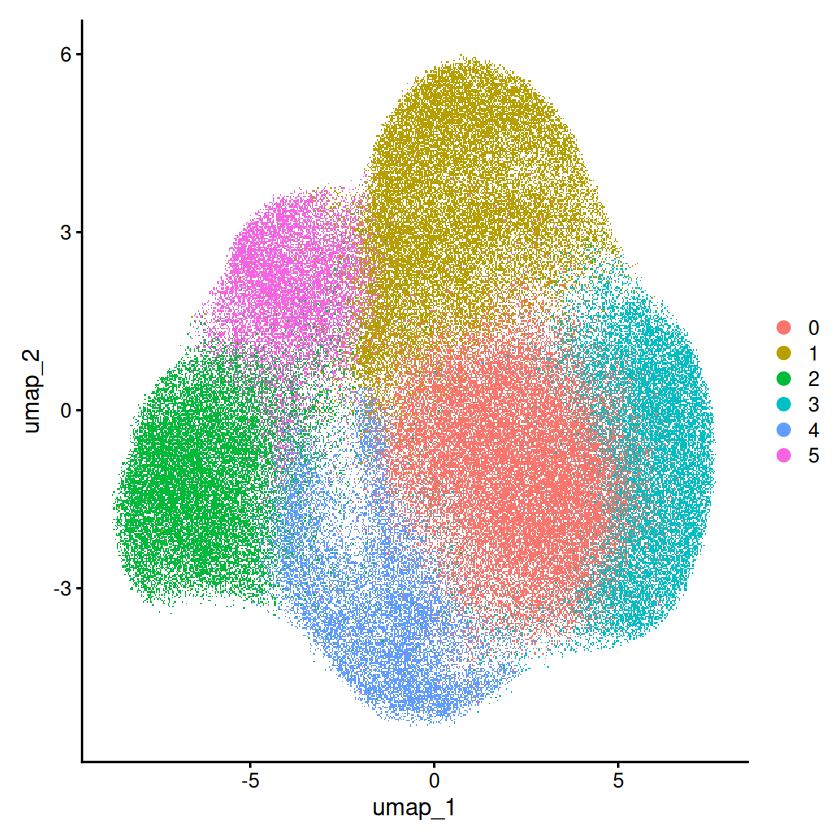

In [8]:
DimPlot(seu_cd4)

In [10]:
seu_cd4@meta.data  %>% colnames

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "sample_id"          "Patient"            "Disease"           
 [7] "Site"               "Treatment"          "Disease_duration"  
[10] "Inflammation"       "Age"                "Gender"            
[13] "Ethnicity"          "Inflammation_score" "Ileum_vs_Colon"    
[16] "LibraryType"        "CellsLoaded"        "Match"             
[19] "Batch"              "doublet_scores"     "predicted_doublets"
[22] "n_genes_by_counts"  "total_counts"       "total_counts_mt"   
[25] "pct_counts_mt"      "total_counts_rp"    "pct_counts_rp"     
[28] "total_counts_hb"    "pct_counts_hb"      "total_counts_ig"   
[31] "pct_counts_ig"      "S_score"            "G2M_score"         
[34] "phase"              "cellbarcode"        "diff"              
[37] "final_analysis"     "minor"              "major"             
[40] "sub_bucket"         "bucket"             "Remission_status"  
[43] "bc"                 "RNA_snn_res.0.3"    "seurat_clusters"

## STACAS integration

In [11]:
merged_ds <- SplitObject(seu_cd4, split.by = "Patient")
merged.list <- lapply(X = merged_ds, FUN = function(x) {
DefaultAssay(x)  <- "RNA"
x$barcode  <- colnames(x)
x <- NormalizeData(x)
x <- FindVariableFeatures(x, selection.method = "vst", nfeatures = 800)
})

gut_5p_integrated <- Run.STACAS(merged.list, dims = 1:12, k.weight = 70)
gut_5p_integrated <- RunUMAP(gut_5p_integrated, dims = 1:12) 
gut_5p_integrated <- FindNeighbors(gut_5p_integrated)
gut_5p_integrated <- FindClusters(gut_5p_integrated, res = c(0.5))

saveRDS(gut_5p_integrated, "data/published_data/thomas_integrated_cd4.rds")

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normal

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Merging dataset 26 into 29 11 5 17 9 3 10 1 36

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”

Integrating dataset 2 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 4 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 6 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 7 with reference dataset

Finding integration vectors

Finding integration vector weights



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 145704
Number of edges: 3694006

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8724
Number of communities: 10
Elapsed time: 93 seconds


In [3]:
gut_5p_integrated <- readRDS("../241201_VN_PREDICT2/data/published_data/thomas_integrated_cd4.rds")

In [4]:
gut_5p_integrated$Patient  %>% table  %>% length

[1] 41

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



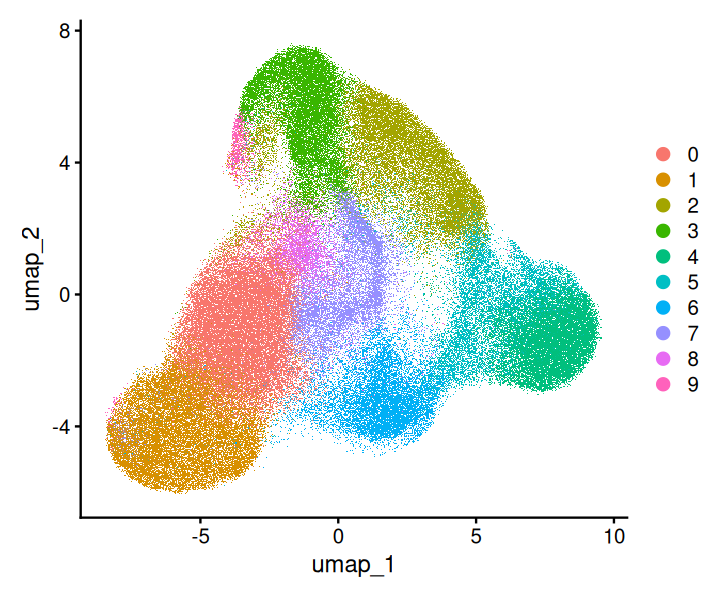

In [4]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(gut_5p_integrated)

In [4]:
gut_5p_integrated$cd4_ctl  <- ifelse(gut_5p_integrated$seurat_clusters == 6, "CTL","Other")
gut_5p_integrated$cd4_ctl  %>% table


.
   CTL  Other 
 11894 133810 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



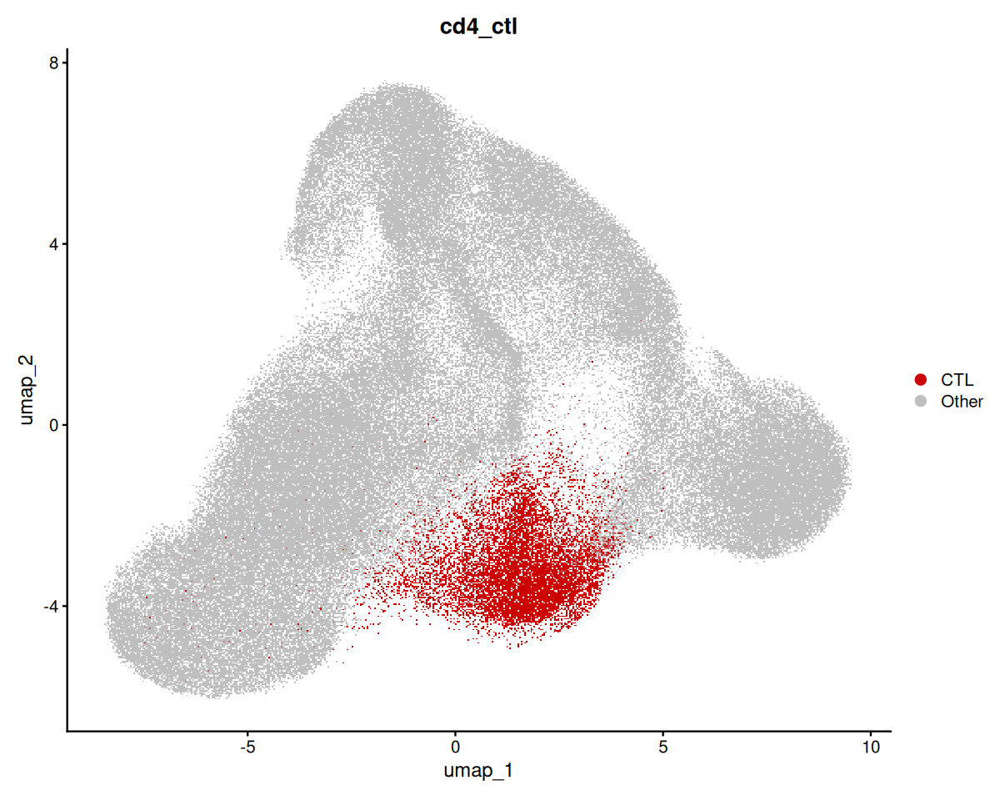

In [7]:
options(repr.plot.width = 10, repr.plot.height = 8)
DimPlot(gut_5p_integrated, group.by = "cd4_ctl", cols = c("#cd0000ff","grey75"))

In [29]:
cd4_ctl_sig  <- c(

    'GZMA', 'CTSH', 'IFNG', 'CCL4', 'HLA-DRB5', 'ZEB2', 'CHN1', 'IL12RB2', 'TESC', 'ADAM12', 'CPNE7', 'IL26',
    'GZMH', 'DAPK2', 'GZMB', 'COL5A3', 'OASL', 'NCR3', 'MCOLN2', 'GNLY', 'CSF2', 'MSC', 'GOLIM4', 
    'LINC02694', 'IL17A', 'GZMK', 'CDCA7', 'LINC00299', 'GPR34', 'LINC02384', 'FASLG', 'IL22', 'PKIG', 
    'APOBEC3H', 'PPARG', 'NUSAP1', 'SLC27A2', 'MSC-AS1', 'LYN', 'NTRK2', 'HDGFL3', 'MREG', 'MKI67', 
    'HLA-DQA2', 'KLRD1', 'SLAMF8', 'FSD1', 'TMPRSS3', 'PCLAF', 'TYMS', 'TOP2A', 'SETBP1', 'TOGARAM2', 'TPX2', 
    'IL17F', 'AL139393.3', 'PROK2', 'RHOU', 'MYO7A', 'EOMES', 'CENPE', 'TK1', 'KIF11', 'NCAPH', 'FCRL6', 'TIAM2', 
    'RRM2', 'CDK1', 'CDT1', 'RCAN2', 'SYNGR3', 'PALLD', 'BIRC5', 'ASPM', 'C3orf14', 'WWTR1', 'PLEKHG3', 'OTUB2', 
    'FES', 'ELOVL4', 'ADGRG5', 'CCNA2', 'UBE2C', 'EVC', 'KIFC1', 'TNS3', 'CD160', 'CCNB2', 'KIF23', 'AC243829.4', 
    'NCAPG', 'DOCK5', 'KIF2C', 'AC092580.4', 'P4HA2', 'CDCA2', 'PKMYT1', 'UHRF1', 'GTSE1', 'GPR27', 'DPF3', 
    'LINC02446', 'DLGAP5', 'ZNF683', 'CDC20', 'TROAP', 'AURKB', 'CEND1', 'CENPA', 'NMU', 'BUB1B', 'MELK', 'FOXM1', 
    'DEPDC1B', 'HMMR', 'CDCA5', 'CKAP2L', 'SHCBP1', 'RGS9', 'KIF14', 'KIF15', 'CDCA3', 'RAD51', 'PLK1', 'SPC25', 
    'CCR1', 'KIF4A', 'HJURP', 'NUGGC', 'PRR11', 'ESCO2', 'CDC45', 'MND1', 'TENM4', 'PIF1', 'HRH4', 'TP73', 'ADGRG1', 
    'PXDC1', 'SPC24', 'DIAPH3', 'E2F2', 'ANLN', 'MCM10', 'ATP8B4', 'SKA1', 'AL139393.2', 'DEPDC1', 'E2F8', 'SKA3', 
    'PDLIM4', 'GLDC', 'PBK', 'NCS1', 'KIF20A', 'TP63', 'CES1', 'KIF18B', 'HIST1H3G', 'KLHL13', 'HIST1H3C', 'BATF3', 
    'SOX5', 'E2F7', 'ARNTL2', 'CDC25A', 'ZBED2', 'MPPED2', 'FAM111B', 'GLB1L2', 'AL133405.2', 'NTRK1', 'FAM72B', 
    'TRPC3', 'AL356234.2', 'HMHB1', 'AC013460.1', 'CDC25C', 'KRT86', 'KLRC4', 'TYMSOS', 'KLRC1', 'ESPL1', 'ODAPH', 
    'RASGEF1A', 'PKHD1', 'KLRC2'
)

In [19]:
DefaultAssay(gut_5p_integrated)  <- "RNA"
cd4_ctl_sig_filt  <- cd4_ctl_sig[which(cd4_ctl_sig %in% rownames(gut_5p_integrated@assays$RNA))]
gut_5p_integrated  <- AddModuleScore(gut_5p_integrated, features = list(cd4_ctl_sig),
  name     = "CTL_score")

Warning message:
“The following features are not present in the object: LINC02694, AL139393.3, AC092580.4, AL133405.2, AC013460.1, TYMSOS, not searching for symbol synonyms”


In [ ]:
gut_5p_integrated_umap  <- gut_5p_integrated@reductions$umap@cell.embeddings
gut_5p_integrated$UMAP_1  <- gut_5p_integrated_umap[,1]
gut_5p_integrated$UMAP_2  <- gut_5p_integrated_umap[,2]

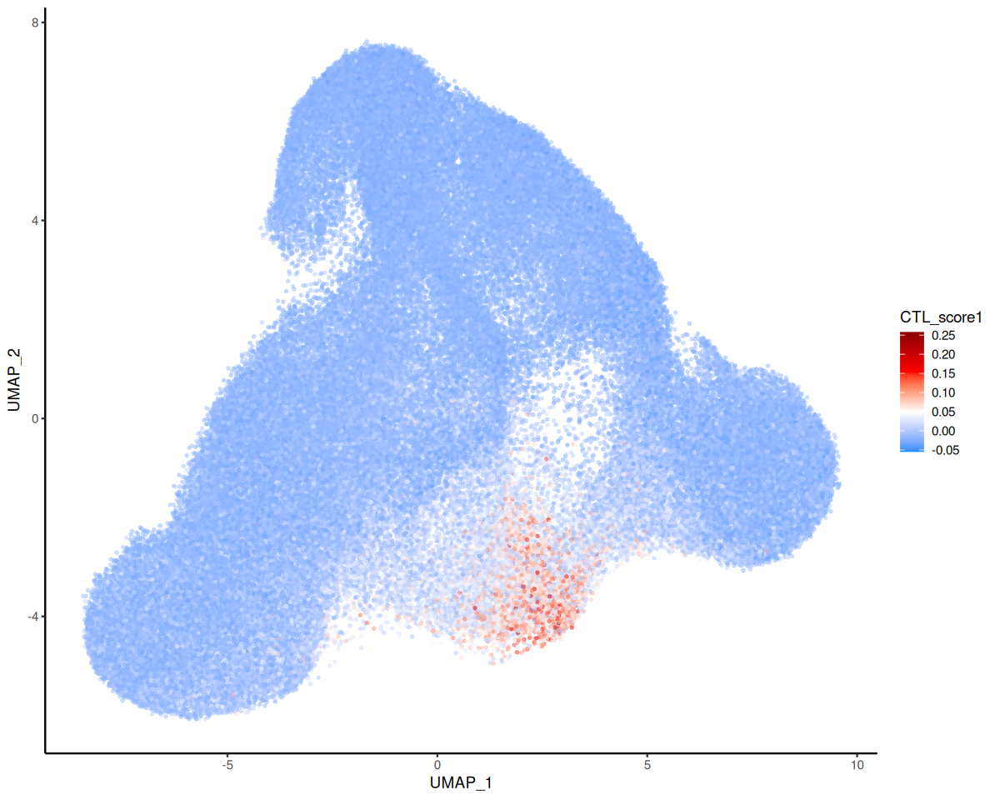

In [36]:
options(repr.plot.width = 10, repr.plot.height = 8)
gut_5p_integrated@meta.data  %>% 
ggplot(aes(x = UMAP_1, y = UMAP_2)) +
geom_point(aes(color = CTL_score1), alpha = 0.4, size = 0.5) +
theme_classic() +
scale_colour_gradientn(
    colours = c("dodgerblue", "white", "red","darkred"),
    #rescaler = ~ scales::rescale_mid(.x, mid = 0)
  )

## Marker heatmap

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



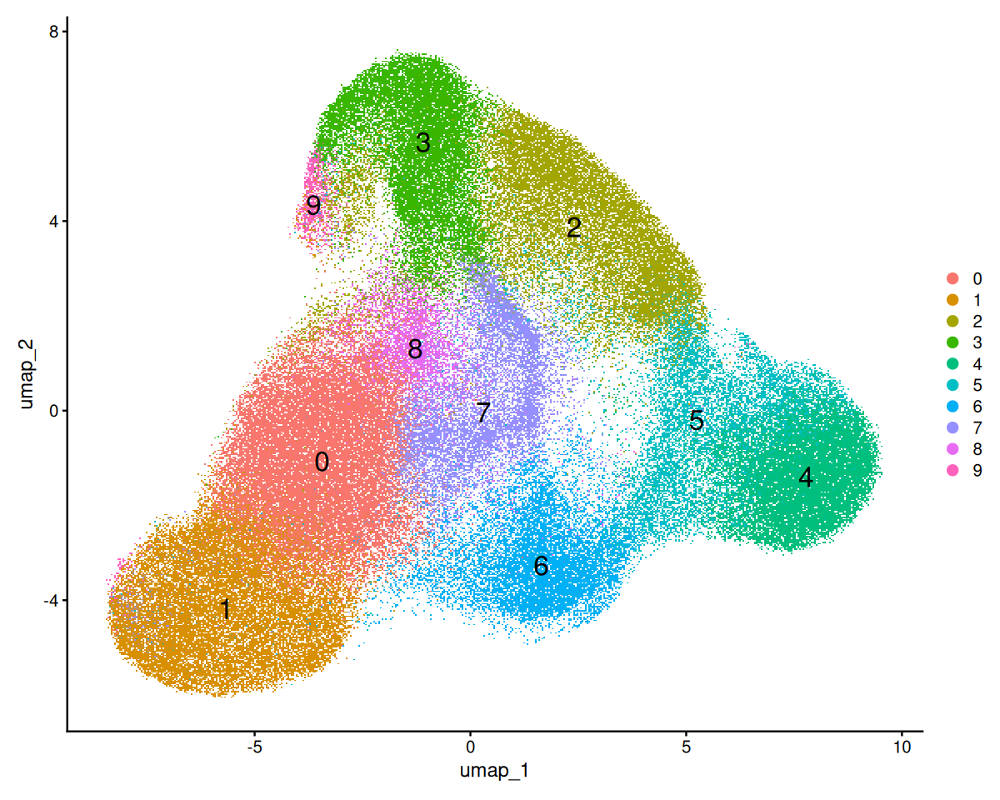

In [47]:
DimPlot(gut_5p_integrated, label = T, label.size = 7)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



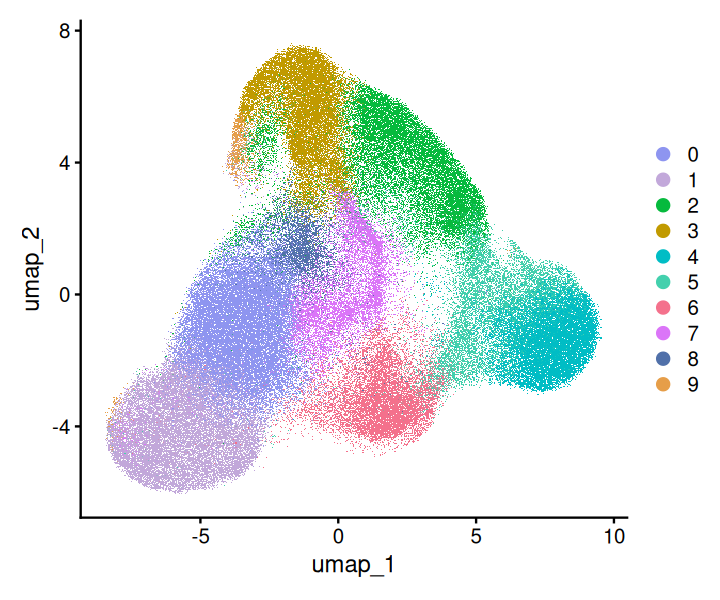

In [53]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(gut_5p_integrated) + 
scale_color_manual(values = c("0" = "#8e95f0ff",
                          "1" = "#c2a8daff",
                          "2" = "#06ba3dff",
                          "3" = "#c19a00ff",
                          "4" = "#00bdc5ff",
                          "5" = "#43d0adff",
                          "6" = "#f4718cff",
                          "7" = "#db75f8ff",
                          "8" = "#5070a9ff",
                          "9" = "#e69e49ff"
                          ))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



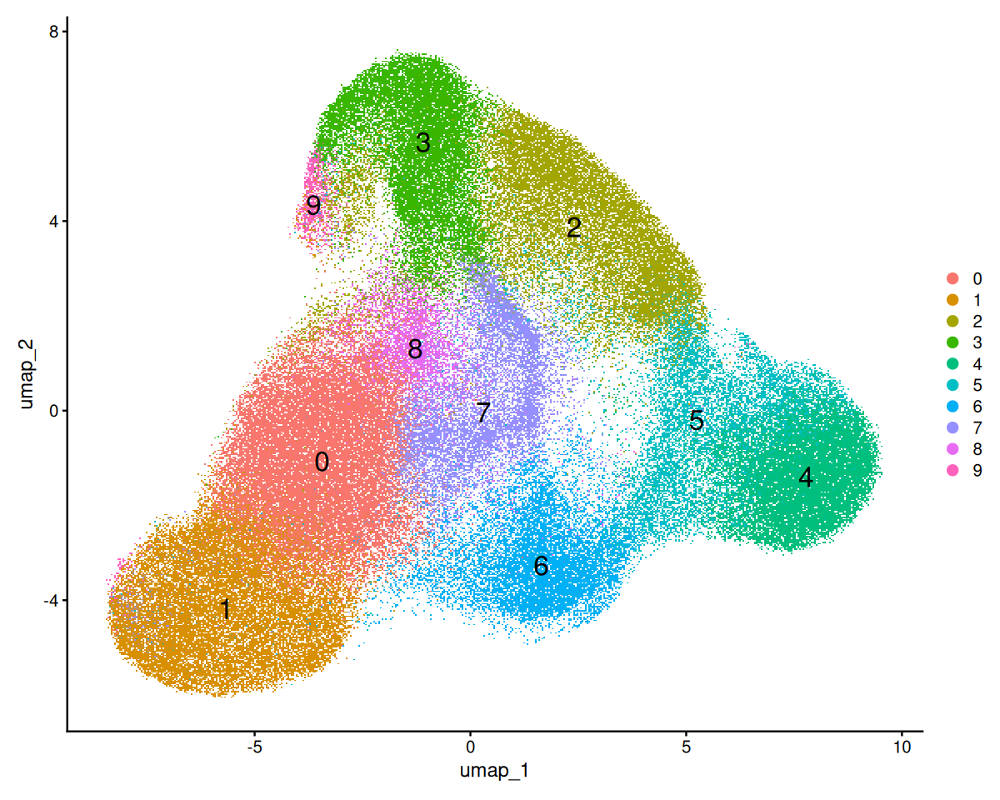

In [47]:
DimPlot(gut_5p_integrated, label = T, label.size = 7)

In [61]:
gn2  <- c('GZMA', 'GZMB','GZMH','GNLY', 'IFNG', "PRF1",'CTSH', 
          'HLA-DRB5','FASLG',  'ZEB2',"RORC","TBX21","EOMES","BHLHE40",
          "IL23R",
          'IL12RB2', "CXCR6",
          'IL26', 'IL17A','IL22','CCL4', 'CSF2')


In [64]:
## Marker genes
avgexp3 = AverageExpression(gut_5p_integrated, features = gn2, group.by = "seurat_clusters",
                          assay = "RNA")
colnames(avgexp3$RNA)  <- gsub(colnames(avgexp3$RNA), pattern = "g", replacement = "")

In [67]:
dir.create("figures/heatmaps_other_data")

In [68]:
options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 14, filename = "figures/heatmaps_other_data/thomas.pdf",
                  width = 5, height = 7)

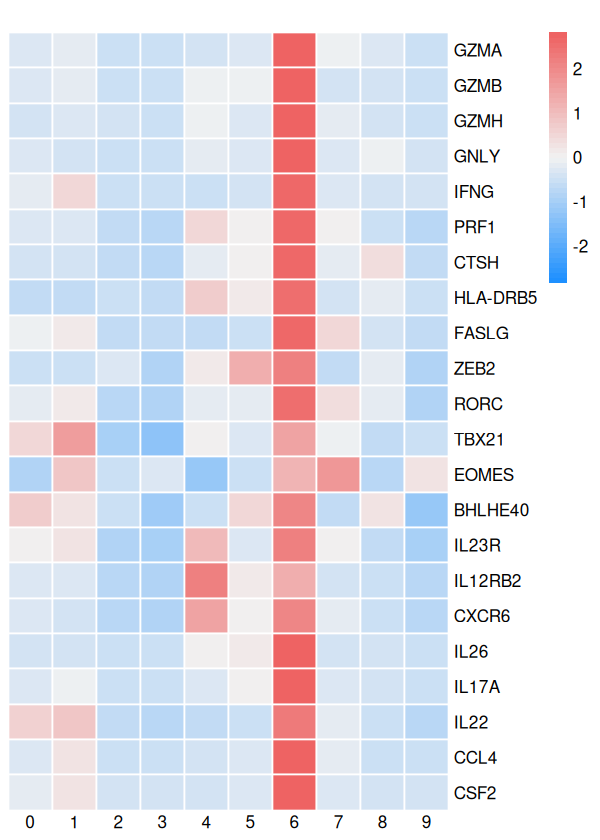

In [70]:
options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white")

## Frequencies

In [5]:
md <- gut_5p_integrated@meta.data
df4 <- md %>% group_by(sample_id, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!sample_id, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(Remission_status, Inflammation, 
                                   Treatment, Site, Disease, sample_id, Patient) %>% unique()
df4  <- left_join(df4, md_to_join, by = "sample_id")


`summarise()` has grouped output by 'sample_id'. You can override using the
`.groups` argument.


In [6]:
df4

sample_id,seurat_clusters,freq,Remission_status,Inflammation,Treatment,Site,Disease,Patient
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CID003352-2,0,0.210810811,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,1,0.059459459,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,2,0.091891892,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,3,0.023783784,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,4,0.212972973,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,5,0.190270270,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,6,0.105945946,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,7,0.022702703,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,8,0.081081081,Non_Remission,Inflamed,Post,Rectum,UC,UC1


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


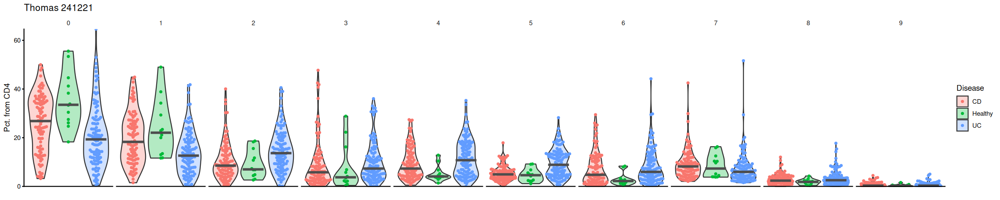

In [7]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") )

df_filt  %>% 
ggplot(aes(x = Disease, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas 241221")


#ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(1,4)), label = "p.signif") +
#stat_pvalue_manual(
#    stat_test, label = "p.label", 
    #y.position = 60,
#    remove.bracket = TRUE
 #   ) + 
#ggtheme()

In [8]:
gut_5p_integrated@meta.data  %>% colnames

[1] "orig.ident"             "nCount_RNA"             "nFeature_RNA"          
 [4] "sample_id"              "Patient"                "Disease"               
 [7] "Site"                   "Treatment"              "Disease_duration"      
[10] "Inflammation"           "Age"                    "Gender"                
[13] "Ethnicity"              "Inflammation_score"     "Ileum_vs_Colon"        
[16] "LibraryType"            "CellsLoaded"            "Match"                 
[19] "Batch"                  "doublet_scores"         "predicted_doublets"    
[22] "n_genes_by_counts"      "total_counts"           "total_counts_mt"       
[25] "pct_counts_mt"          "total_counts_rp"        "pct_counts_rp"         
[28] "total_counts_hb"        "pct_counts_hb"          "total_counts_ig"       
[31] "pct_counts_ig"          "S_score"                "G2M_score"             
[34] "phase"                  "cellbarcode"            "diff"                  
[37] "final_analysis"         "minor"                  "major"                 
[40] "sub_bucket"             "bucket"                 "Remission_status"      
[43] "bc"                     "RNA_snn_res.0.3"        "seurat_clusters"       
[46] "barcode"                "integrated_snn_res.0.5"

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


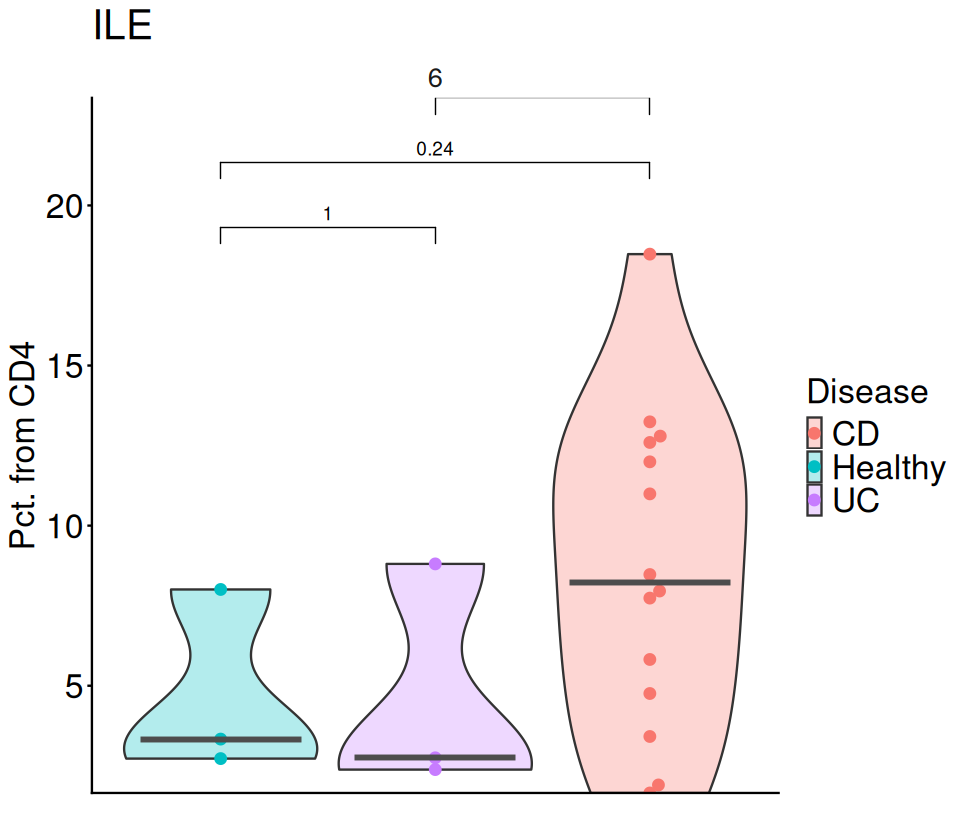

In [9]:
options(repr.plot.width = 8, repr.plot.height = 7)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & 
              Site == "Terminal_Ileum" & seurat_clusters == 6 & (is.na(Treatment)|Treatment == "Pre"))

df_filt  %>% 
ggplot(aes(x = factor(Disease, levels = c("Healthy","UC","CD")),
           y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
scale_color_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
scale_fill_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "ILE") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.format") +
 
ggtheme()

In [10]:
#ggsave("figures/thomas/cd4_freq_violin_ile.svg", width = 10, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Warning message in wilcox.test.default(c(1.20481927710843, 1.75438596491228, 8.33333333333333:
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(21.9178082191781, 1.17252931323283, 7.3490813648294, :
“cannot compute exact p-value with ties”


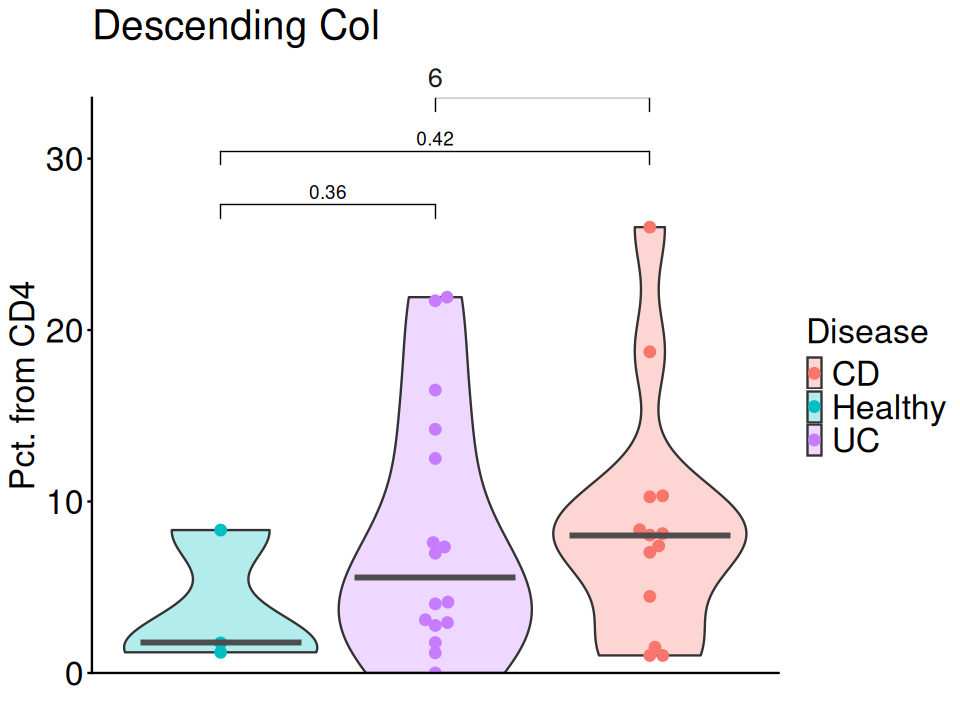

In [11]:
options(repr.plot.width = 8, repr.plot.height = 6)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & 
              Site %in% c("Descending_Colon") & seurat_clusters == 6 & (is.na(Treatment)|Treatment == "Pre"))

df_filt  %>% 
ggplot(aes(x = factor(Disease, levels = c("Healthy","UC","CD")),
           y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
scale_color_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
scale_fill_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Descending Col") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.format") +
 
ggtheme()

#ggsave("figures/thomas/cd4_freq_violin_desc_colon.svg", width = 10, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


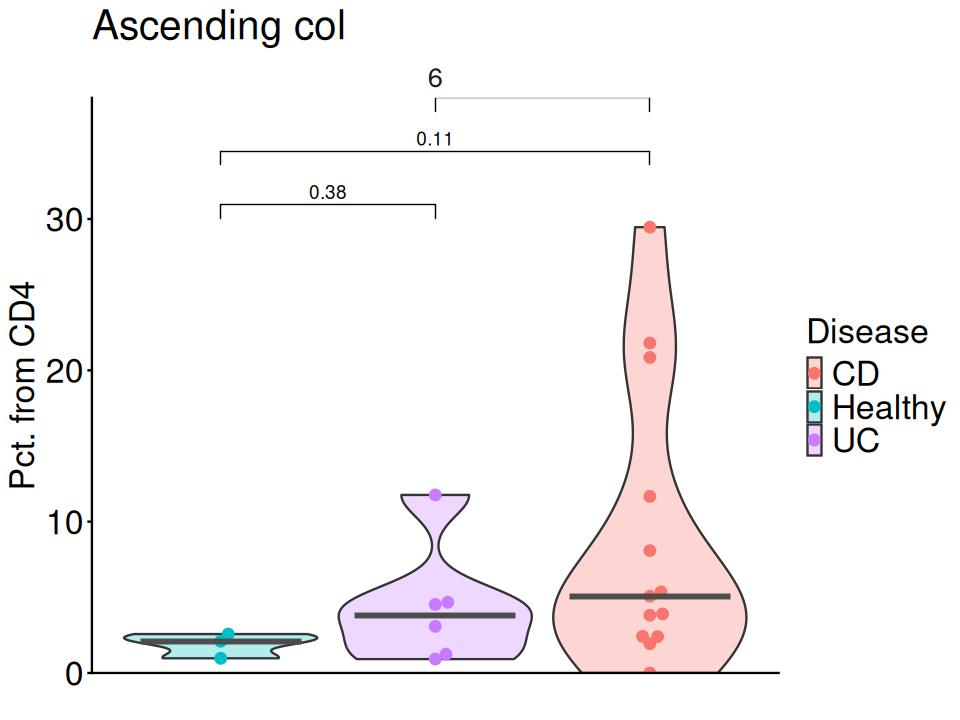

In [12]:
options(repr.plot.width = 8, repr.plot.height = 6)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & 
              Site %in% c("Ascending_Colon") & seurat_clusters == 6 & (is.na(Treatment)|Treatment == "Pre"))

df_filt  %>% 
ggplot(aes(x = factor(Disease, levels = c("Healthy","UC","CD")),
           y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
scale_color_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
scale_fill_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Ascending col") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.format") +
 
ggtheme()

In [13]:
#ggsave("figures/thomas/cd4_freq_violin_asc_colon.svg", width = 10, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


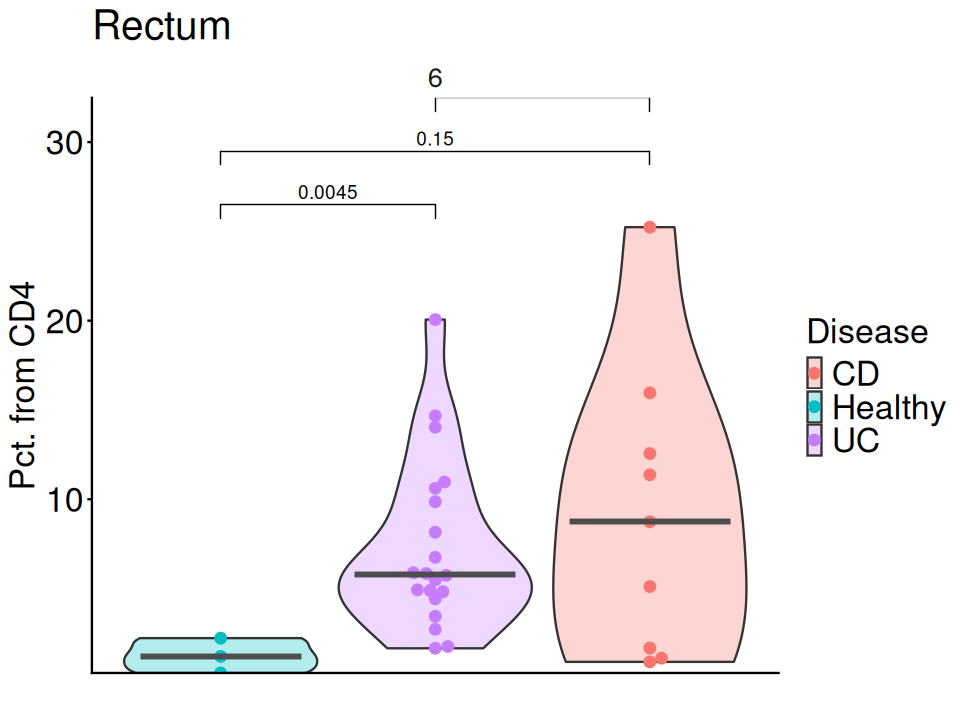

In [14]:
options(repr.plot.width = 8, repr.plot.height = 6)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & 
              Site == "Rectum" & seurat_clusters == 6 & (is.na(Treatment)|Treatment == "Pre"))

df_filt  %>% 
ggplot(aes(x = factor(Disease, levels = c("Healthy","UC","CD")),
           y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
scale_color_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
scale_fill_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Rectum") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.format") +
 
ggtheme()

In [15]:
#ggsave("figures/thomas/cd4_freq_violin_rectum.svg", width = 10, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


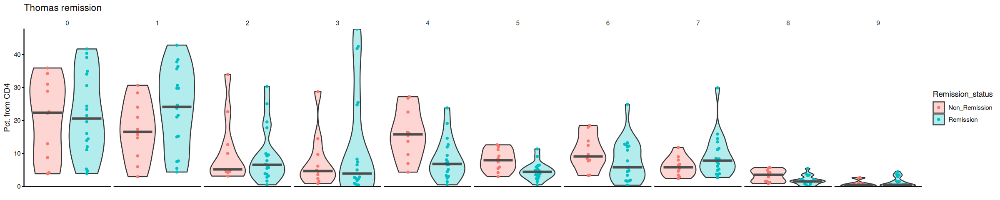

In [16]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum")

df_filt  %>% 
ggplot(aes(x = Remission_status, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Remission_status), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Remission_status), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas remission") +
ggpubr::stat_compare_means(label = "p.signif") 
#stat_pvalue_manual(
#    stat_test, label = "p.label", 
    #y.position = 60,
#    remove.bracket = TRUE
 #   ) + 
#ggtheme()

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


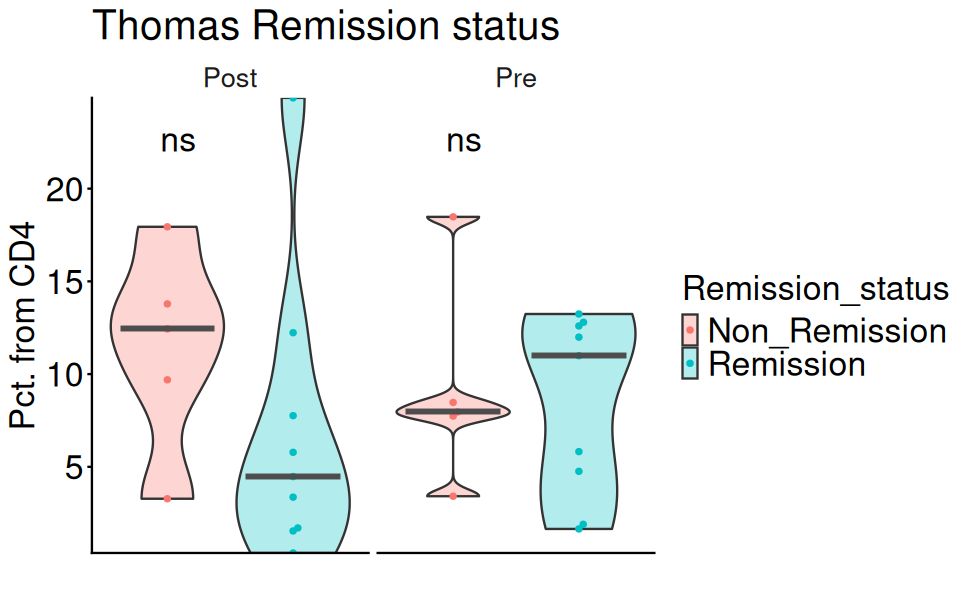

In [17]:
options(repr.plot.width = 8, repr.plot.height = 5)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum" & seurat_clusters == 6)

df_filt  %>% 
ggplot(aes(x = Remission_status, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Remission_status), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Remission_status), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~Treatment) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas Remission status") +
ggtheme() +
ggpubr::stat_compare_means(label = "p.signif", size = 7, label.y = 22) 


In [19]:
df4

sample_id,seurat_clusters,freq,Remission_status,Inflammation,Treatment,Site,Disease,Patient
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CID003352-2,0,0.210810811,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,1,0.059459459,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,2,0.091891892,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,3,0.023783784,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,4,0.212972973,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,5,0.190270270,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,6,0.105945946,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,7,0.022702703,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,8,0.081081081,Non_Remission,Inflamed,Post,Rectum,UC,UC1


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


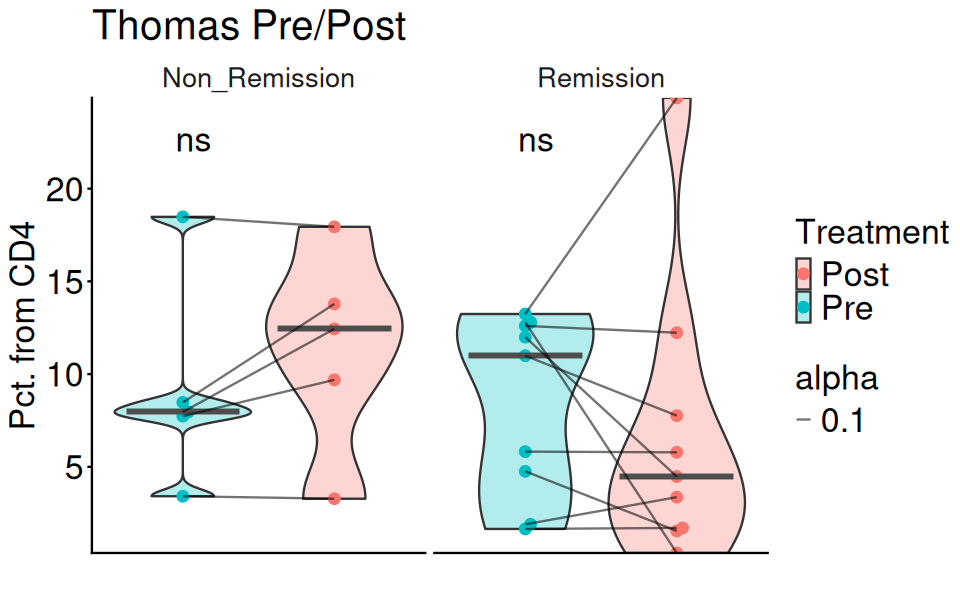

In [22]:
options(repr.plot.width = 8, repr.plot.height = 5)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum" & seurat_clusters == 6)

df_filt  %>% 
mutate(Donor_Rem = paste(Patient, Remission_status))  %>% 
ggplot(aes(x = factor(Treatment, levels = c("Pre","Post")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Treatment), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Treatment), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~Remission_status) +
  ylab("Pct. from CD4") +
  xlab("") +
geom_line(aes(group = Donor_Rem, alpha = 0.1)) +

  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas Pre/Post") +
ggtheme() +
ggpubr::stat_compare_means(label = "p.signif", size = 7, label.y = 22, paired = TRUE) 


In [24]:
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum" & seurat_clusters == 6)

df_filt  %>% 
mutate(Donor_Rem = paste(Patient, Remission_status))  %>% 
ungroup  %>% 
dplyr::select(-sample_id, -Inflammation)  %>% 
pivot_wider(names_from = Treatment, values_from = freq)  %>% 
mutate(PrePost = Pre/Post)  


seurat_clusters,Remission_status,Site,Disease,Patient,Donor_Rem,Post,Pre,PrePost
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
6,Non_Remission,Terminal_Ileum,CD,CD1,CD1 Non_Remission,0.137850467,0.08472554,0.6146191
6,Non_Remission,Terminal_Ileum,CD,CD2,CD2 Non_Remission,0.032800000,0.03414859,1.0411156
6,Non_Remission,Terminal_Ileum,CD,CD3,CD3 Non_Remission,0.124365482,0.07957560,0.6398528
6,Remission,Terminal_Ileum,CD,CD4,CD4 Remission,0.248945148,0.13241617,0.5319090
6,Remission,Terminal_Ileum,CD,CD5,CD5 Remission,0.003553299,0.12795549,36.0103318
6,Remission,Terminal_Ileum,CD,CD8,CD8 Remission,0.057823129,0.05820106,1.0065359
6,Remission,Terminal_Ileum,CD,CD9,CD9 Remission,0.033653846,0.01901469,0.5650080
6,Remission,Terminal_Ileum,CD,CD10,CD10 Remission,0.122314050,0.12597777,1.0299534
6,Non_Remission,Terminal_Ileum,CD,CD11,CD11 Non_Remission,0.096907216,0.07736721,0.7983637


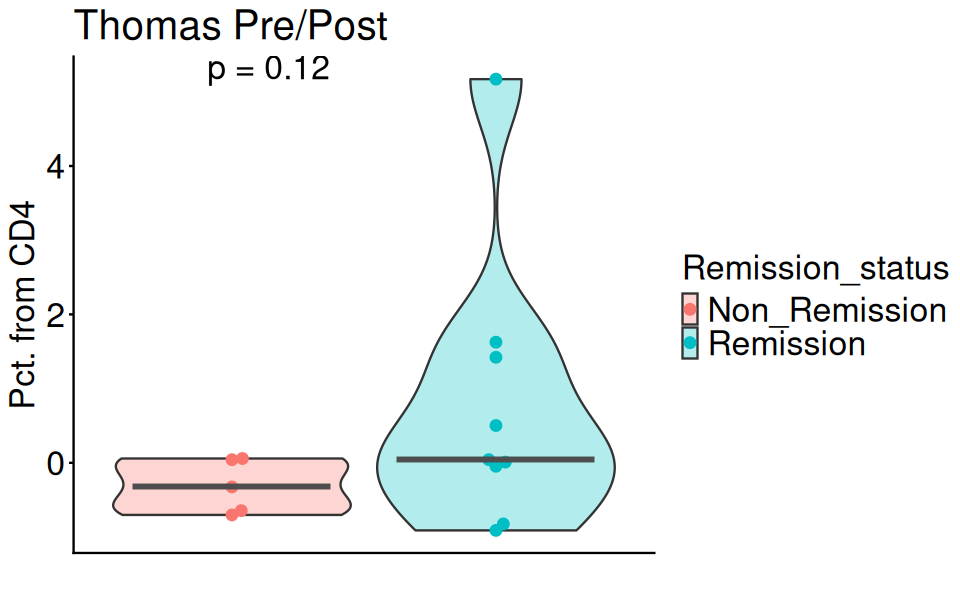

In [23]:
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum" & seurat_clusters == 6)

df_filt  %>% 
mutate(Donor_Rem = paste(Patient, Remission_status))  %>% 
ungroup  %>% 
dplyr::select(-sample_id, -Inflammation)  %>% 
pivot_wider(names_from = Treatment, values_from = freq)  %>% 
mutate(PrePost = Pre/Post)   %>% 
mutate(LogPrePost = log(Pre/Post, base = 2))   %>% 

#dplyr::filter(PrePost<30)  %>% 
ggplot(aes(x = Remission_status, y = LogPrePost)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Remission_status), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Remission_status), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  ylab("Log2FC Pre/Post") +
  xlab("") +
#  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
#  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas Pre/Post") +
ggtheme() +
ggpubr::stat_compare_means(label = "p.format", size = 7, method = "t.test") 

In [ ]:
ggsave('figures/thomas_new_prepost.svg', width = )

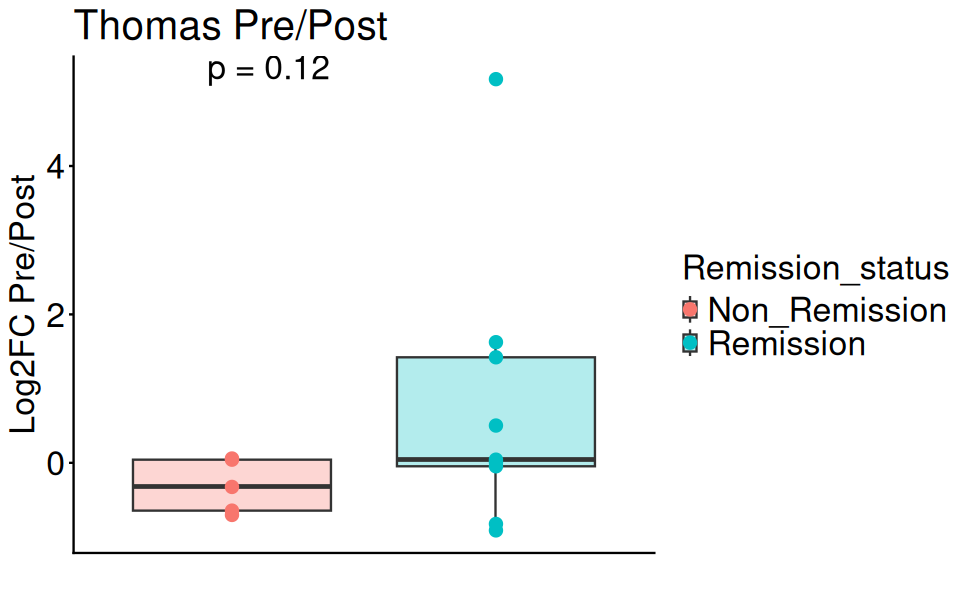

In [26]:
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum" & seurat_clusters == 6)

df_filt  %>% 
mutate(Donor_Rem = paste(Patient, Remission_status))  %>% 
ungroup  %>% 
dplyr::select(-sample_id, -Inflammation)  %>% 
pivot_wider(names_from = Treatment, values_from = freq)  %>% 
mutate(PrePost = Pre/Post)   %>% 
mutate(LogPrePost = log(Pre/Post, base = 2))   %>% 

#dplyr::filter(PrePost<30)  %>% 
ggplot(aes(x = Remission_status, y = LogPrePost)) + # you can change the x to whatever variable you're interested in
   geom_boxplot(alpha = 0.3, aes(fill = Remission_status), outlier.shape = NA) + 
 geom_point(size = 3, aes(color = Remission_status)) +
  ylab("Log2FC Pre/Post") +
  xlab("") +
#  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
#  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas Pre/Post") +
ggtheme() +
ggpubr::stat_compare_means(label = "p.format", size = 7, method = "t.test") 

In [27]:
ggsave("figures/thomas/rev_cd4_freq_pre_post.svg", width = 12, height = 9, 
       units = "cm", create.dir = TRUE)

✔ Created directory: figures/thomas.



In [ ]:
options(repr.plot.width = 8, repr.plot.height = 5)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum" & seurat_clusters == 6)

df_filt  %>% 
mutate(Donor_Rem = paste(Patient, Remission_status))  %>% 
ggplot(aes(x = factor(Treatment, levels = c("Pre","Post")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Treatment), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Treatment), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~Remission_status) +
  ylab("Pct. from CD4") +
  xlab("") +
geom_line(aes(group = Donor_Rem, alpha = 0.1)) +

  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas Pre/Post") +
ggtheme() +
ggpubr::stat_compare_means(label = "p.signif", size = 7, label.y = 22, paired = TRUE) 


In [136]:
#ggsave("figures/thomas/cd4_freq_pre_post.svg", width = 12, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


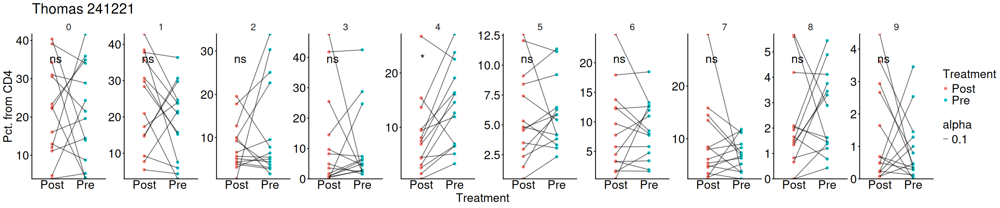

In [65]:
options(repr.plot.width = 24, repr.plot.height = 5)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum")

df_filt  %>% 
mutate(Donor_Rem = paste(Patient, Remission_status))  %>% 
ggplot(aes(x = Treatment, y = freq*100)) + # you can change the x to whatever variable you're interested in
  # geom_violin(alpha = 0.3, aes(fill = Remission_status), scale = "width") + 
 geom_point(aes(color = Treatment)) +
geom_line(aes(group = Donor_Rem, alpha = 0.1)) +

  ylab("Pct. from CD4") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  facet_wrap(~seurat_clusters, scales = "free", ncol = 10) +

  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank()) + ggtitle(label = "Thomas 241221") +
ggtheme() +
ggpubr::stat_compare_means(label = "p.signif", size = 7, label.y.npc = 0.8) 


In [25]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


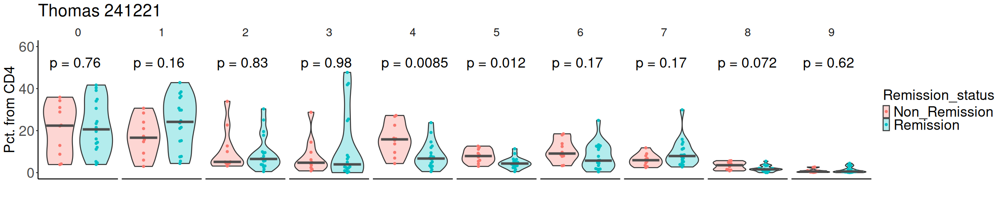

In [26]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum")

df_filt  %>% 
ggplot(aes(x = Remission_status, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Remission_status), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Remission_status), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,60)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,70))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas 241221") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.y = 50) +
ggtheme()

# Elmantaite et al.

In [5]:
Convert("../240318_VN_scvi_integration_CTL/teich_data_without_md.h5ad", dest = "h5seurat", overwrite = TRUE)

Warning message:
“Unknown file type: h5ad”
Warning message:
“'assay' not set, setting to 'RNA'”
Creating h5Seurat file for version 3.1.5.9900

Adding X as data

Adding X as counts

Adding meta.features from var

Adding X_pca as cell embeddings for pca

Adding X_umap as cell embeddings for umap

Adding annotation_colors to miscellaneous data



In [4]:
teich <- LoadH5Seurat("../240318_VN_scvi_integration_CTL/teich_data_without_md.h5seurat")
teich

Validating h5Seurat file

Initializing RNA with data

Adding counts for RNA

Adding feature-level metadata for RNA

Adding reduction pca

Adding cell embeddings for pca

Adding miscellaneous information for pca

Adding reduction umap

Adding cell embeddings for umap

Adding miscellaneous information for umap

Adding command information

Adding cell-level metadata

Adding miscellaneous information

Adding tool-specific results



An object of class Seurat 
30282 features across 38633 samples within 1 assay 
Active assay: RNA (30282 features, 0 variable features)
 2 dimensional reductions calculated: pca, umap

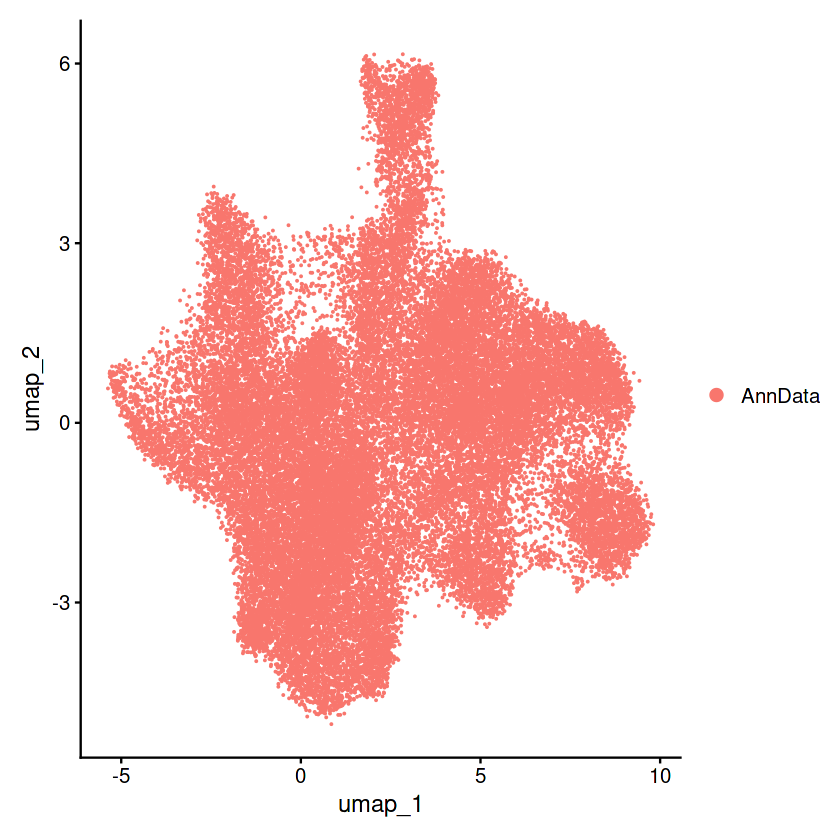

In [5]:
DimPlot(teich)

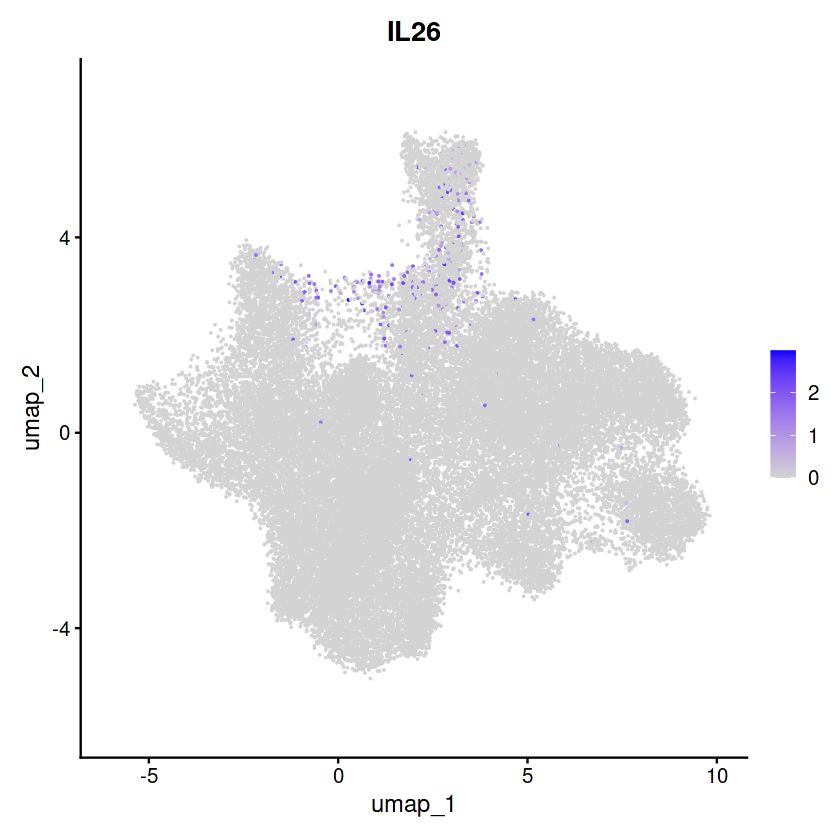

In [6]:
FeaturePlot(teich, features = "IL26")

In [7]:
teich_md  <- read_csv("../240318_VN_scvi_integration_CTL/teich_metadata.csv")

New names:
• `` -> `...1`
Rows: 38633 Columns: 23
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (14): ...1, Sample name, Diagnosis, Age, sample name, Region code, Fract...
dbl  (8): n_genes, n_genes_by_counts, total_counts, total_counts_mt, pct_cou...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [8]:
teich_md$barcode  <- teich_md$`...1`

In [9]:
teich_md

...1,Sample name,Diagnosis,Age,sample name,Region code,Fraction,Region,10X,batch,⋯,pct_counts_mt,doublet_scores,predicted_doublets,S_score,G2M_score,phase,productive,annotation,Gender,barcode
GCGCGATCATCACAAC-1-FCA_gut9456313,BRC2258,fetal,11.1Wk,C74-FPIL-0-SC-1 G,FPIL,SC,SmallInt,5',FCA_gut9456313,⋯,3.025002,0.04286418,FALSE,-0.018175960,-0.2100376,G1,nan,ILCP,M,GCGCGATCATCACAAC-1-FCA_gut9456313
TGCTACCCAACACCCG-1-Human_colon_16S8117828,A26 (386C),Healthy adult,70-75,A26-MLN-0-SC-1,MLN,SC,lymph node,5',Human_colon_16S8117828,⋯,6.276847,0.07694563,FALSE,0.076894880,-0.2085313,S,nan,NK cell,F,TGCTACCCAACACCCG-1-Human_colon_16S8117828
GCGCGATTCCCGACTT-1-FCA_gut9456316,BRC2258,fetal,11.1Wk,C74-FMIL-0-SC-1 G,FMIL,SC,SmallInt,5',FCA_gut9456316,⋯,11.602434,0.05228982,FALSE,0.009943746,-0.2034998,S,nan,LTi-like NCR- ILC3,M,GCGCGATTCCCGACTT-1-FCA_gut9456316
AAACCTGCAGGGTACA-1-FCA_gut8015061,F78,fetal,17Wk,F78-MLN-0-SC-1,FMLN,SC,lymph node,5',FCA_gut8015061,⋯,27.034733,0.02028169,FALSE,-0.025287226,-0.2028289,G1,nan,SELL+ CD8 T,M,AAACCTGCAGGGTACA-1-FCA_gut8015061
CACCACTTCTTGTATC-1-Human_colon_16S8117828,A26 (386C),Healthy adult,70-75,A26-MLN-0-SC-1,MLN,SC,lymph node,5',Human_colon_16S8117828,⋯,12.158421,0.04479469,FALSE,-0.062045548,-0.1976530,G1,nan,NK cell,F,CACCACTTCTTGTATC-1-Human_colon_16S8117828
GTTCTCGAGTGTACGG-1-Human_colon_16S8159192,A32 (411C),Healthy adult,25-30,A32-APD-0-SC-45P-1,APD,SC-45P,APD,5',Human_colon_16S8159192,⋯,10.528342,0.02604313,FALSE,-0.018435776,-0.1950793,G1,nan,Activated CD8 T,M,GTTCTCGAGTGTACGG-1-Human_colon_16S8159192
ATTATCCTCTTCCTTC-1-Human_colon_16S8159186,F72,fetal,16Wk,F72-MLN-0-SC-1,FMLN,SC,lymph node,5',Human_colon_16S8159186,⋯,1.925593,0.05289673,FALSE,0.008879349,-0.1948518,S,True,SELL+ CD4 T,F,ATTATCCTCTTCCTTC-1-Human_colon_16S8159186
GACTACAAGGCTATCT-1-Human_colon_16S8159189,F73,fetal,15Wk,F73-FTIL-0-SC-1,FTIL,SC,SmallInt,5',Human_colon_16S8159189,⋯,8.831669,0.03092784,FALSE,-0.035578746,-0.1939151,G1,nan,LTi-like NCR- ILC3,F,GACTACAAGGCTATCT-1-Human_colon_16S8159189
AAATGCCGTTGAACTC-1-4918STDY7274839,T024,Pediatric healthy,12,T024-TIL-SC-EPCAMP,TIL,SC-EPCAMP,SmallInt,3',4918STDY7274839,⋯,10.854692,0.08292683,FALSE,-0.010797385,-0.1921053,G1,nan,Activated CD8 T,F,AAATGCCGTTGAACTC-1-4918STDY7274839
CACATTTTCCAGAGGA-1-4918STDY7273964,T017,Pediatric Crohn Disease,13,T017-TIL-SC-EPCAMP,TIL,SC-EPCAMP,SmallInt,3',4918STDY7273964,⋯,3.151689,0.03401843,FALSE,0.038065426,-0.1896383,S,nan,Th1,M,CACATTTTCCAGAGGA-1-4918STDY7273964


In [10]:
colnames(teich)  %>% head

[1] "GCGCGATCATCACAAC-1-FCA_gut9456313"        
[2] "TGCTACCCAACACCCG-1-Human_colon_16S8117828"
[3] "GCGCGATTCCCGACTT-1-FCA_gut9456316"        
[4] "AAACCTGCAGGGTACA-1-FCA_gut8015061"        
[5] "CACCACTTCTTGTATC-1-Human_colon_16S8117828"
[6] "GTTCTCGAGTGTACGG-1-Human_colon_16S8159192"

In [11]:
teich$barcode  <- colnames(teich)

In [12]:
teich@meta.data  <- teich@meta.data  %>% left_join(teich_md)

Joining with `by = join_by(barcode)`


In [13]:
rownames(teich@meta.data)  <- colnames(teich)

In [14]:
colnames(teich@meta.data)

[1] "barcode"            "...1"               "Sample name"       
 [4] "Diagnosis"          "Age"                "sample name"       
 [7] "Region code"        "Fraction"           "Region"            
[10] "10X"                "batch"              "n_genes"           
[13] "n_genes_by_counts"  "total_counts"       "total_counts_mt"   
[16] "pct_counts_mt"      "doublet_scores"     "predicted_doublets"
[19] "S_score"            "G2M_score"          "phase"             
[22] "productive"         "annotation"         "Gender"

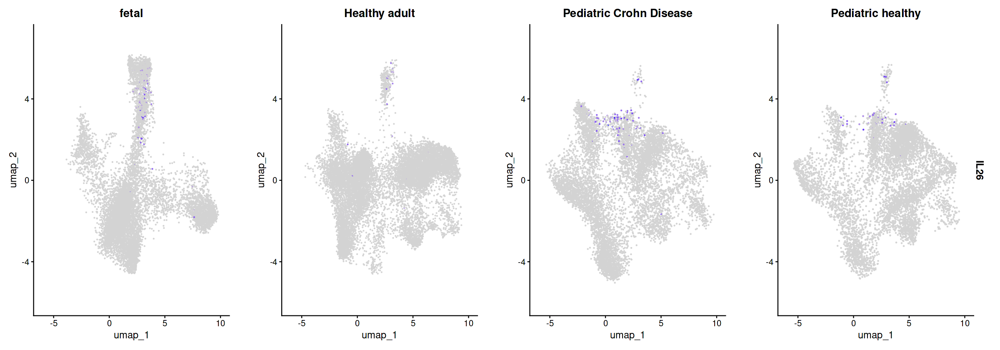

In [15]:
options(repr.plot.width = 20)
FeaturePlot(teich, features = "IL26", split.by = "Diagnosis")

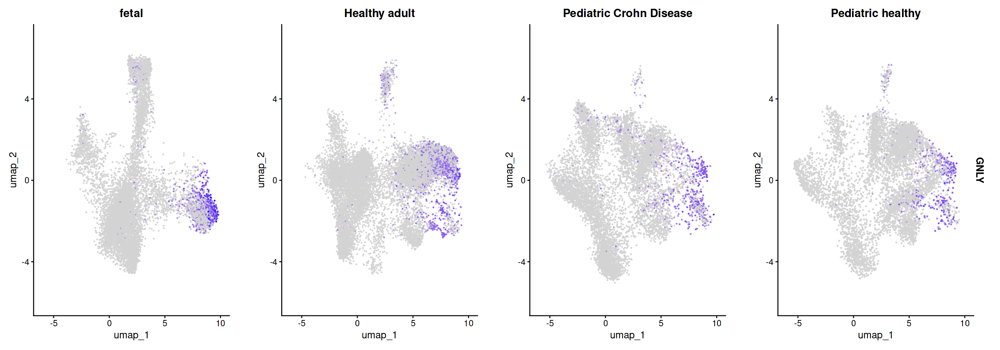

In [16]:
FeaturePlot(teich, features = "GNLY", split.by = "Diagnosis")

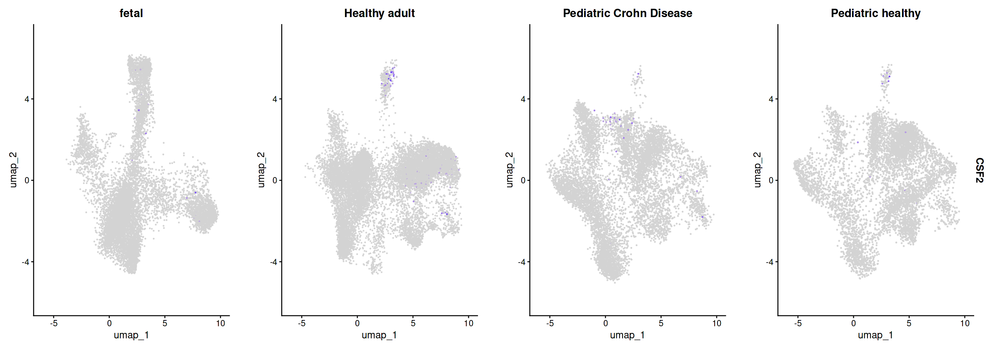

In [17]:
FeaturePlot(teich, features = "CSF2", split.by = "Diagnosis")

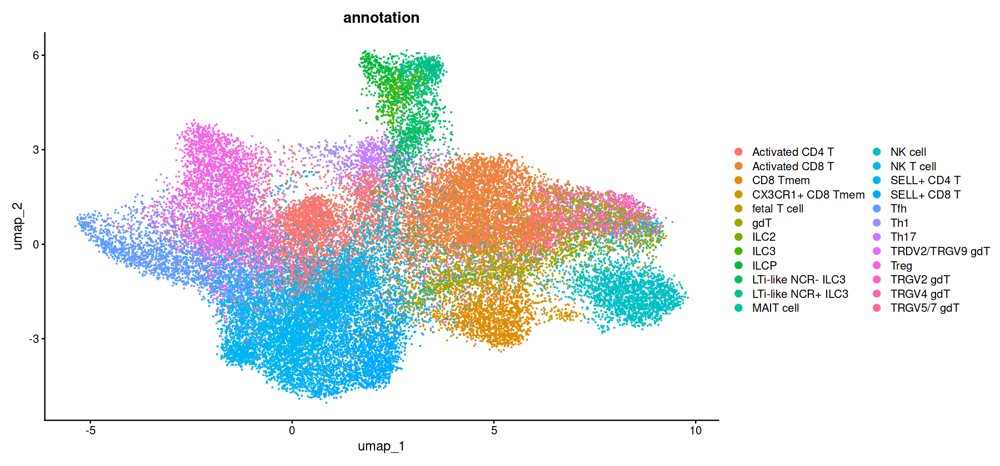

In [18]:
options(repr.plot.width = 15)

DimPlot(teich, group.by = "annotation")

## Just CD4 T cells

In [5]:
teich_subset <- readRDS("../240202_VN_CD4_CTL_integration/old_data/teich_subset.rds")

In [6]:
teich_cd4  <- subset(teich_subset, annotation %in% c("Activated CD4 T", "SELL+ CD4 T",
                                                     "Tfh", "Th1", "Th17", "Treg"))

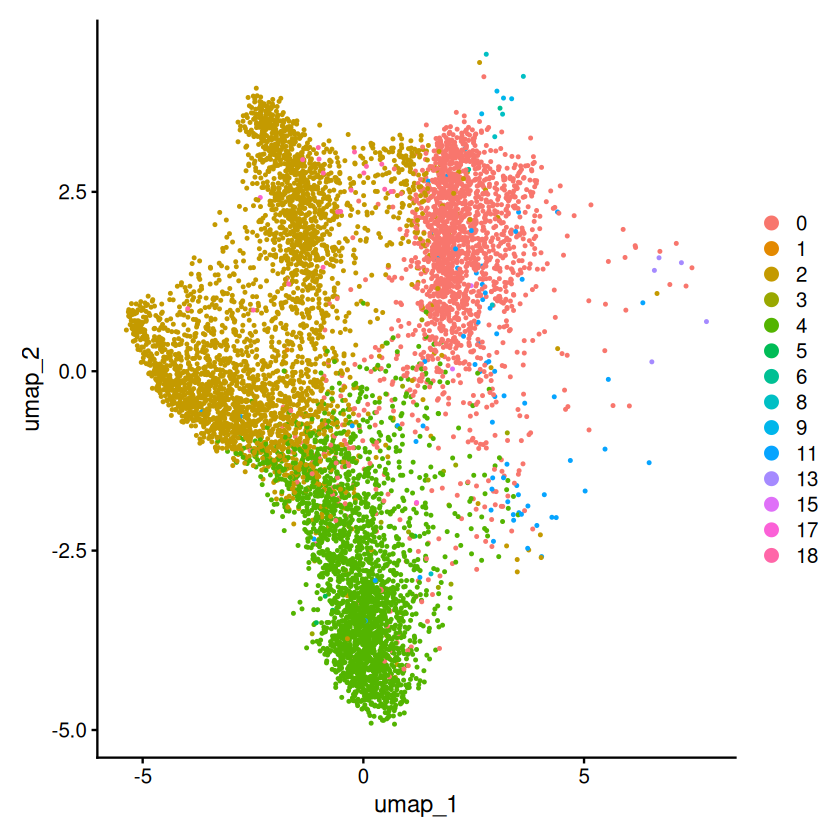

In [7]:
DimPlot(teich_cd4)

In [8]:
teich_cd4 <- NormalizeData(teich_cd4, verbose = FALSE)
teich_cd4 <- FindVariableFeatures(teich_cd4, nfeatures = 1000, verbose = FALSE)
teich_cd4 <- ScaleData(teich_cd4, verbose = FALSE)
teich_cd4 <- RunPCA(teich_cd4, npcs = 10, verbose = FALSE)
teich_cd4 <- RunUMAP(teich_cd4, reduction = "pca", dims = 1:10)
teich_cd4 <- FindNeighbors(teich_cd4, dims = 1:10)
teich_cd4 <- FindClusters(teich_cd4, resolution = 0.3)

Warning message:
“Number of dimensions changing from 50 to 10”
Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
17:15:37 UMAP embedding parameters a = 0.9922 b = 1.112

17:15:37 Read 7865 rows and found 10 numeric columns

17:15:37 Using Annoy for neighbor search, n_neighbors = 30

17:15:37 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:15:38 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpL1Pp2R/file5de3d65d4472b

17:15:38 Searching Annoy index using 1 thread, search_k = 3000

17:15:41 Annoy recall = 100%

17:15:43 Com

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 7865
Number of edges: 237569

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8554
Number of communities: 4
Elapsed time: 1 seconds


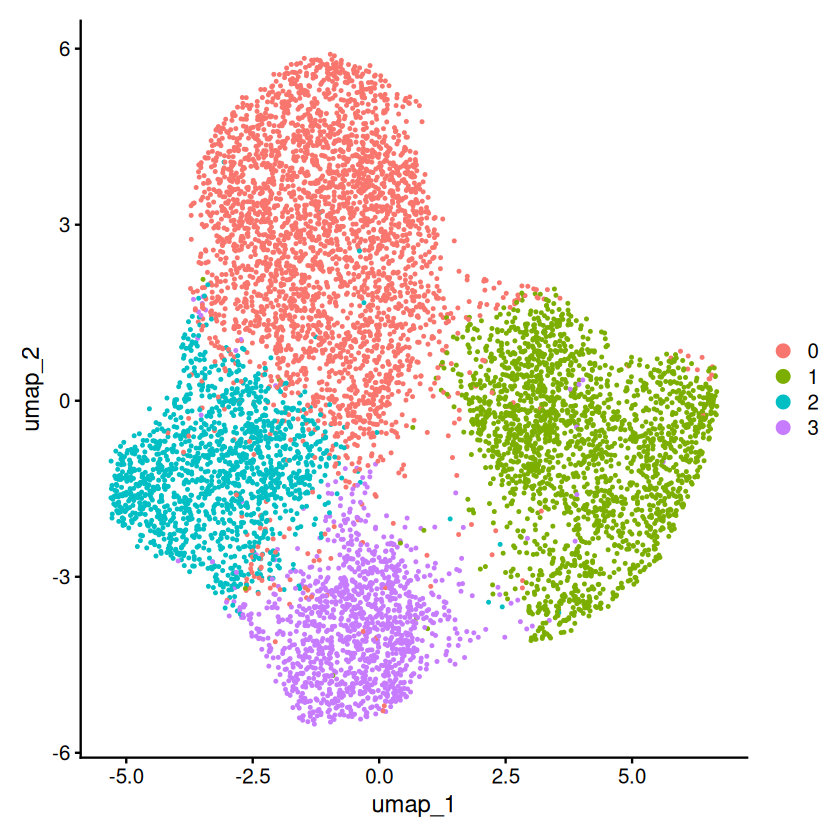

In [9]:
DimPlot(teich_cd4)

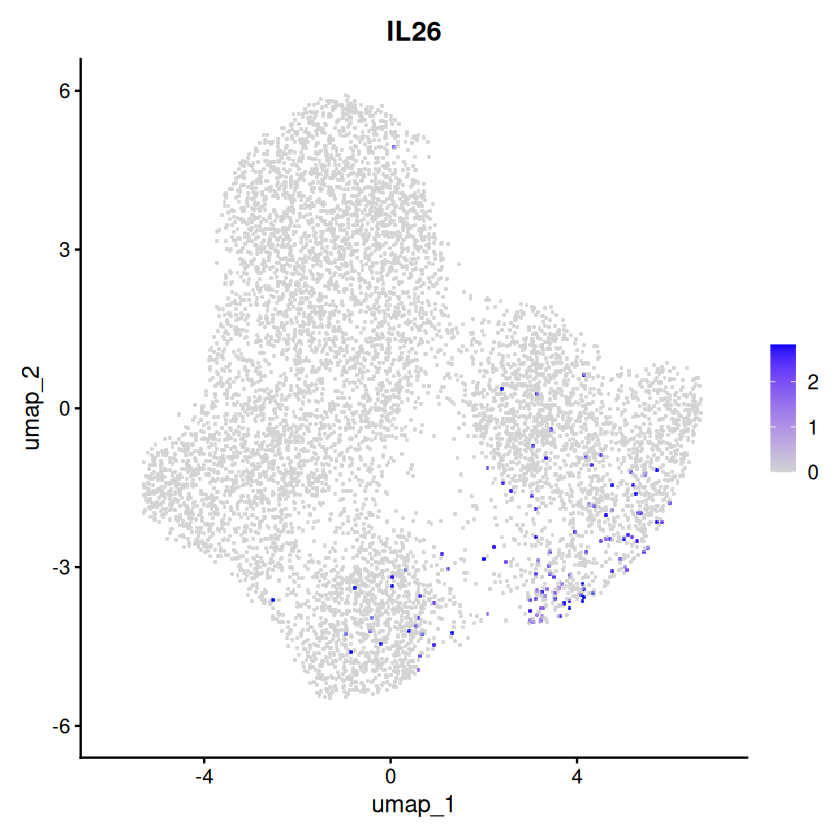

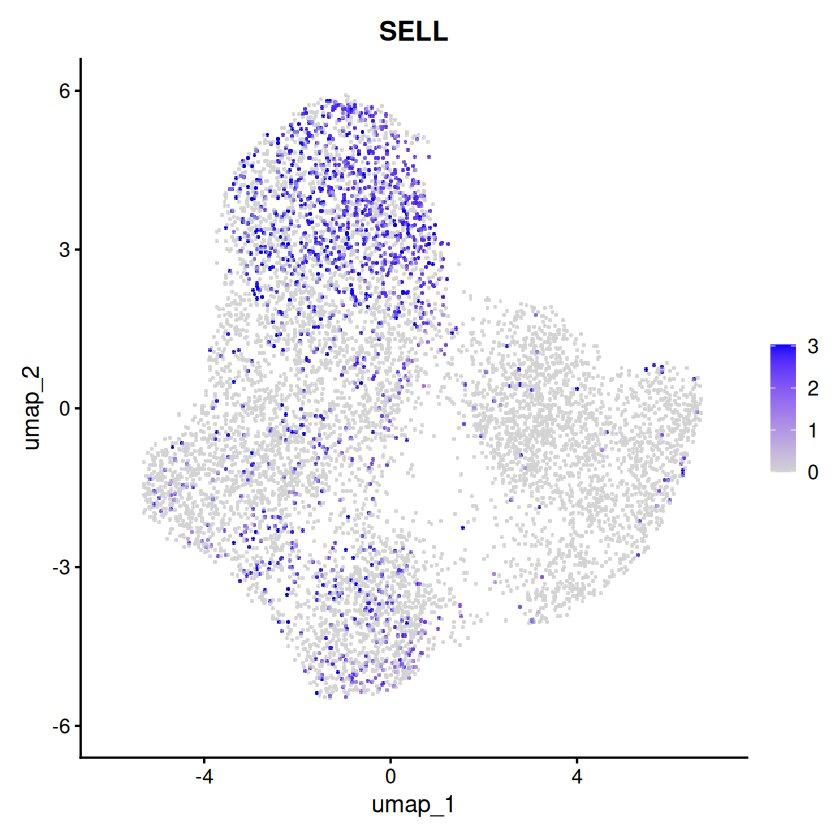

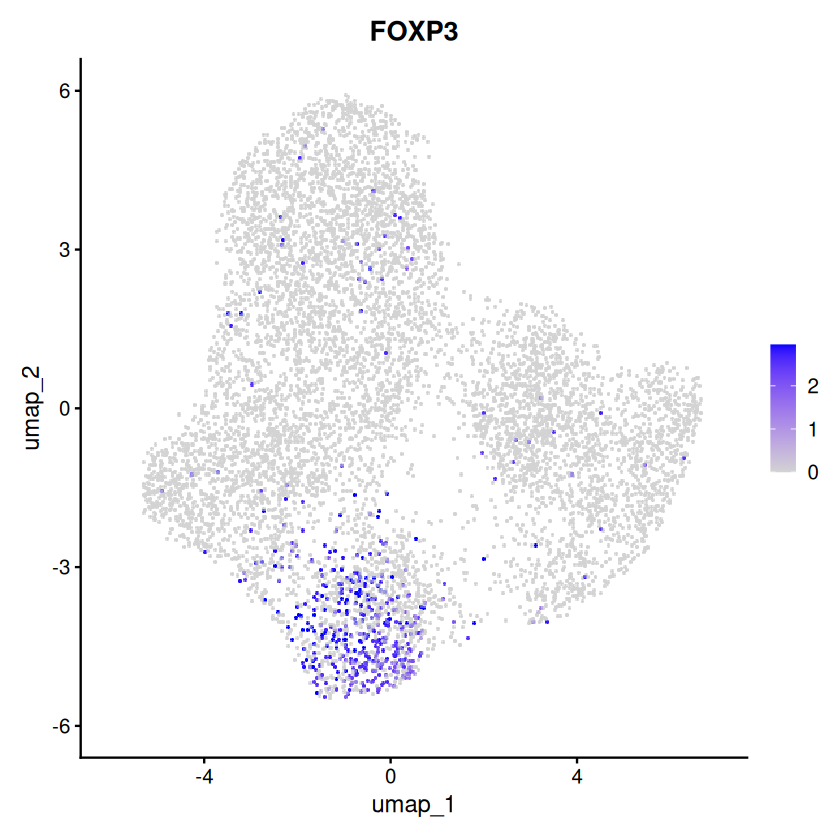

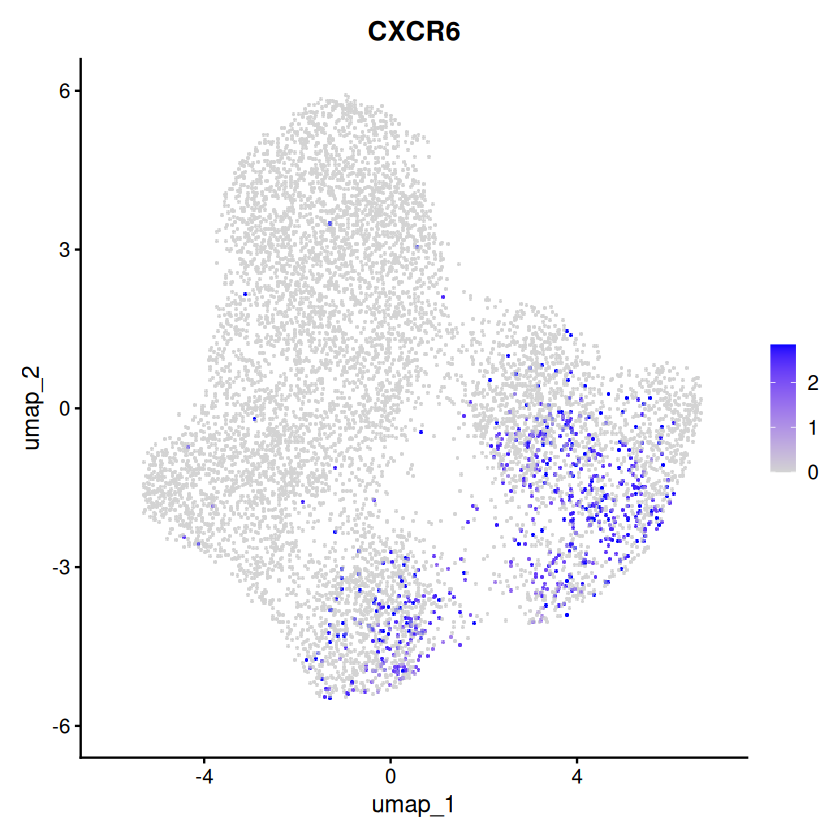

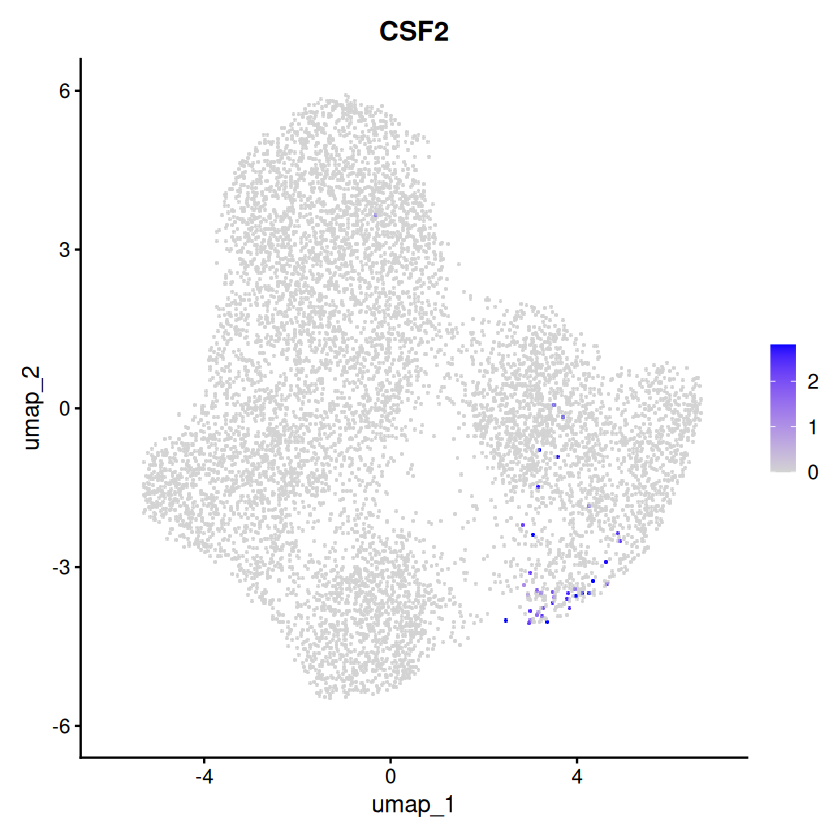

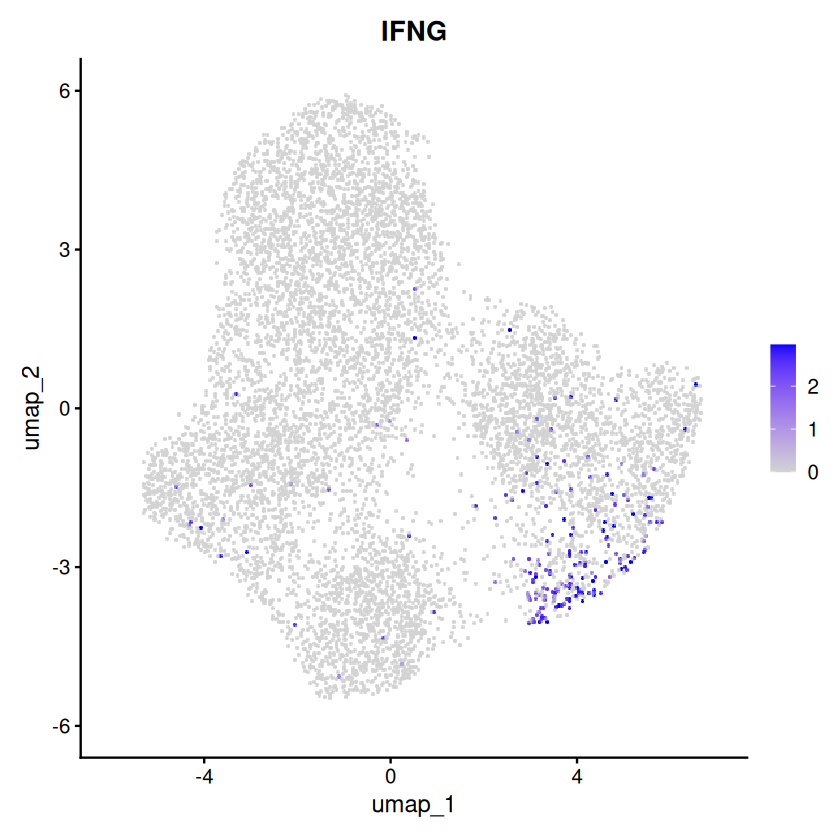

In [10]:

FeaturePlot(teich_cd4, features = "IL26", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "SELL", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "FOXP3", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "CXCR6", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "CSF2", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)
FeaturePlot(teich_cd4, features = "IFNG", min.cutoff = 0, raster = T, max.cutoff = "q80", pt.size = 2)


In [11]:
teich_cd4 <- FindClusters(teich_cd4, resolution = 0.9)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 7865
Number of edges: 237569

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7456
Number of communities: 9
Elapsed time: 1 seconds


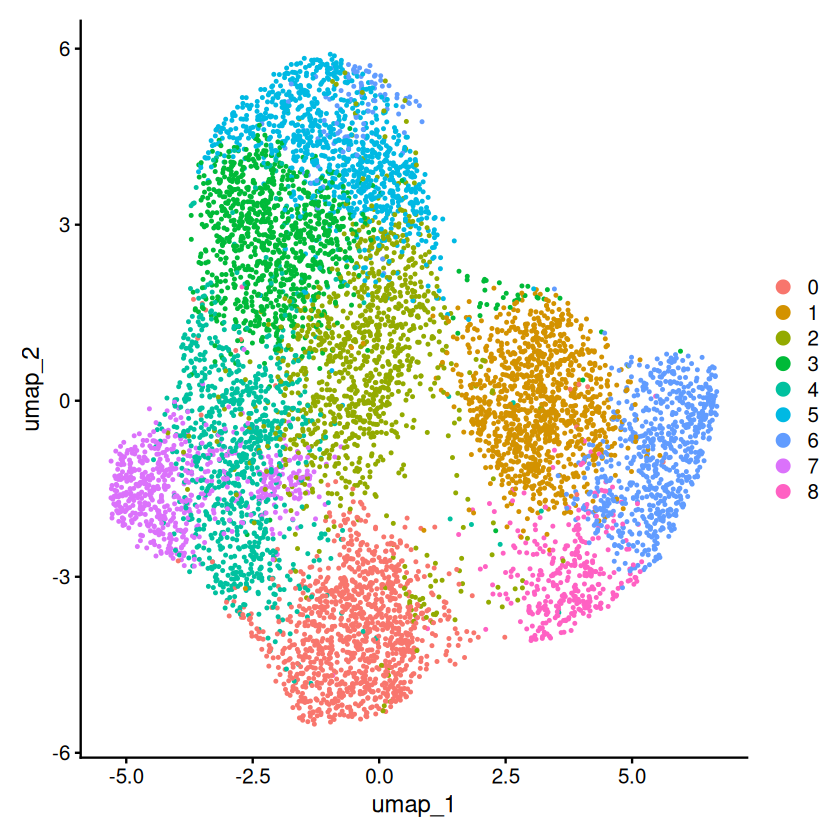

In [12]:
DimPlot(teich_cd4)

In [16]:
teich_cd4$cd4_ctl  <- ifelse(teich_cd4$seurat_clusters == 8, "CTL","Other")
teich_cd4$cd4_ctl  %>% table


.
  CTL Other 
  331  7534 

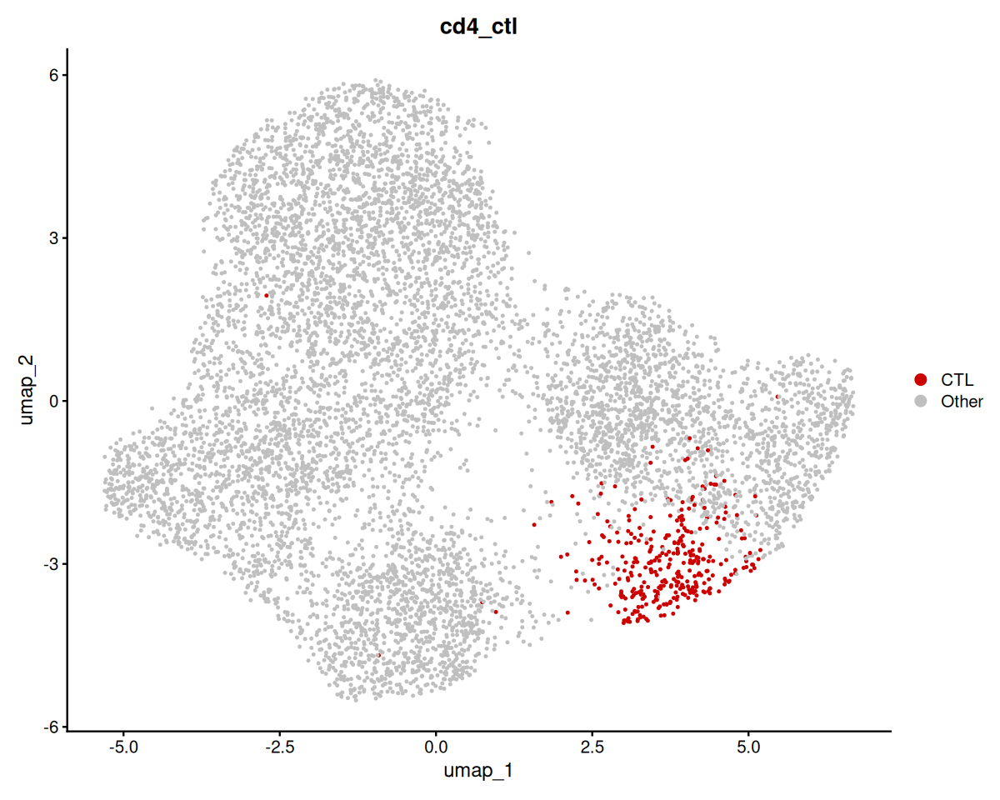

In [17]:
DimPlot(teich_cd4, group.by = "cd4_ctl", cols = c("#cd0000ff","grey75"))

In [15]:
cd4_ctl_sig  <- c(

    'GZMA', 'CTSH', 'IFNG', 'CCL4', 'HLA-DRB5', 'ZEB2', 'CHN1', 'IL12RB2', 'TESC', 'ADAM12', 'CPNE7', 'IL26',
    'GZMH', 'DAPK2', 'GZMB', 'COL5A3', 'OASL', 'NCR3', 'MCOLN2', 'GNLY', 'CSF2', 'MSC', 'GOLIM4', 
    'LINC02694', 'IL17A', 'GZMK', 'CDCA7', 'LINC00299', 'GPR34', 'LINC02384', 'FASLG', 'IL22', 'PKIG', 
    'APOBEC3H', 'PPARG', 'NUSAP1', 'SLC27A2', 'MSC-AS1', 'LYN', 'NTRK2', 'HDGFL3', 'MREG', 'MKI67', 
    'HLA-DQA2', 'KLRD1', 'SLAMF8', 'FSD1', 'TMPRSS3', 'PCLAF', 'TYMS', 'TOP2A', 'SETBP1', 'TOGARAM2', 'TPX2', 
    'IL17F', 'AL139393.3', 'PROK2', 'RHOU', 'MYO7A', 'EOMES', 'CENPE', 'TK1', 'KIF11', 'NCAPH', 'FCRL6', 'TIAM2', 
    'RRM2', 'CDK1', 'CDT1', 'RCAN2', 'SYNGR3', 'PALLD', 'BIRC5', 'ASPM', 'C3orf14', 'WWTR1', 'PLEKHG3', 'OTUB2', 
    'FES', 'ELOVL4', 'ADGRG5', 'CCNA2', 'UBE2C', 'EVC', 'KIFC1', 'TNS3', 'CD160', 'CCNB2', 'KIF23', 'AC243829.4', 
    'NCAPG', 'DOCK5', 'KIF2C', 'AC092580.4', 'P4HA2', 'CDCA2', 'PKMYT1', 'UHRF1', 'GTSE1', 'GPR27', 'DPF3', 
    'LINC02446', 'DLGAP5', 'ZNF683', 'CDC20', 'TROAP', 'AURKB', 'CEND1', 'CENPA', 'NMU', 'BUB1B', 'MELK', 'FOXM1', 
    'DEPDC1B', 'HMMR', 'CDCA5', 'CKAP2L', 'SHCBP1', 'RGS9', 'KIF14', 'KIF15', 'CDCA3', 'RAD51', 'PLK1', 'SPC25', 
    'CCR1', 'KIF4A', 'HJURP', 'NUGGC', 'PRR11', 'ESCO2', 'CDC45', 'MND1', 'TENM4', 'PIF1', 'HRH4', 'TP73', 'ADGRG1', 
    'PXDC1', 'SPC24', 'DIAPH3', 'E2F2', 'ANLN', 'MCM10', 'ATP8B4', 'SKA1', 'AL139393.2', 'DEPDC1', 'E2F8', 'SKA3', 
    'PDLIM4', 'GLDC', 'PBK', 'NCS1', 'KIF20A', 'TP63', 'CES1', 'KIF18B', 'HIST1H3G', 'KLHL13', 'HIST1H3C', 'BATF3', 
    'SOX5', 'E2F7', 'ARNTL2', 'CDC25A', 'ZBED2', 'MPPED2', 'FAM111B', 'GLB1L2', 'AL133405.2', 'NTRK1', 'FAM72B', 
    'TRPC3', 'AL356234.2', 'HMHB1', 'AC013460.1', 'CDC25C', 'KRT86', 'KLRC4', 'TYMSOS', 'KLRC1', 'ESPL1', 'ODAPH', 
    'RASGEF1A', 'PKHD1', 'KLRC2'
)

In [30]:
DefaultAssay(teich_cd4)  <- "RNA"
cd4_ctl_sig_filt  <- cd4_ctl_sig[which(cd4_ctl_sig %in% rownames(teich_cd4@assays$RNA))]
teich_cd4  <- AddModuleScore(teich_cd4, features = list(cd4_ctl_sig),
  name     = "CTL_score")

Warning message:
“The following features are not present in the object: LINC02694, CDCA7, NUSAP1, MKI67, TYMS, TOP2A, TPX2, AL139393.3, CENPE, KIF11, RRM2, CDK1, BIRC5, UBE2C, CCNB2, KIF23, KIF2C, AC092580.4, CDCA2, UHRF1, GTSE1, DLGAP5, CDC20, AURKB, CENPA, HMMR, CKAP2L, CDCA3, RAD51, HJURP, CDC45, ANLN, E2F8, AL133405.2, AC013460.1, CDC25C, TYMSOS, not searching for symbol synonyms”


In [31]:
teich_cd4_umap  <- teich_cd4@reductions$umap@cell.embeddings
teich_cd4$UMAP_1  <- teich_cd4_umap[,1]
teich_cd4$UMAP_2  <- teich_cd4_umap[,2]

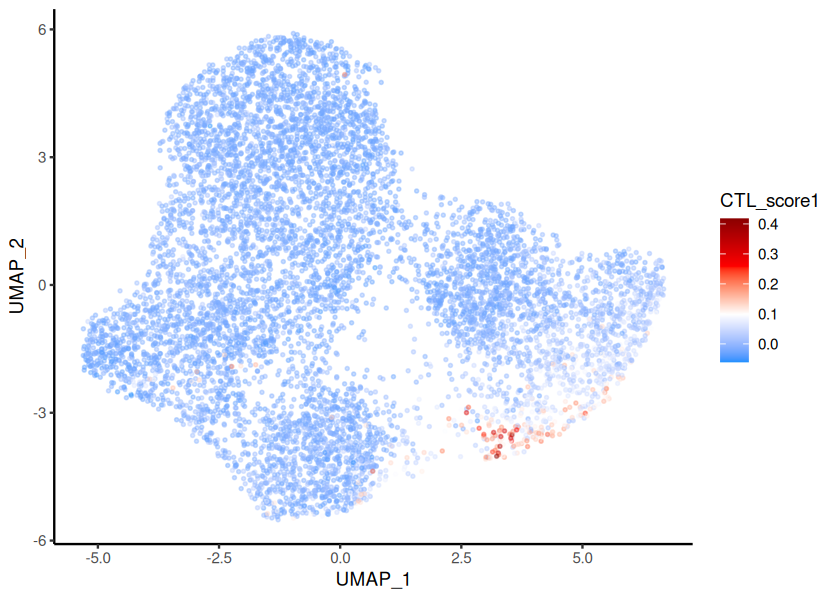

In [35]:
options(repr.plot.width = 7, repr.plot.height = 5)
teich_cd4@meta.data  %>% 
ggplot(aes(x = UMAP_1, y = UMAP_2)) +
geom_point(aes(color = CTL_score1), alpha = 0.4, size = 0.5) +
theme_classic() +
scale_colour_gradientn(
    colours = c("dodgerblue", "white", "red","darkred"))

## Heatmap marker genes

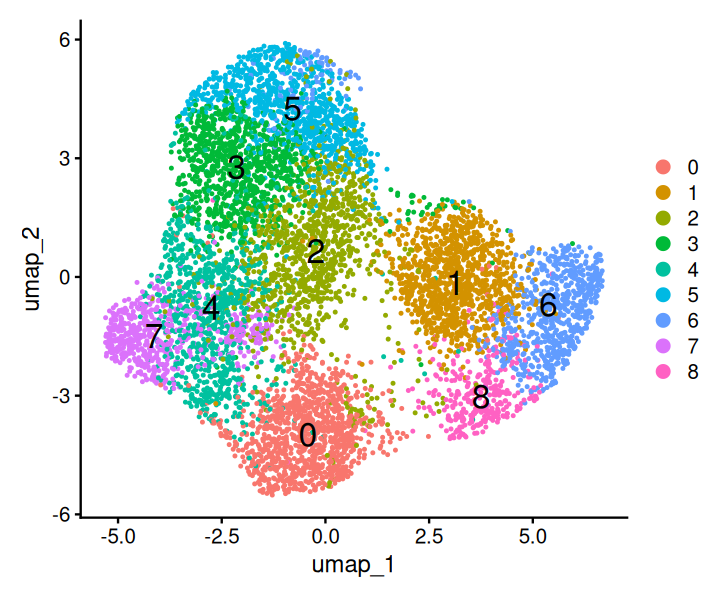

In [72]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(teich_cd4, label = T, label.size = 7)

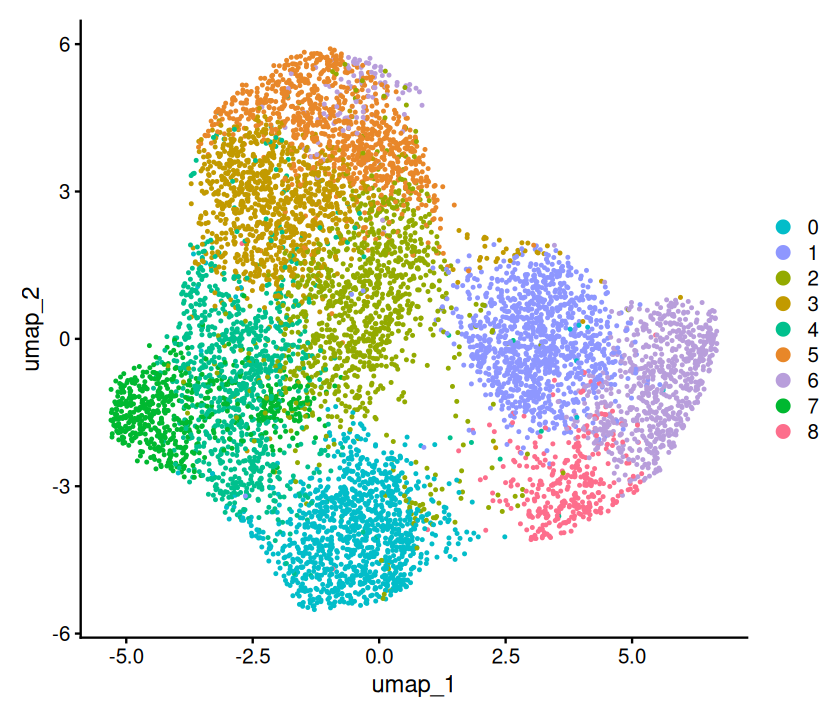

In [110]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(teich_cd4, 
       cols = c("0" = "#02bdc9ff",
                "1" = "#8e97ffff",
                "2" = "#93aa00ff",
                "3" = "#c29a00ff",
                "4" = "#00c08dff",
                "5" = "#e88729ff",
                "6" = "#b89edbff",
                "7" = "#00b830ff",
               "8" = "#fd6e8cff"
               ))

In [73]:
gn2  <- c('GZMA', 'GZMB','GZMH','GNLY', 'IFNG', "PRF1",'CTSH', 
          'HLA-DRB5','FASLG',  'ZEB2',"RORC","TBX21","EOMES","BHLHE40",
          "IL23R",
          'IL12RB2', "CXCR6",
          'IL26', 'IL17A','IL22','CCL4', 'CSF2')


In [74]:
## Marker genes
avgexp3 = AverageExpression(teich_cd4, features = gn2, group.by = "seurat_clusters",
                          assay = "RNA")
colnames(avgexp3$RNA)  <- gsub(colnames(avgexp3$RNA), pattern = "g", replacement = "")

In [75]:
options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 14, filename = "figures/heatmaps_other_data/elmantaite.pdf",
                  width = 5, height = 7)

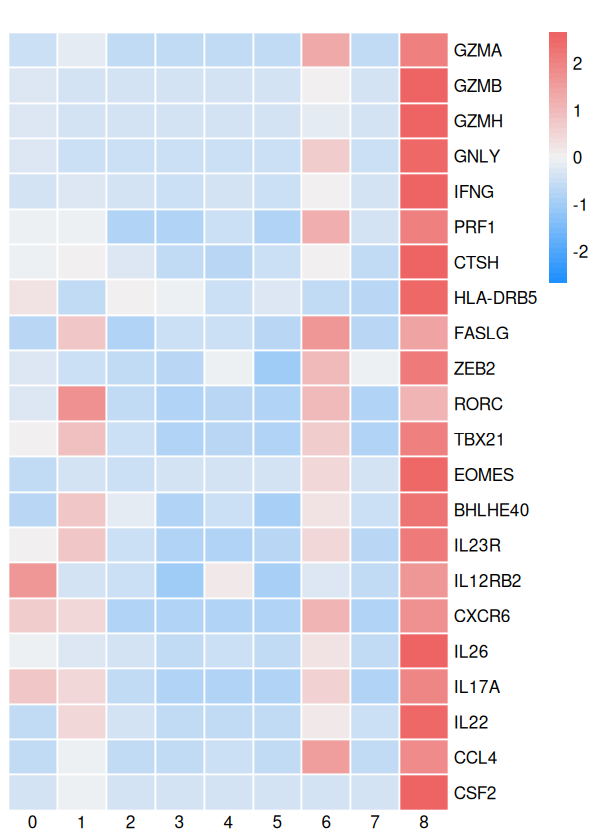

In [76]:
options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white")

## Cluster frequency

In [11]:
options(repr.plot.width = 25, repr.plot.height = 10)

seurat_meta_data <- teich_cd4@meta.data

# Create grouped dataframe, calculate the frequencies of clusters
df4 <- seurat_meta_data %>% 
  group_by(Patient_ID, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!Patient_ID, names_to = "seurat_clusters", values_to = "freq")

# Control - all sums should be one
# df4 %>% group_by(MouseID) %>% summarise(sum = sum(freq))

# As we've lost non-grouping variables, let's join them back
md_to_join <- seurat_meta_data %>% 
  dplyr::select(Patient_ID, Diagnosis) %>% 
  unique()

df4  <- left_join(df4, md_to_join)

`summarise()` has grouped output by 'Patient_ID'. You can override using the
`.groups` argument.
Joining with `by = join_by(Patient_ID)`


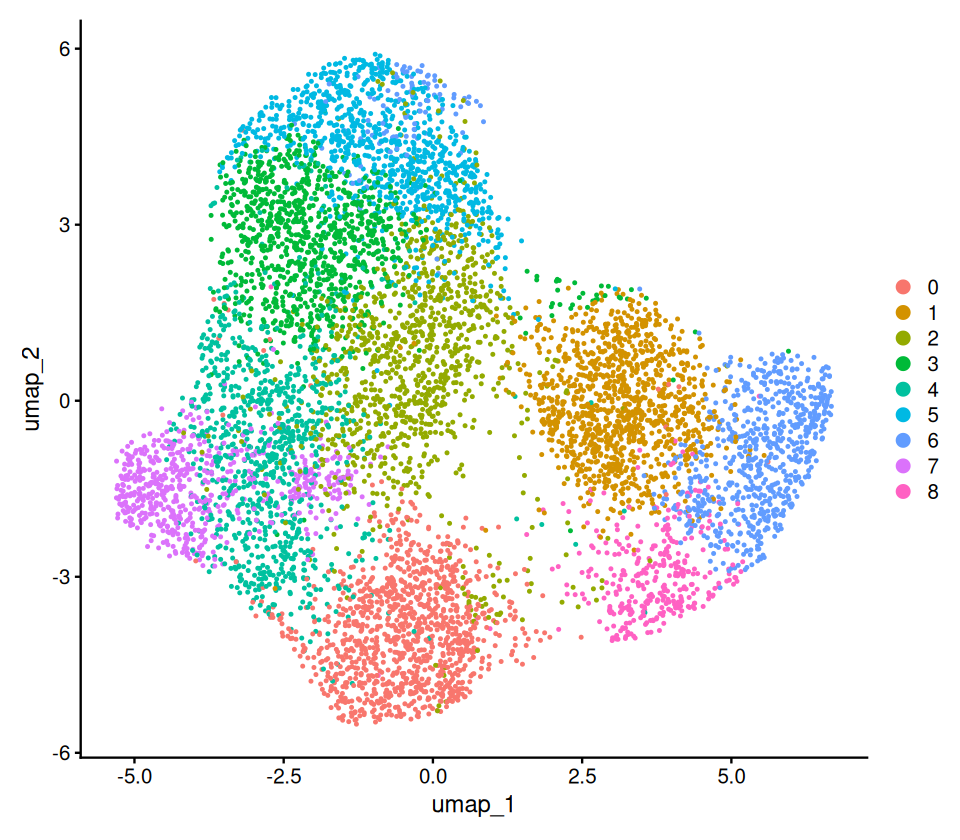

In [12]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(teich_cd4, label = F, label.size = 7)

Bin width defaults to 1/30 of the range of the data. Pick better value with
`binwidth`.


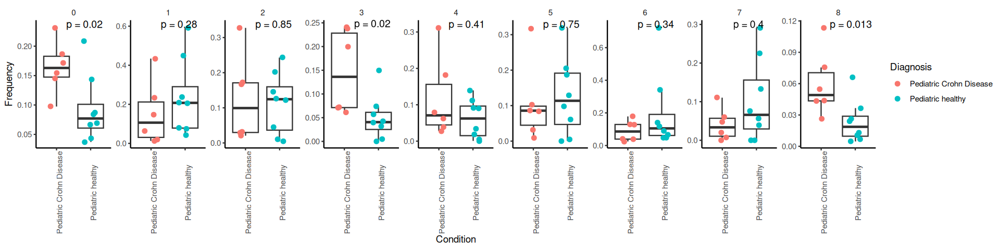

In [13]:
options(repr.plot.width = 16, repr.plot.height = 4)


df4 %>% 
  ggplot(aes(x = Diagnosis, y = freq)) + # you can change the x to whatever variable you're interested in
  geom_boxplot(outlier.shape = NA) + 
  geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
  geom_jitter(position=position_jitter(0.2), size = 2, aes(color = Diagnosis)) + 
  facet_wrap(~seurat_clusters, scales = "free", ncol = 9) +
  ylab("Frequency") +
  xlab("Condition") +
  theme_classic() +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_text(angle = 90)) +
ggpubr::stat_compare_means(label = "p.format", size = 4, label.x = 1.5) 

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


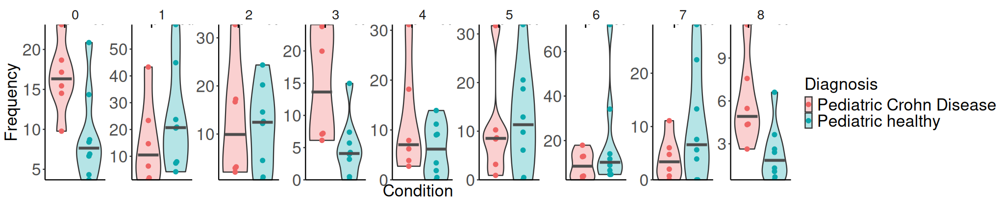

In [14]:
options(repr.plot.width = 17, repr.plot.height = 3.5)


df4 %>% 
  ggplot(aes(x = Diagnosis, y = freq*100)) + # you can change the x to whatever variable you're interested in
    geom_violin(alpha = 0.3, aes(fill = Diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(aes(color = Diagnosis), cex = 2, 
                shape = 16, corral = "random", size = 2.5) +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, scales = "free", ncol = 9) +
scale_fill_manual(values = c("indianred2", "#0aa7acff")) +
scale_color_manual(values = c("indianred2", "#0aa7acff")) +
  ylab("Frequency") +
  xlab("Condition") +
  theme_classic() +
ylim(c(0,NA)) +
scale_y_continuous(expand = c(0,NA)) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        ) +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.5)  + ggtheme()



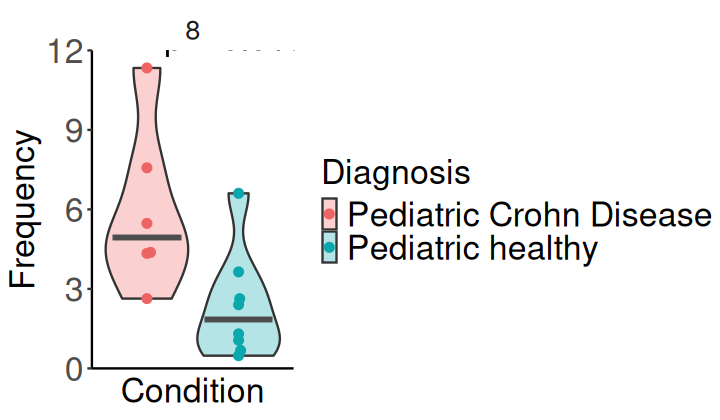

In [15]:
options(repr.plot.width = 6, repr.plot.height = 3.5)


df4 %>% 
dplyr::filter(seurat_clusters == 8)  %>% 
  ggplot(aes(x = Diagnosis, y = freq*100)) + # you can change the x to whatever variable you're interested in
    geom_violin(alpha = 0.3, aes(fill = Diagnosis), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(aes(color = Diagnosis), cex = 2, 
                shape = 16, corral = "random", size = 2.5) +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, scales = "free", ncol = 9) +
scale_fill_manual(values = c("indianred2", "#0aa7acff")) +
scale_color_manual(values = c("indianred2", "#0aa7acff")) +
  ylab("Frequency") +
  xlab("Condition") +
  theme_classic() +
scale_y_continuous(expand = c(0,NA), limits = c(0,12)) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        ) +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.5)  + ggtheme()


In [14]:
teich_cd4

An object of class Seurat 
30282 features across 7865 samples within 1 assay 
Active assay: RNA (30282 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

In [189]:
ggsave(filename = "figures/teichman/cluster_frequency_CTL.svg",
      width = 14, height = 7.8, units = "cm")

# Rios-Martini et al.

In [13]:
rios  <- readRDS("../240202_VN_CD4_CTL_integration/data/rios_martini_filt_stacas.rds")

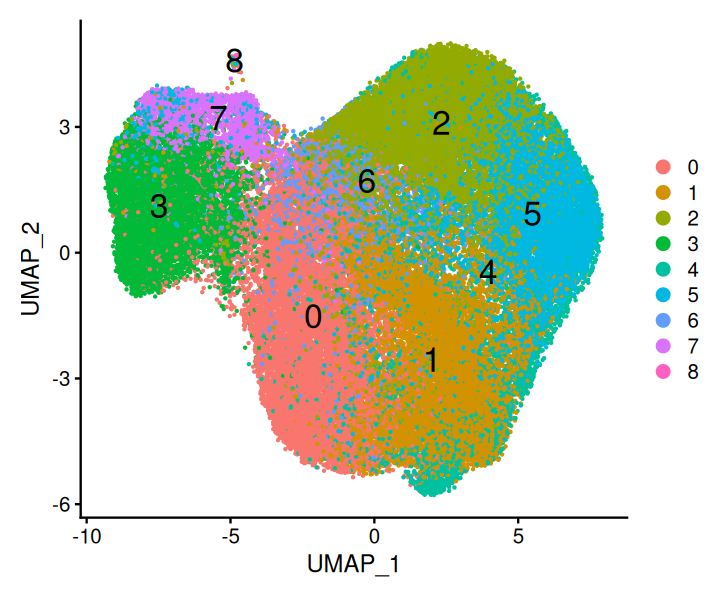

In [69]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(rios, label = T, label.size = 7)

In [15]:
cd4_ctl_sig  <- c(

    'GZMA', 'CTSH', 'IFNG', 'CCL4', 'HLA-DRB5', 'ZEB2', 'CHN1', 'IL12RB2', 'TESC', 'ADAM12', 'CPNE7', 'IL26',
    'GZMH', 'DAPK2', 'GZMB', 'COL5A3', 'OASL', 'NCR3', 'MCOLN2', 'GNLY', 'CSF2', 'MSC', 'GOLIM4', 
    'LINC02694', 'IL17A', 'GZMK', 'CDCA7', 'LINC00299', 'GPR34', 'LINC02384', 'FASLG', 'IL22', 'PKIG', 
    'APOBEC3H', 'PPARG', 'NUSAP1', 'SLC27A2', 'MSC-AS1', 'LYN', 'NTRK2', 'HDGFL3', 'MREG', 'MKI67', 
    'HLA-DQA2', 'KLRD1', 'SLAMF8', 'FSD1', 'TMPRSS3', 'PCLAF', 'TYMS', 'TOP2A', 'SETBP1', 'TOGARAM2', 'TPX2', 
    'IL17F', 'AL139393.3', 'PROK2', 'RHOU', 'MYO7A', 'EOMES', 'CENPE', 'TK1', 'KIF11', 'NCAPH', 'FCRL6', 'TIAM2', 
    'RRM2', 'CDK1', 'CDT1', 'RCAN2', 'SYNGR3', 'PALLD', 'BIRC5', 'ASPM', 'C3orf14', 'WWTR1', 'PLEKHG3', 'OTUB2', 
    'FES', 'ELOVL4', 'ADGRG5', 'CCNA2', 'UBE2C', 'EVC', 'KIFC1', 'TNS3', 'CD160', 'CCNB2', 'KIF23', 'AC243829.4', 
    'NCAPG', 'DOCK5', 'KIF2C', 'AC092580.4', 'P4HA2', 'CDCA2', 'PKMYT1', 'UHRF1', 'GTSE1', 'GPR27', 'DPF3', 
    'LINC02446', 'DLGAP5', 'ZNF683', 'CDC20', 'TROAP', 'AURKB', 'CEND1', 'CENPA', 'NMU', 'BUB1B', 'MELK', 'FOXM1', 
    'DEPDC1B', 'HMMR', 'CDCA5', 'CKAP2L', 'SHCBP1', 'RGS9', 'KIF14', 'KIF15', 'CDCA3', 'RAD51', 'PLK1', 'SPC25', 
    'CCR1', 'KIF4A', 'HJURP', 'NUGGC', 'PRR11', 'ESCO2', 'CDC45', 'MND1', 'TENM4', 'PIF1', 'HRH4', 'TP73', 'ADGRG1', 
    'PXDC1', 'SPC24', 'DIAPH3', 'E2F2', 'ANLN', 'MCM10', 'ATP8B4', 'SKA1', 'AL139393.2', 'DEPDC1', 'E2F8', 'SKA3', 
    'PDLIM4', 'GLDC', 'PBK', 'NCS1', 'KIF20A', 'TP63', 'CES1', 'KIF18B', 'HIST1H3G', 'KLHL13', 'HIST1H3C', 'BATF3', 
    'SOX5', 'E2F7', 'ARNTL2', 'CDC25A', 'ZBED2', 'MPPED2', 'FAM111B', 'GLB1L2', 'AL133405.2', 'NTRK1', 'FAM72B', 
    'TRPC3', 'AL356234.2', 'HMHB1', 'AC013460.1', 'CDC25C', 'KRT86', 'KLRC4', 'TYMSOS', 'KLRC1', 'ESPL1', 'ODAPH', 
    'RASGEF1A', 'PKHD1', 'KLRC2'
)

In [16]:
DefaultAssay(rios)  <- "RNA"
cd4_ctl_sig_filt  <- cd4_ctl_sig[which(cd4_ctl_sig %in% rownames(rios@assays$RNA))]
rios  <- AddModuleScore(rios, features = list(cd4_ctl_sig),
  name     = "CTL_score")

Warning message:
“The following features are not present in the object: LINC02694, AL139393.3, AC092580.4, AL133405.2, AC013460.1, TYMSOS, KLRC2, not searching for symbol synonyms”


In [18]:
rios_umap  <- rios@reductions$umap@cell.embeddings
rios$UMAP_1  <- rios_umap[,1]
rios$UMAP_2  <- rios_umap[,2]

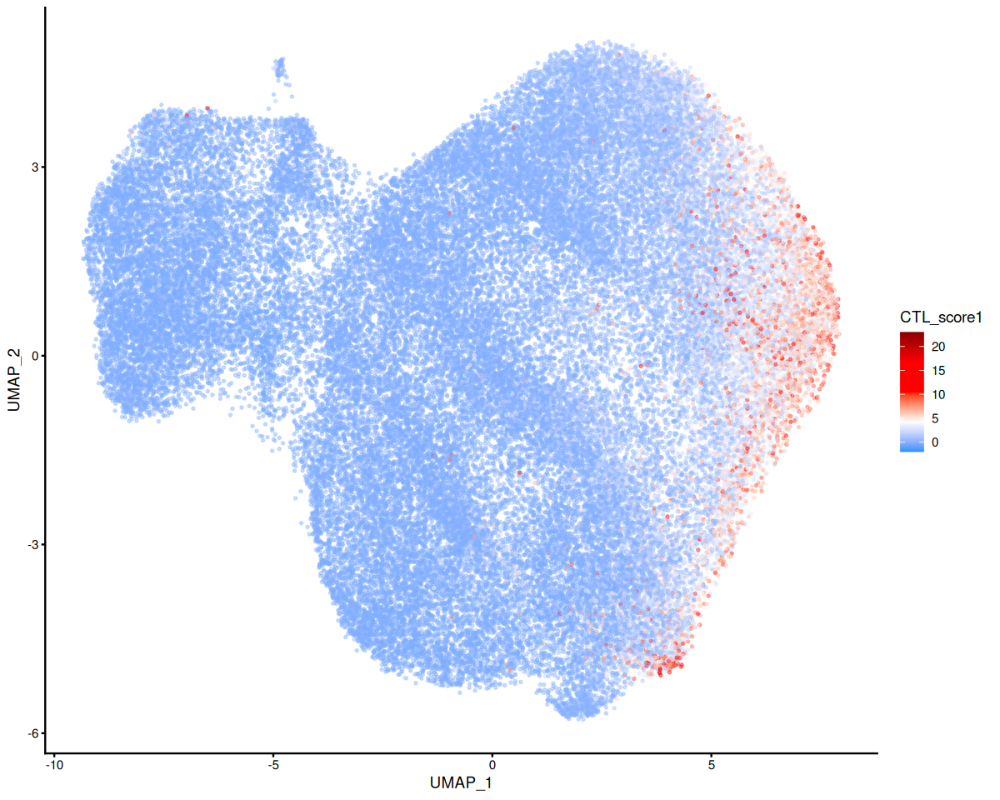

In [19]:
options(repr.plot.width = 10, repr.plot.height = 8)
rios@meta.data  %>% 
ggplot(aes(x = UMAP_1, y = UMAP_2)) +
geom_point(aes(color = CTL_score1), alpha = 0.4, size = 0.5) +
theme_classic() +
scale_colour_gradientn(
    colours = c("dodgerblue", "white", "red","red","darkred"),
    #rescaler = ~ scales::rescale_mid(.x, mid = 0)
  )

In [22]:
rios$Sample  <- paste(rios$Source, rios$Species)

In [24]:
rios$Condition  %>% table

.
   CD    HD 
30996 29484 

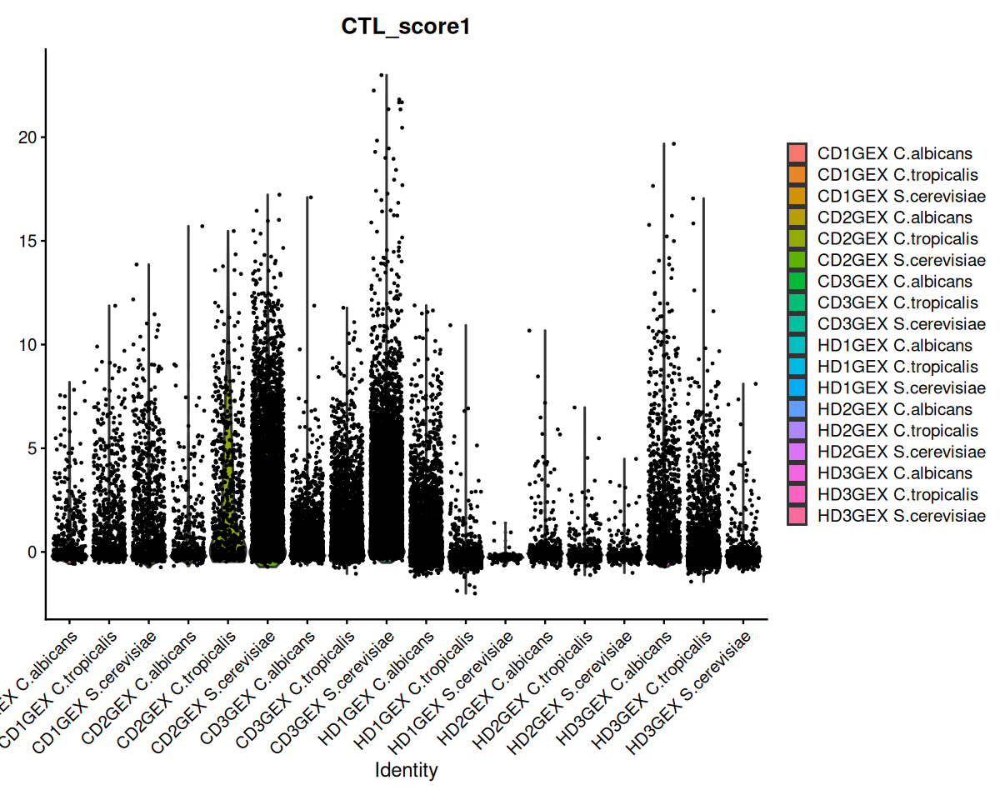

In [25]:
VlnPlot(rios, features = "CTL_score1", group.by = "Sample")

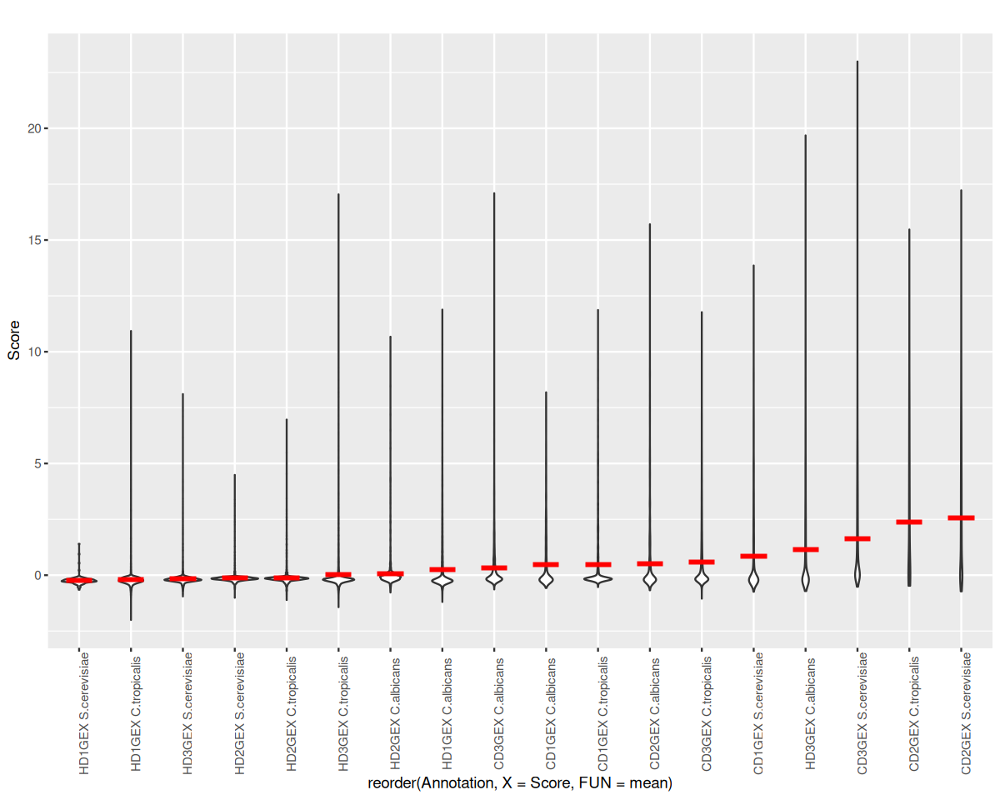

In [32]:
data.frame(Score = rios$CTL_score1,
                  Annotation = rios$Sample)  %>% 
           ggplot(aes(x = reorder(Annotation, X = Score, FUN = mean), y = Score)) +
  geom_violin() + 
  stat_summary(fun = "mean",
               geom = "crossbar", 
               width = 0.5,
               colour = "red") +
 ggtitle("") +
theme(axis.text.x = element_text(angle = 90))



`summarise()` has grouped output by 'Sample', 'Condition', 'Species'. You can
override using the `.groups` argument.


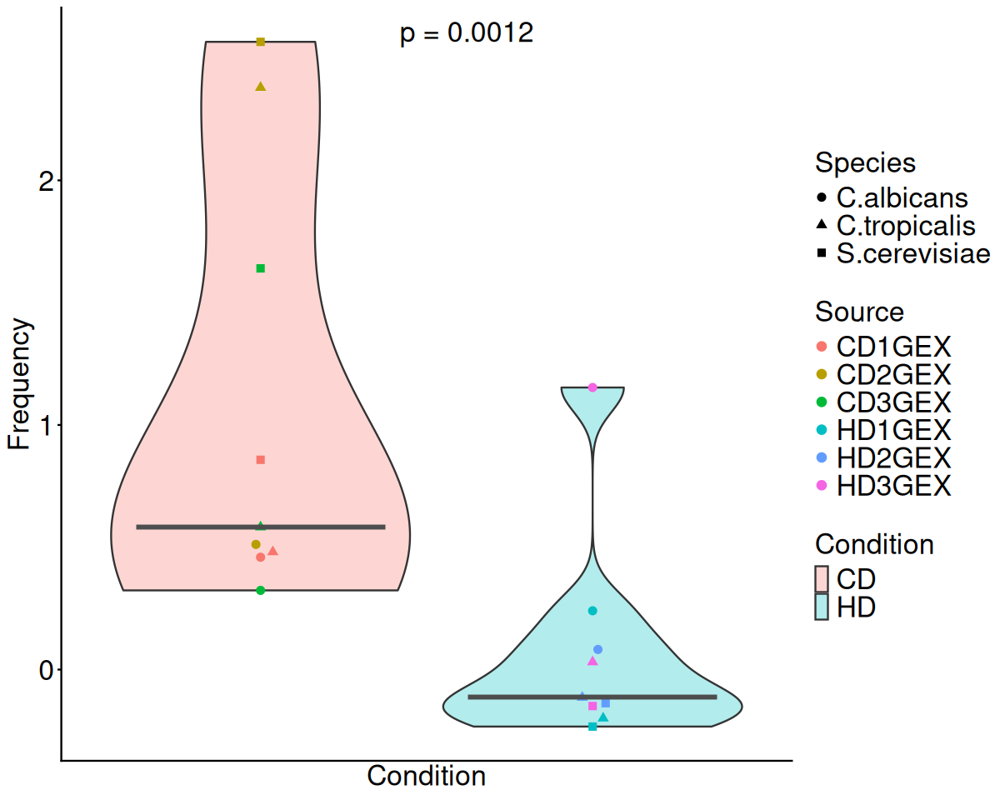

In [45]:
rios@meta.data  %>% 
group_by(Sample, Condition, Species, Source)  %>% 
summarise(meanscore  = mean(CTL_score1),
         medianscore  = median(CTL_score1))  %>% 
ggplot(aes(x = Condition, y = meanscore)) +
 geom_violin(alpha = 0.3, aes(fill = Condition), scale = "width") + 
 ggbeeswarm::geom_beeswarm(aes(color = Source, shape = Species), cex = 2, 
                 corral = "random", size = 2.5) +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
ylab("Mean Module Score") +
  xlab("Condition") +
  theme_classic() +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        ) +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.5)  + ggtheme()


`summarise()` has grouped output by 'Sample', 'Condition', 'Species', 'Source'.
You can override using the `.groups` argument.


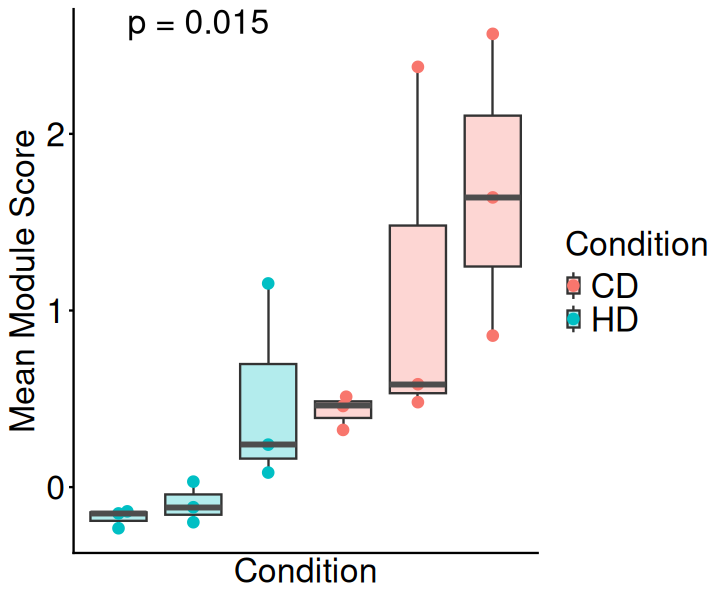

In [65]:
rios@meta.data  %>% 
mutate(Condition_Species = paste(Condition, Species))  %>% 
group_by(Sample, Condition, Species, Source, Condition_Species)  %>% 
summarise(meanscore  = mean(CTL_score1),
         medianscore  = median(CTL_score1))  %>% 
ggplot(aes(x = reorder(Condition_Species, X = meanscore, FUN = median), y = meanscore)) +
 #geom_violin(alpha = 0.3, aes(fill = Condition), scale = "width") + 
  geom_boxplot(alpha = 0.3, aes(fill = Condition)) + 
ggbeeswarm::geom_beeswarm(aes(color = Condition), cex = 2, 
                 corral = "random", size = 2.5) +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
#facet_grid(~Condition) +
ylab("Mean Module Score") +
  xlab("Condition") +
  theme_classic() +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        ) +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.5)  + ggtheme()

`summarise()` has grouped output by 'Sample', 'Condition', 'Species', 'Source'.
You can override using the `.groups` argument.


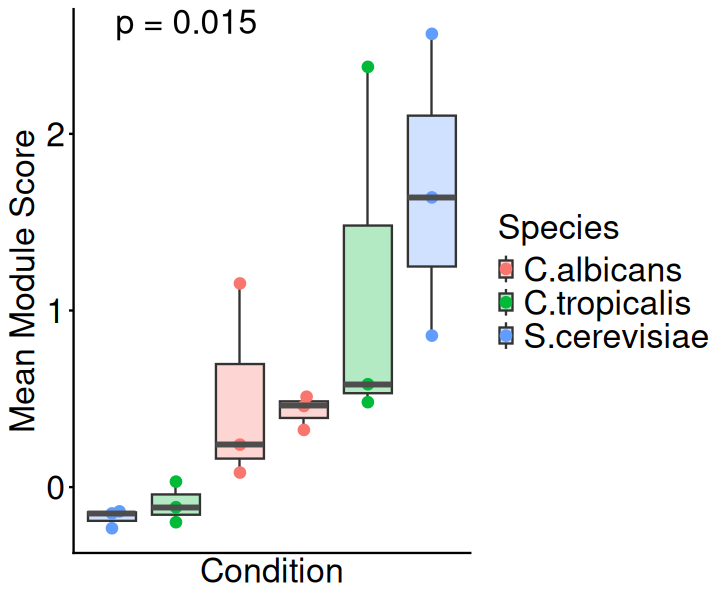

In [67]:
rios@meta.data  %>% 
mutate(Condition_Species = paste(Condition, Species))  %>% 
group_by(Sample, Condition, Species, Source, Condition_Species)  %>% 
summarise(meanscore  = mean(CTL_score1),
         medianscore  = median(CTL_score1))  %>% 
ggplot(aes(x = reorder(Condition_Species, X = meanscore, FUN = median), y = meanscore)) +
 #geom_violin(alpha = 0.3, aes(fill = Condition), scale = "width") + 
  geom_boxplot(alpha = 0.3, aes(fill = Species)) + 
ggbeeswarm::geom_beeswarm(aes(color = Species), cex = 2, 
                 corral = "random", size = 2.5) +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
#facet_grid(~Condition) +
ylab("Mean Module Score") +
  xlab("Condition") +
  theme_classic() +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        ) +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.5)  + ggtheme()

In [68]:
ggsave(filename = "figures/rios/rios_species_module_score.svg",
      width = 16, height = 7.8, units = "cm", create.dir = T)

✔ Created directory: figures/rios.



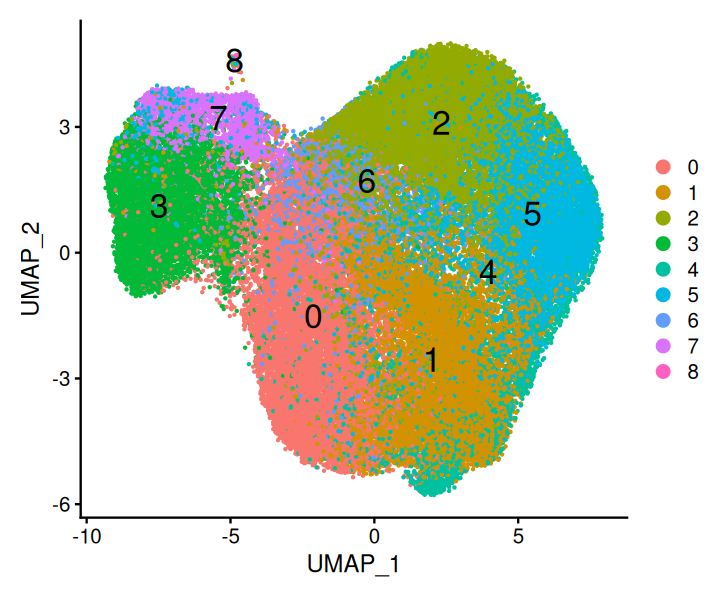

In [79]:
DimPlot(rios, label = T, label.size = 7)

In [80]:
colnames(rios@meta.data)

[1] "orig.ident"                  "nCount_RNA"                 
 [3] "nFeature_RNA"                "source"                     
 [5] "Dataset"                     "Date"                       
 [7] "percent.mt"                  "percent.rp"                 
 [9] "nCount_SCT"                  "nFeature_SCT"               
[11] "SCT_snn_res.0.7"             "seurat_clusters"            
[13] "is_cell"                     "chain"                      
[15] "contig_id"                   "high_confidence"            
[17] "productive"                  "length"                     
[19] "reads"                       "umis"                       
[21] "vdj_source"                  "count_TRA"                  
[23] "count_TRB"                   "count_Multi"                
[25] "cdr3_A1"                     "cdr3_A1_nt"                 
[27] "cdr3_A2"                     "cdr3_A2_nt"                 
[29] "cdr3_B"                      "cdr3_B_nt"                  
[31] "cdr3_Multi"                  "cdr3_Multi_nt"              
[33] "v_gene_A1"                   "j_gene_A1"                  
[35] "v_gene_A2"                   "j_gene_A2"                  
[37] "v_gene_B"                    "d_gene_B"                   
[39] "j_gene_B"                    "v_gene_Multi"               
[41] "d_gene_Multi"                "j_gene_Multi"               
[43] "SCT_snn_res.0.2"             "barcode"                    
[45] "Monaco_single"               "Wherry_main"                
[47] "nCount_refAssay"             "nFeature_refAssay"          
[49] "predicted.celltype.l1.score" "predicted.celltype.l1"      
[51] "predicted.celltype.l2.score" "predicted.celltype.l2"      
[53] "predicted.celltype.l3.score" "predicted.celltype.l3"      
[55] "mapping.score"               "refAssay_snn_res.0.2"       
[57] "refAssay_snn_res.0.4"        "Tissue"                     
[59] "Condition"                   "Species"                    
[61] "Source"                      "CTL_score1"                 
[63] "UMAP_1"                      "UMAP_2"

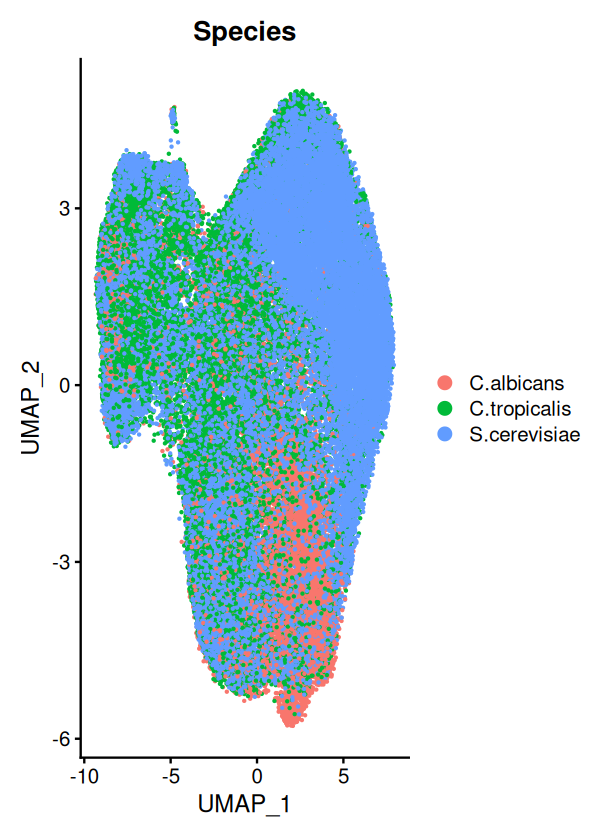

In [98]:
DimPlot(rios, group.by = "Species")

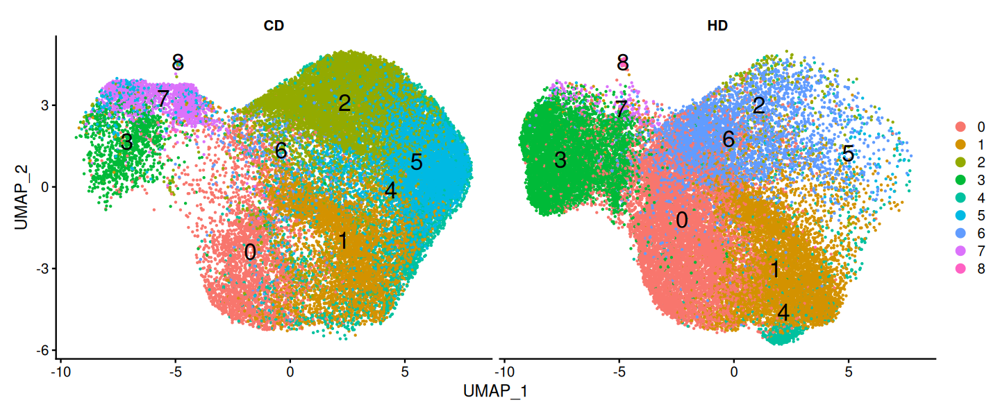

In [19]:
options(repr.plot.width = 12, repr.plot.height = 5)
DimPlot(rios, label = T, label.size = 7, split.by = "Condition")

In [83]:
rios_filt  <- subset(rios, seurat_clusters %in% c(0:7))

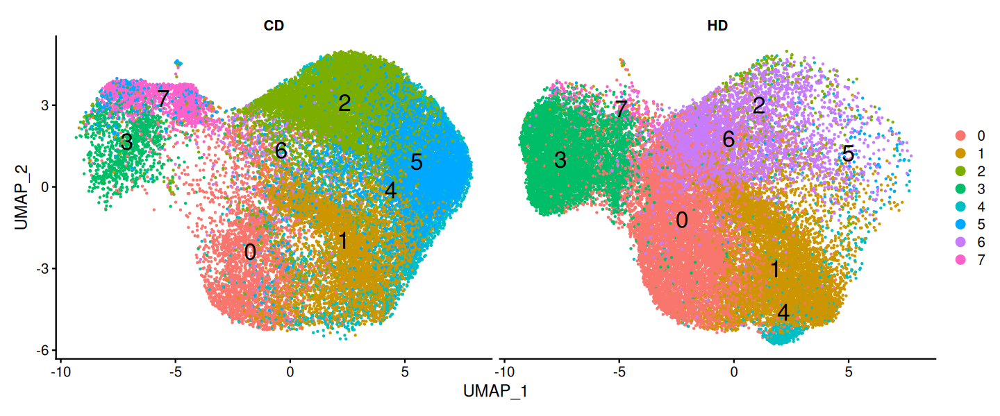

In [84]:
options(repr.plot.width = 12, repr.plot.height = 5)
DimPlot(rios_filt, label = T, label.size = 7, split.by = "Condition")

## Heatmap marker genes

In [73]:
DefaultAssay(rios)  <- "integrated"

In [74]:
rios  <- FindNeighbors(rios)

Computing nearest neighbor graph

Computing SNN



In [95]:
rios  <- FindClusters(rios, res = 0.2)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 60480
Number of edges: 1693431

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9063
Number of communities: 5
Elapsed time: 34 seconds


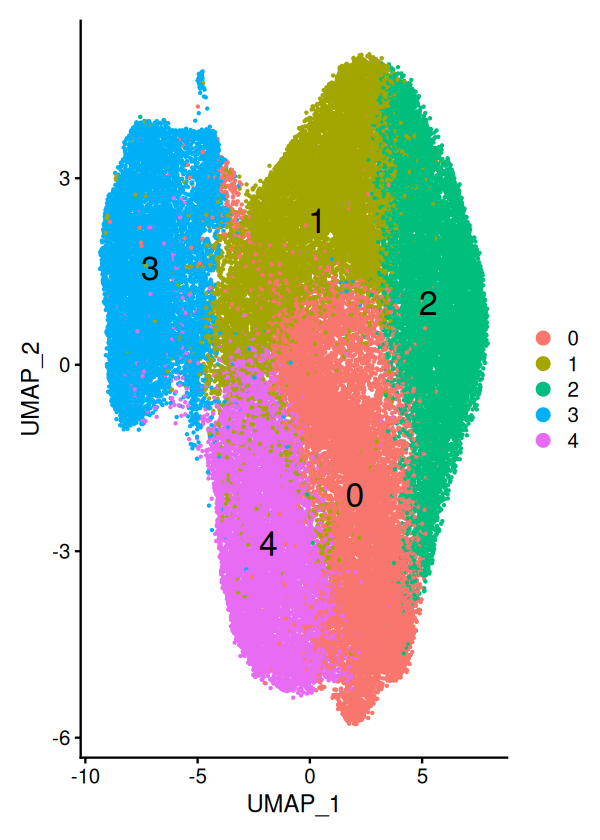

In [96]:
DimPlot(rios, label = T, label.size = 7)

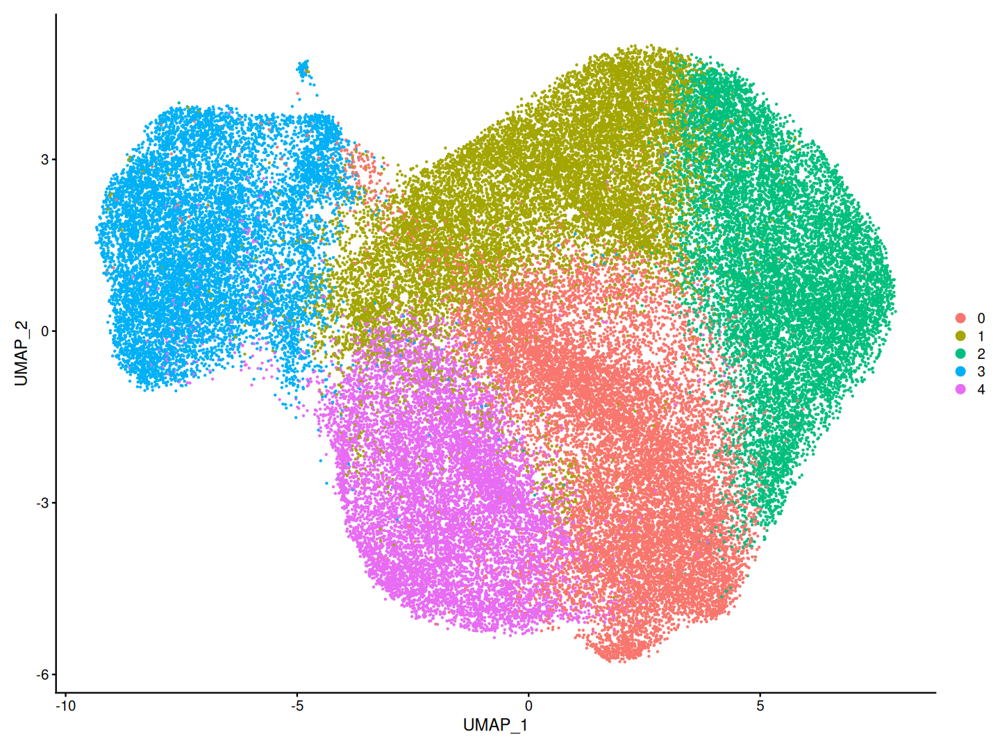

In [130]:
options(repr.plot.width = 12, repr.plot.height = 9)
DimPlot(rios, label = F)

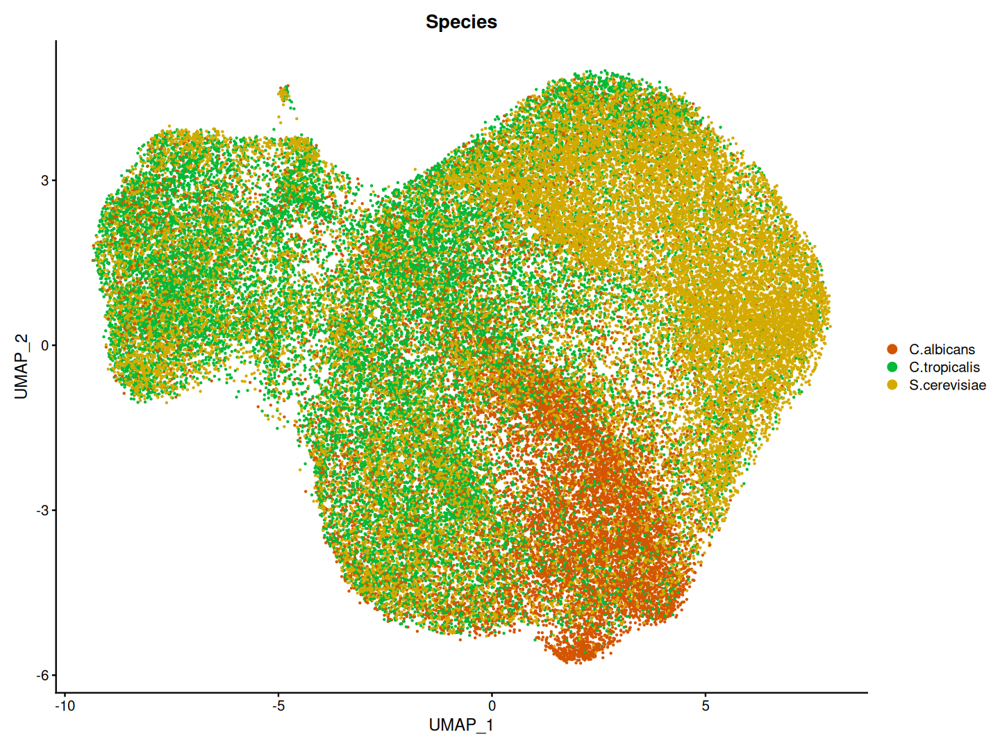

In [134]:
options(repr.plot.width = 12, repr.plot.height = 9)
DimPlot(rios, label = F, group.by = "Species", cols = c("#d45500ff", "#00ba38ff","#d4aa00ff" ))

In [97]:
gn2  <- c('GZMA', 'GZMB','GZMH','GNLY', 'IFNG', "PRF1",'CTSH', 
          'HLA-DRB5','FASLG',  'ZEB2',"RORC","TBX21","EOMES","BHLHE40",
          "IL23R",
          'IL12RB2', "CXCR6",
          'IL26', 'IL17A','IL22','CCL4', 'CSF2')


In [138]:
gn2  <- c('GZMA', 'GZMB','GZMH','GNLY', 'IFNG', "PRF1",'CTSH', 
            'ZEB2',"RORC","TBX21","EOMES","BHLHE40",
          "IL23R",
          'IL12RB2', "CXCR6",
          'IL26', 'IL17A','IL22','CCL4', 'CSF2')




In [139]:
avgexp3 = AverageExpression(rios, features = gn2, group.by = "seurat_clusters",
                          assay = "integrated")

Warning message:
“The following 1 features were not found in the integrated assay: EOMES”


In [140]:
avgexp3$integrated

19 x 5 sparse Matrix of class "dgCMatrix"
                  g0          g1           g2         g3          g4
GZMA     0.023815677  0.06158585   0.03598378 0.03591097 0.011272738
GZMB     1.215946181  6.05002757  14.60124634 0.28745855 0.603069529
GZMH     0.009245247  0.24094653   0.21125060 0.01238758 0.005011242
GNLY     0.083369931  0.59210133   0.46071796 0.10373442 0.039397154
IFNG    24.804493808  7.76601953 263.15996962 2.03609630 5.099879878
PRF1     0.239751836  1.37433969   2.07137273 0.13045889 0.083564432
CTSH     0.154338679  0.16234981   0.08938445 0.81172245 0.090628256
ZEB2     0.294582883  0.21337021   0.40120370 0.15453454 0.321029825
RORC     2.428210817  2.27747040   2.27501895 0.61272584 0.617937711
TBX21    0.726518826  0.77571679   1.40552022 0.24879904 0.441660232
BHLHE40  2.609068252  2.99649760   3.54072009 2.46391835 1.371974453
IL23R    0.058982787  0.06988272   0.20357812 0.05284572 0.022306572
IL12RB2  0.148376003  0.35870298   0.67002775 0.12529177 0.18

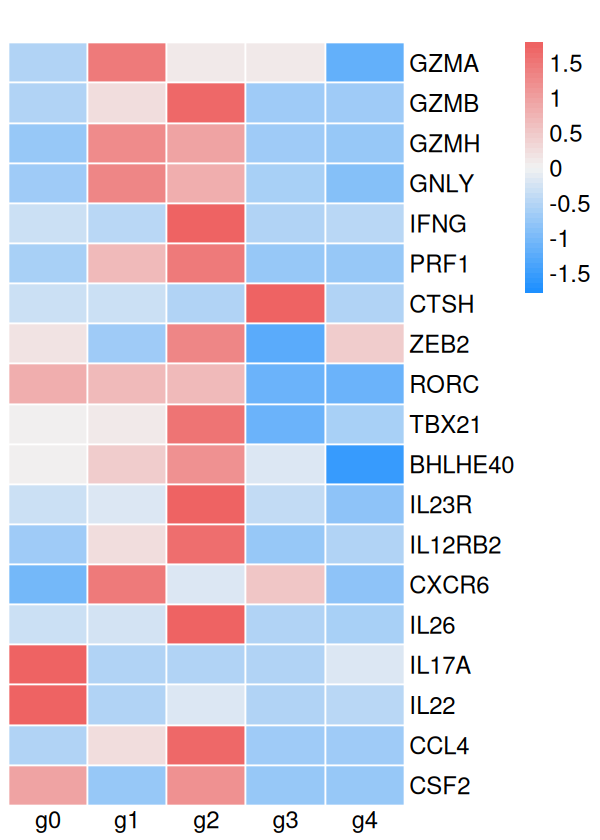

In [141]:
options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$integrated, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 14)

In [142]:
options(repr.plot.width = 5, repr.plot.height = 7 )
pheatmap::pheatmap(avgexp3$integrated, main = "", angle_col = 0,
         scale = "row", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50),
                   filename = "figures/rios/heatmap_markers.pdf",
                   width = 4, height = 7,
         border_color = "white",
                  fontsize = 14)

## Cluster frequency

In [153]:
# Create grouped dataframe, calculate the frequencies of clusters
df4 <- rios@meta.data  %>% 
  group_by(Source, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!Source, names_to = "seurat_clusters", values_to = "freq")

# Control - all sums should be one
# df4 %>% group_by(MouseID) %>% summarise(sum = sum(freq))

# As we've lost non-grouping variables, let's join them back
md_to_join <- rios@meta.data %>% 
  dplyr::select(Source, Condition) %>% 
  unique()

df4  <- left_join(df4, md_to_join)

`summarise()` has grouped output by 'Source'. You can override using the
`.groups` argument.
Joining with `by = join_by(Source)`


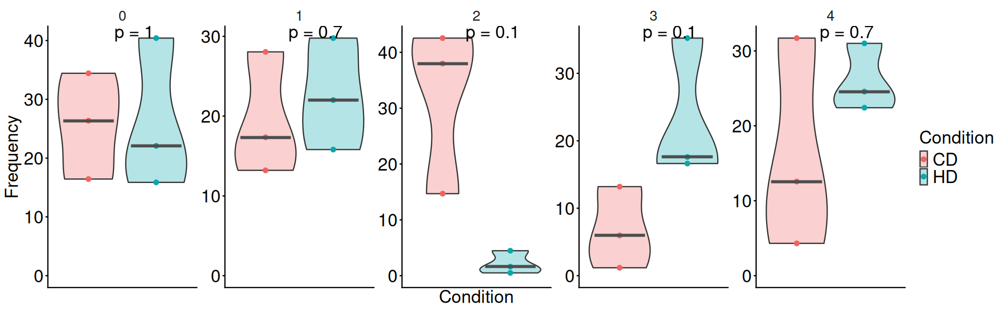

In [154]:
options(repr.plot.width = 16, repr.plot.height = 5)
df4 %>% 
  ggplot(aes(x = Condition, y = freq*100)) + # you can change the x to whatever variable you're interested in
    geom_violin(alpha = 0.3, aes(fill = Condition), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(aes(color = Condition), cex = 2, 
                shape = 16, corral = "random", size = 2.5) +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, scales = "free", ncol = 9) +
scale_fill_manual(values = c("indianred2", "#0aa7acff")) +
scale_color_manual(values = c("indianred2", "#0aa7acff")) +
  ylab("Frequency") +
  xlab("Condition") +
  theme_classic() +
ylim(c(0,NA)) +
  theme(strip.background = element_blank(), panel.grid = element_blank()) + 
  theme(axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        ) +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.5)  + ggtheme()



In [155]:
ggsave(filename = "figures/rios/cluster_frequency_CTL.svg",
      width = 26, height = 8, units = "cm", create.dir = T)

In [ ]:
CDR3b CASSSGQGMNTEAFF CDR3a CAGQAGNNRKLIW	

In [110]:
rios@meta.data <- rios@meta.data %>% mutate(
  clone_nt = paste(cdr3_B_nt,cdr3_A1_nt,cdr3_A2_nt),
  clone_aa = paste("CDR3b",cdr3_B,"CDR3a",cdr3_A1)
)

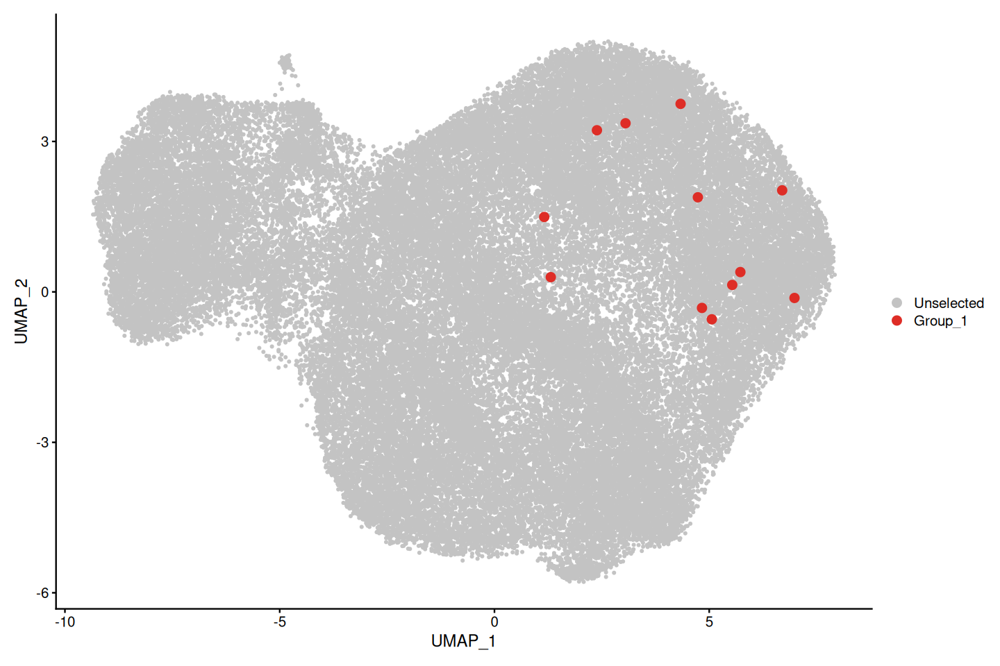

In [126]:
options(repr.plot.width = 12, repr.plot.height = 8)
DimPlot(rios, raster = F, pt.size = 0.5, 
           cells.highlight = colnames(rios)[grep(rios$clone_aa, pattern = "CDR3b CASSSGQGMNTEAFF CDR3a CAGQAGNNRKLIW")], 
        sizes.highlight = 3)

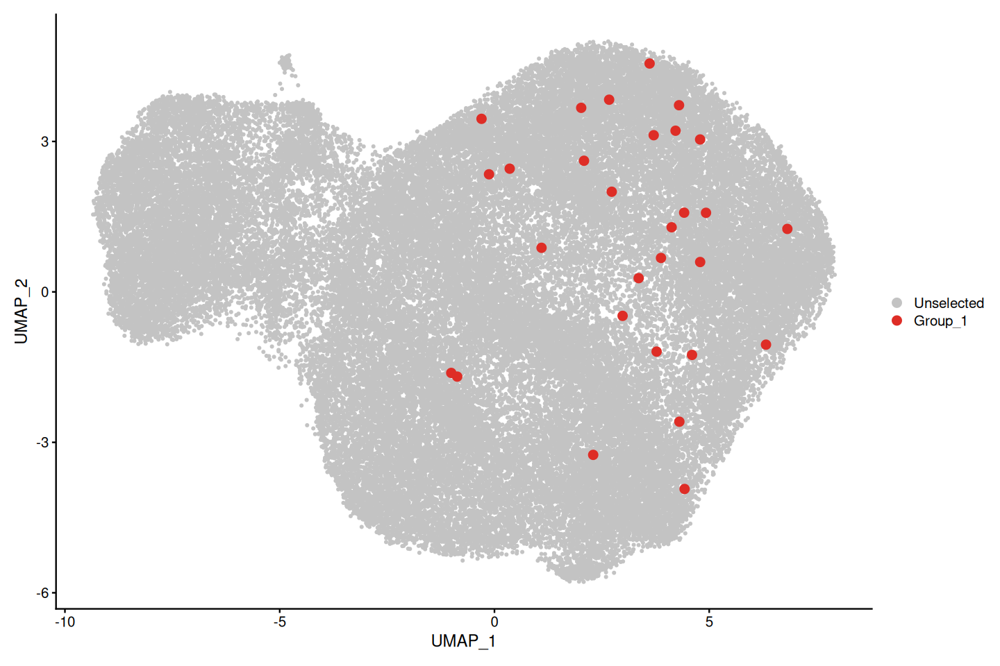

In [128]:

options(repr.plot.width = 12, repr.plot.height = 8)
DimPlot(rios, raster = F, pt.size = 0.5, 
           cells.highlight = colnames(rios)[grep(rios$clone_aa, pattern = "CDR3b CASSTGQGMNTEAFF CDR3a CAGQAGNNRKLIW")], 
        sizes.highlight = 3)

In [112]:
metadata_6 <- rios@meta.data

clone_table <- metadata_6 %>%
  dplyr::group_by(clone_aa) %>%
          dplyr::summarize(n = n(), sum = sum()) %>%
    arrange(desc(n))

clone_table

clone_aa,n,sum
<chr>,<int>,<int>
CDR3b NA CDR3a NA,8627,0
CDR3b CASSEPGQGDQPQHF CDR3a CAVSTTGGFKTIF,1213,0
CDR3b CASSGPGQGDQPQHF CDR3a CAVSGVGGFKTIF,836,0
CDR3b CASSQGLGQGHSPLHF CDR3a CAMTRTGTASKLTF,790,0
CDR3b CASSLPDGSGNTIYF CDR3a CAVSNTGGFKTIF,684,0
CDR3b CSADRGNYGYTF CDR3a CAVPRGSNYKLTF,458,0
CDR3b CASSLSTGGAGELFF CDR3a CAASKKGAGGTSYGKLTF,456,0
CDR3b CASSLATGTDGGETQYF CDR3a CAVRDTGFQKLVF,454,0
CDR3b CASSLPTGGYNSPLHF CDR3a CAVSETGGFKTIF,319,0


In [115]:
clone_table  <- clone_table  %>% dplyr::filter(!grepl(clone_aa, pattern = " NA"))

In [116]:
metadata_6$test <- 0
metadata_6 <- metadata_6 %>% group_by(test, clone_aa) %>% mutate(clone_abundance = as.numeric(n()))


metadata_6 <- as.data.frame(metadata_6 %>% mutate(clone_abundance = 
                                                  as.numeric(ifelse(clone_abundance>8000,
                                                  NA_integer_,clone_abundance))) %>%
  mutate(log_clone_abundance = log(clone_abundance, base = 2)))

In [117]:
rownames(metadata_6) <- colnames(rios)

rios@meta.data <- metadata_6

Warning message:
“Removing 8627 cells missing data for vars requested”


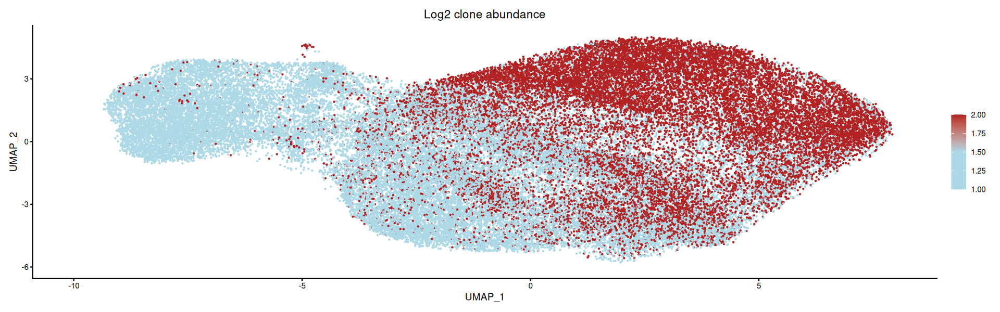

In [118]:
options(repr.plot.width = 16, repr.plot.height = 5)
FeaturePlot(subset(rios, clone_abundance >=1 & clone_abundance < 2000), 
            reduction = "umap", features = "log_clone_abundance", 
            cols = c("lightblue","lightblue","firebrick"), max.cutoff = 6) + 
theme_classic() + theme(plot.title = element_text(hjust = 0.5)) + ggtitle("Log2 clone abundance")

Warning message:
“Removing 8627 cells missing data for vars requested”


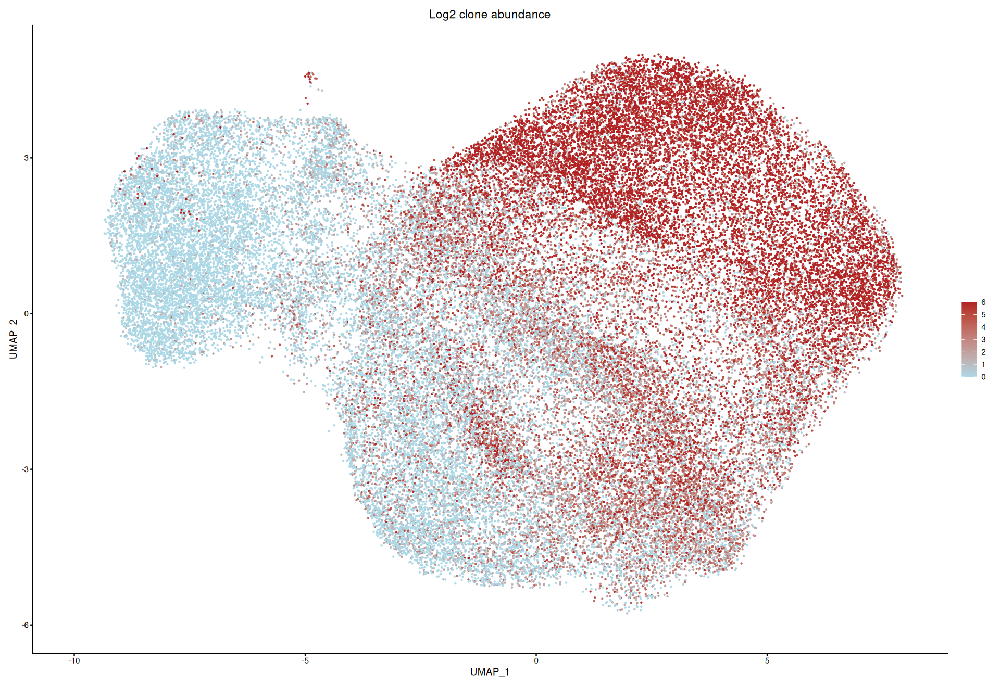

In [123]:
options(repr.plot.width = 16, repr.plot.height = 11)
FeaturePlot(subset(rios, clone_abundance >=1 & clone_abundance < 2000), 
            reduction = "umap", features = "log_clone_abundance", 
            cols = c("lightblue","firebrick"), max.cutoff = 6) + 
theme_classic() + theme(plot.title = element_text(hjust = 0.5)) + ggtitle("Log2 clone abundance")

In [114]:
clone_table2 <- metadata_6 %>%
  dplyr::group_by(clone_aa, Sample) %>%
          dplyr::summarize(n = n(), sum = sum()) %>%
    arrange(desc(n))

clone_table2 %>% dplyr::filter(grepl(clone_aa, pattern = "CASSSGQGMNTEAFF"))

`summarise()` has grouped output by 'clone_aa'. You can override using the
`.groups` argument.


clone_aa,Sample,n,sum
<chr>,<chr>,<int>,<int>
CDR3b CASSSGQGMNTEAFF CDR3a CAGQAGNNRKLIW,CD3GEX S.cerevisiae,12,0
CDR3b CASSSGQGMNTEAFF CDR3a NA,CD3GEX S.cerevisiae,2,0


# Li Yim et al. vedolizumab

In [3]:
liyim  <- Read10X("data/Li_Yim_et_al/scrnaseq/mtx/")

In [4]:
liyim

  [[ suppressing 32 column names ‘S20191122_SCS14_AAACCCAAGAATTCAG-1’, ‘S20191122_SCS14_AAACCCAAGACTTCAC-1’, ‘S20191122_SCS14_AAACCCAAGCAATTAG-1’ ... ]]

  [[ suppressing 32 column names ‘S20191122_SCS14_AAACCCAAGAATTCAG-1’, ‘S20191122_SCS14_AAACCCAAGACTTCAC-1’, ‘S20191122_SCS14_AAACCCAAGCAATTAG-1’ ... ]]

  [[ suppressing 32 column names ‘S20191122_SCS14_AAACCCAAGAATTCAG-1’, ‘S20191122_SCS14_AAACCCAAGACTTCAC-1’, ‘S20191122_SCS14_AAACCCAAGCAATTAG-1’ ... ]]



28165 x 15981 sparse Matrix of class "dgCMatrix"
                                                                                            
AL627309.1   . .  .  .  .  .  .  .  .  .  .  .  .  1 .  .  .  .  .  .  .  .  .  .  . .  .  .
AL627309.5   . .  .  .  .  .  .  .  .  .  .  1  .  . .  .  .  .  .  .  .  .  .  .  . .  .  .
AL627309.4   . .  .  .  .  .  .  .  .  .  .  .  .  . .  .  .  .  .  .  .  .  .  .  . .  .  .
AC114498.1   . .  .  .  .  .  .  .  .  .  .  .  .  . .  .  .  .  .  .  .  .  .  .  . .  .  .
AL669831.2   . .  .  .  .  .  .  .  .  .  .  .  .  . .  .  .  .  .  .  .  .  .  .  . .  .  .
LINC01409    . .  .  .  .  .  .  .  .  .  .  .  .  . .  1  .  1  .  .  .  .  .  .  . .  .  .
FAM87B       . .  .  .  .  .  .  .  .  .  .  .  .  . .  .  .  .  .  .  .  .  .  .  . .  .  .
LINC01128    . .  .  .  .  .  .  .  .  .  1  .  .  . .  .  .  .  .  .  .  .  .  .  1 .  .  1
LINC00115    . .  .  .  .  .  .  .  .  1  .  .  .  . .  .  .  .  .  .  .  .  .  .  . .  .  .
FAM41C       . .  .  

In [5]:
dim(liyim)

[1] 28165 15981

In [6]:
genes  <- rownames(liyim)

In [7]:
genes_filt  <- genes[!(grepl(genes, pattern = "^MT")|
                            grepl(genes, pattern = "\\.")|
                            grepl(genes, pattern = "LINC")|
                            grepl(genes, pattern = "^MIR")|
                            grepl(genes, pattern = "^MT")|
                            grepl(genes, pattern = "HNRNP")|
                            grepl(genes, pattern = "^RP[LS]")|
                            grepl(genes, pattern = "\\-")|
                            grepl(genes, pattern = "TTTY")|
                            grepl(genes, pattern = "ORF")|
                            grepl(genes, pattern = "orf"))
                            ]


In [8]:
length(genes_filt)

[1] 16885

In [9]:
liyim_filt  <- liyim[rownames(liyim) %in% genes_filt,]

In [10]:
dim(liyim_filt)

[1] 16885 15981

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

PC_ 1 
Positive:  BCL2, INPP4B, BACH2, IL7R, THEMIS, LEF1, ANK3, MLLT3, IL32, APBA2 
	   NELL2, FUT8, SAMD3, PCAT1, PYHIN1, GLCCI1, CD69, TRBC1, TSHZ2, NCALD 
	   TAFA1, FAAH2, MYBL1, CSGALNACT1, EPHA4, TGFBR3, PLCL1, ICOS, LRIG1, AK5 
Negative:  FCN1, LYZ, SLC8A1, CLEC7A, PLXDC2, MNDA, CST3, LRMDA, S100A9, IFI30 
	   CPVL, CSTA, CSF3R, VCAN, FGL2, SERPINA1, SPI1, S100A8, WDFY3, SLC11A1 
	   MCTP1, CD36, CD14, RBM47, TNFAIP2, PLAUR, IRAK3, MS4A6A, CD68, DMXL2 
PC_ 2 
Positive:  SAMHD1, IL32, LCP2, SLCO3A1, ANXA1, IL7R, INPP4B, THEMIS, DPYD, S100A4 
	   SAMD3, SRGN, NCALD, MYO1F, FNDC3B, TGFBR3, MYBL1, ID2, CCL5, GNAQ 
	   CTSW, NKG7, AOAH, PYHIN1, ARHGAP26, CST7, GZMA, TRBC1, LEF1, PLCB1 
Negative:  BANK1, PAX5, FCRL1, MS4A1, NIBAN3, AFF3, CD79A, EBF1, BLK, RALGPS2 
	   IGHM, OSBPL10, ADAM28, COBLL1, ARHGAP24, WDFY4, COL19A1, RUBCNL, CD22, CDK14 
	   GNG7, CD79B, BCL11A, SWAP70, KH

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 15981
Number of edges: 613621

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9329
Number of communities: 22
Elapsed time: 2 seconds


Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
11:38:09 UMAP embedding parameters a = 0.9922 b = 1.112

11:38:09 Read 15981 rows and found 30 numeric columns

11:38:09 Using Annoy for neighbor search, n_neighbors = 30

11:38:09 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:38:11 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpYlKnlC/file2da0d26f76c260

11:38:11 Searching Annoy index using 1 thread, search_k = 3000

11:38:17 Annoy recall = 100%

11:38:19 Commencing smooth kNN distance calibration using 1 thread
 with 

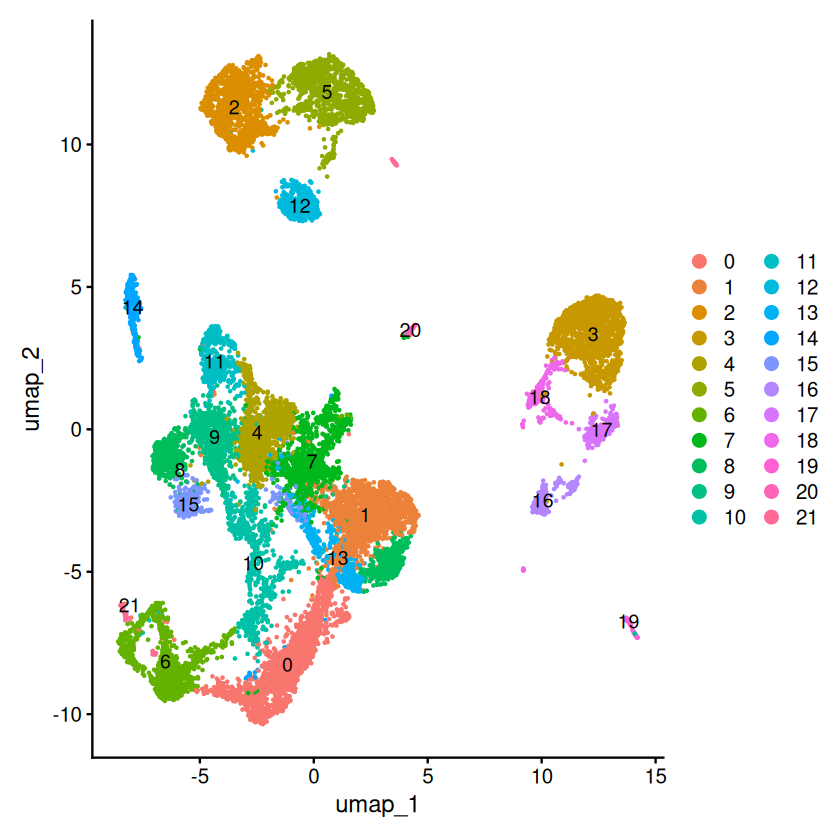

In [11]:
# Keep genes detected in at least 3 retained cells
liyim <- CreateSeuratObject(
  counts = liyim_filt,
  project = "liyim",
  min.cells = 3,
  min.features = 200
)

liyim <- NormalizeData(liyim)
liyim <- FindVariableFeatures(
  liyim,
  selection.method = "vst",
  nfeatures = 2000
)

# Scale only variable genes to limit memory use
liyim <- ScaleData(liyim, features = VariableFeatures(liyim))
liyim <- RunPCA(liyim, features = VariableFeatures(liyim), npcs = 30)

liyim <- FindNeighbors(liyim, dims = 1:30)
liyim <- FindClusters(liyim, resolution = 0.5)
liyim <- RunUMAP(liyim, dims = 1:30, seed.use = 123)

DimPlot(liyim, reduction = "umap", label = TRUE)

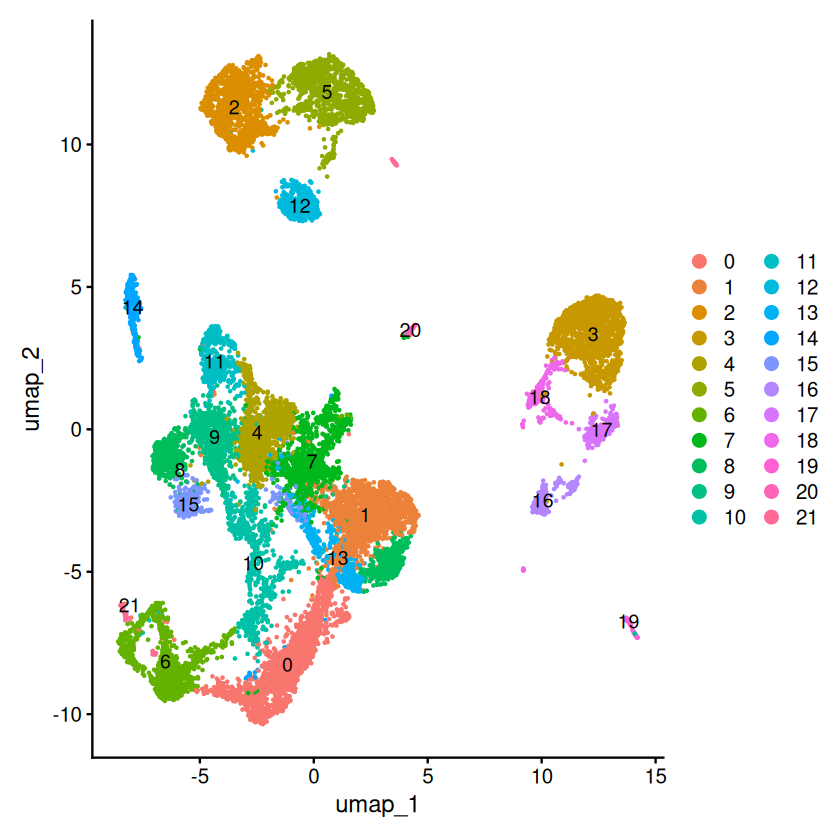

In [12]:
DimPlot(liyim, reduction = "umap", label = TRUE)

In [13]:
DefaultAssay(liyim) <- "RNA"

pbmc_markers <- c(
  "CD3E",             # T cells
  "IL7R", "CCR7",     # CD4 / naive-memory T cells
  "CD8A",             # CD8 T cells
  "GNLY", "NKG7",     # NK / cytotoxic lymphocytes
  "MS4A1",            # B cells
  "CD14", "LYZ",      # Classical monocytes
  "FCGR3A", "MS4A7",  # CD16 monocytes
  "FCER1A", "CST3",   # Dendritic / myeloid cells
  "PPBP"              # Platelets
)

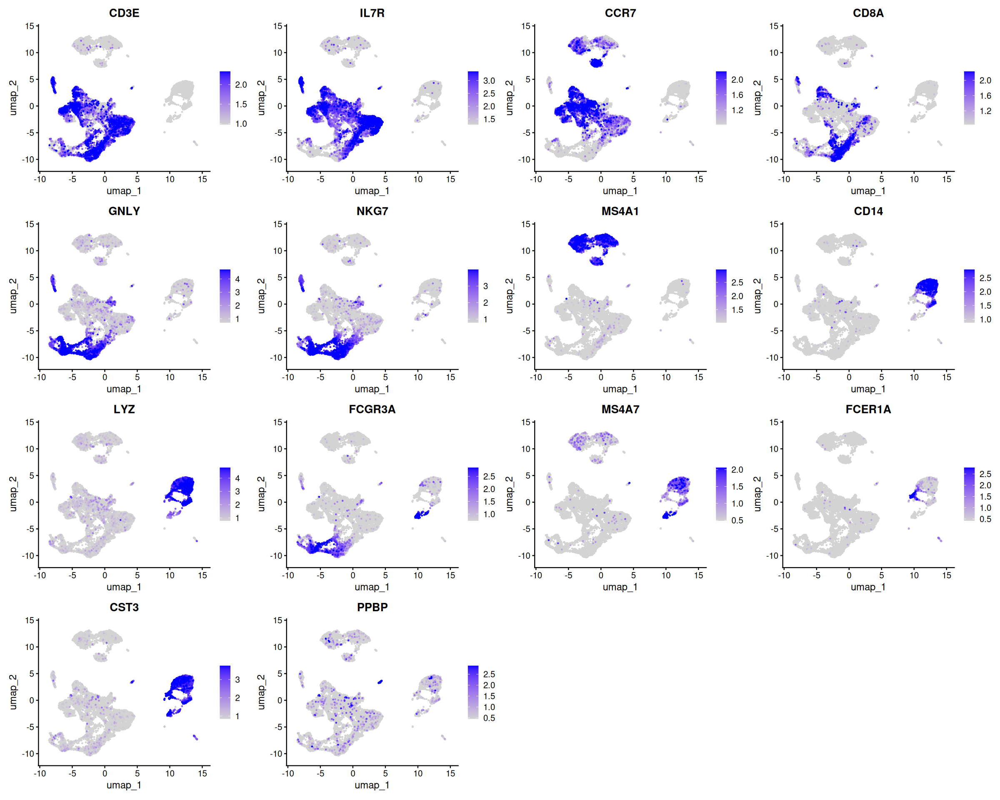

In [15]:
options(repr.plot.width = 20, repr.plot.height = 16)
FeaturePlot(
  liyim,
  features = intersect(pbmc_markers, rownames(liyim)),
  reduction = "umap",
  ncol = 4,
  order = TRUE,
  min.cutoff = "q10",
  max.cutoff = "q90")


In [16]:
liyim <- FindClusters(liyim, resolution = 0.1)


Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 15981
Number of edges: 613621

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9669
Number of communities: 11
Elapsed time: 2 seconds


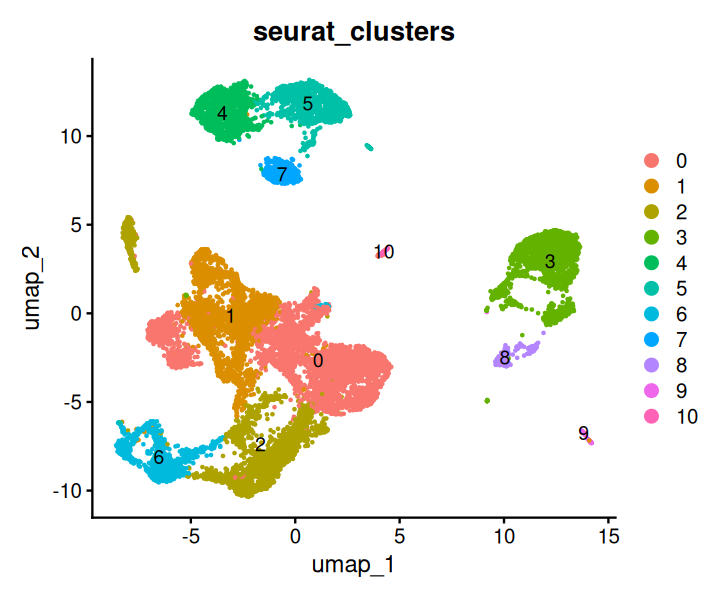

In [19]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(liyim, reduction = "umap", label = TRUE, group.by = "seurat_clusters")

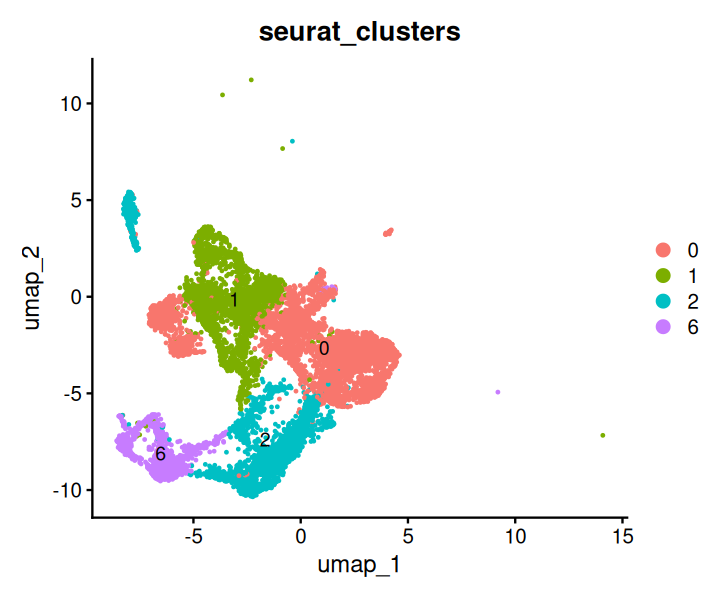

In [20]:
liyim_tcells  <- subset(liyim, seurat_clusters %in% c(0,1,2,6))
DimPlot(liyim_tcells, reduction = "umap", label = TRUE, group.by = "seurat_clusters")

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
PC_ 1 
Positive:  NKG7, CST7, GNLY, KLRD1, PRF1, ZEB2, GZMA, EFHD2, CCL5, GZMB 
	   FGFBP2, CTSW, KLRF1, HOPX, MYO1F, PLEK, FCGR3A, GZMH, TGFBR3, CCL4 
	   AOAH, MATK, SPON2, TYROBP, MCTP2, ADGRG1, LYN, ADGRG5, FCRL6, VAV3 
Negative:  CAMK4, LEF1, SERINC5, PRKCA, FOXP1, MAML2, INPP4B, BACH2, PLCL1, TRABD2A 
	   FHIT, PDE3B, IL6ST, NELL2, ANK3, CSGALNACT1, TSHZ2, MAL, RETREG1, IL7R 
	   HIVEP2, MLLT3, SESN3, BCL2, MAN1C1, NR3C2, RNF157, ITGA6, TGFBR2, ACTN1 
PC_ 2 
Positive:  IGF1R, TXK, CTBP2, CERS6, APBA2, KLRF1, FCER1G, ATP10A, IGFBP7, ATP8B4 
	   NCR1, NCAM1, PCSK5, BNC2, SH2D1B, OSBPL5, AK5, CD38, LYN, PTPN12 
	   L3MBTL4, SYK, FNDC3B, RNF165, FHIT, GFOD1, GSAP, TYROBP, AOAH, BACH2 
Negative:  CD52, VIM, IL32, S100A10, S100A6, S100A4, TPT1, CRIP1, EEF1A1, SH3BGRL3 
	   EEF1B2, TMSB4X, S10

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 10888
Number of edges: 413378

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9148
Number of communities: 15
Elapsed time: 1 seconds


11:45:50 UMAP embedding parameters a = 0.9922 b = 1.112

11:45:50 Read 10888 rows and found 30 numeric columns

11:45:50 Using Annoy for neighbor search, n_neighbors = 30

11:45:50 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:45:52 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpYlKnlC/file2da0d22f62e9b2

11:45:52 Searching Annoy index using 1 thread, search_k = 3000

11:45:55 Annoy recall = 100%

11:45:57 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

11:46:00 Initializing from normalized Laplacian + noise (using RSpectra)

11:46:01 Commencing optimization for 200 epochs, with 451724 positive edges

11:46:01 Using rng type: pcg

11:46:08 Optimization finished



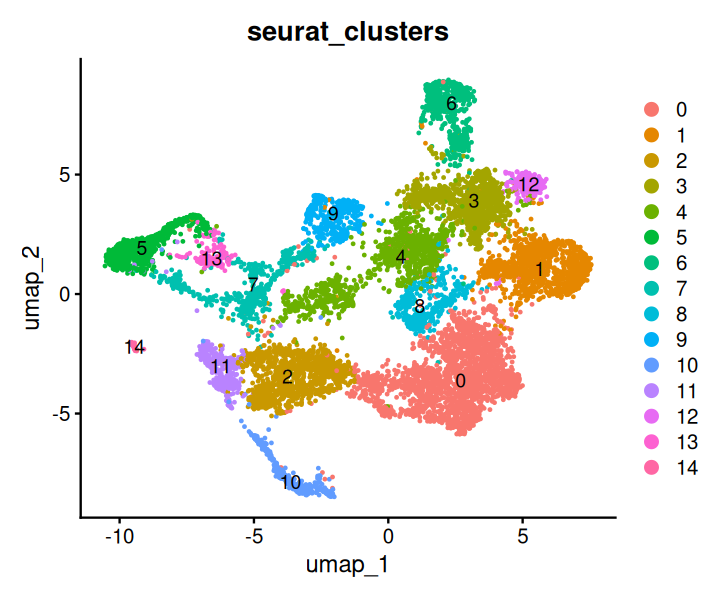

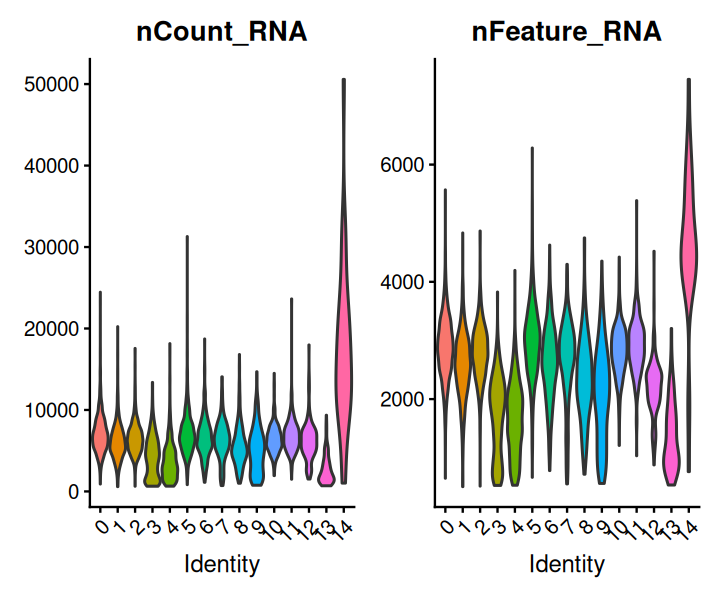

In [21]:
DefaultAssay(liyim_tcells) <- "RNA"
set.seed(123)

liyim_tcells <- NormalizeData(liyim_tcells)
liyim_tcells <- FindVariableFeatures(liyim_tcells, nfeatures = 2000)
liyim_tcells <- ScaleData(
  liyim_tcells,
  features = VariableFeatures(liyim_tcells)
)
liyim_tcells <- RunPCA(liyim_tcells, npcs = 30)
liyim_tcells <- FindNeighbors(liyim_tcells, dims = 1:30)
liyim_tcells <- FindClusters(liyim_tcells, resolution = 0.5)
liyim_tcells <- RunUMAP(liyim_tcells, dims = 1:30, seed.use = 123)

DimPlot(
  liyim_tcells,
  reduction = "umap",
  label = TRUE,
  group.by = "seurat_clusters"
)

VlnPlot(
  liyim_tcells,
  features = c("nCount_RNA", "nFeature_RNA"),
  group.by = "seurat_clusters",
  pt.size = 0,
  ncol = 2
)

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
PC_ 1 
Positive:  CAMK4, LEF1, SERINC5, PRKCA, FOXP1, MAML2, INPP4B, BACH2, TRABD2A, PLCL1 
	   IL6ST, PDE3B, FHIT, NELL2, ANK3, CSGALNACT1, IL7R, MAL, TSHZ2, HIVEP2 
	   RETREG1, MLLT3, SESN3, BCL2, MAN1C1, NR3C2, RNF157, TGFBR2, ITGA6, ACTN1 
Negative:  NKG7, CST7, GNLY, KLRD1, PRF1, ZEB2, GZMA, EFHD2, CCL5, GZMB 
	   FGFBP2, CTSW, MYO1F, KLRF1, HOPX, PLEK, FCGR3A, GZMH, TGFBR3, CCL4 
	   AOAH, MATK, SPON2, TYROBP, MCTP2, LYN, ADGRG1, ADGRG5, RAP1GAP2, SAMD3 
PC_ 2 
Positive:  TXK, IGF1R, CERS6, APBA2, FCER1G, KLRF1, CTBP2, ATP10A, IGFBP7, PCSK5 
	   ATP8B4, NCR1, AK5, NCAM1, SH2D1B, BNC2, CD38, OSBPL5, TYROBP, FNDC3B 
	   LYN, FHIT, PTPN12, SYK, L3MBTL4, BACH2, RNF165, GSAP, GFOD1, HIPK2 
Negative:  IL32, CD52, VIM, S100A10, S100A6, S100A4, CRIP1, TPT1, EEF1A1, SH3BGRL3 
	   S100A11, TMSB4

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 10300
Number of edges: 391816

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9471
Number of communities: 11
Elapsed time: 1 seconds


11:48:26 UMAP embedding parameters a = 0.9922 b = 1.112

11:48:26 Read 10300 rows and found 30 numeric columns

11:48:26 Using Annoy for neighbor search, n_neighbors = 30

11:48:26 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:48:28 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpYlKnlC/file2da0d216eb4041

11:48:28 Searching Annoy index using 1 thread, search_k = 3000

11:48:32 Annoy recall = 100%

11:48:33 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

11:48:37 Initializing from normalized Laplacian + noise (using RSpectra)

11:48:37 Commencing optimization for 200 epochs, with 426760 positive edges

11:48:37 Using rng type: pcg

11:48:44 Optimization finished



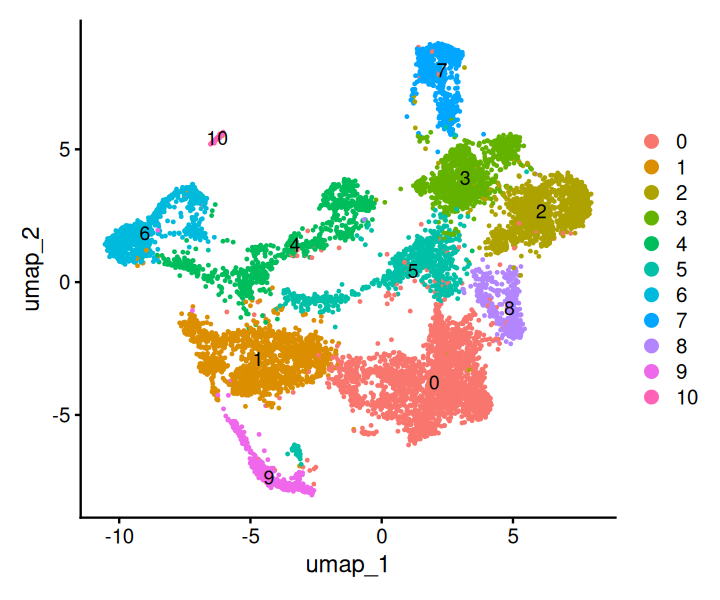

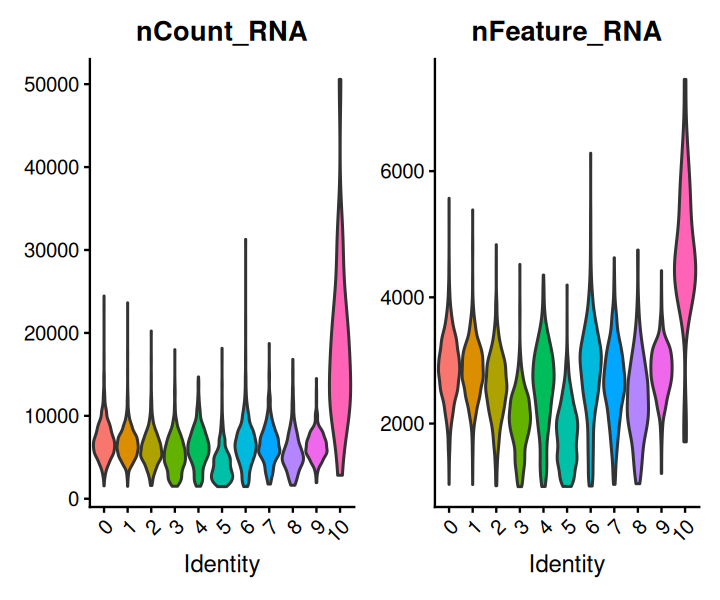

In [22]:
# Keep T cells with >1000 detected genes
liyim_tcells <- subset(liyim_tcells, subset = nFeature_RNA > 1000)

DefaultAssay(liyim_tcells) <- "RNA"
set.seed(123)

# Recompute normalization and variable genes
liyim_tcells <- NormalizeData(liyim_tcells)
liyim_tcells <- FindVariableFeatures(liyim_tcells, nfeatures = 2000)
liyim_tcells <- ScaleData(
  liyim_tcells,
  features = VariableFeatures(liyim_tcells)
)

# Recompute PCA, clustering, and UMAP
liyim_tcells <- RunPCA(liyim_tcells, npcs = 30)
liyim_tcells <- FindNeighbors(liyim_tcells, dims = 1:30)
liyim_tcells <- FindClusters(liyim_tcells, resolution = 0.2)
liyim_tcells <- RunUMAP(liyim_tcells, dims = 1:30, seed.use = 123)

DimPlot(liyim_tcells, reduction = "umap", label = TRUE)

VlnPlot(
  liyim_tcells,
  features = c("nCount_RNA", "nFeature_RNA"),
  group.by = "seurat_clusters",
  pt.size = 0,
  ncol = 2
)

## Add metadata

In [23]:
md  <- read_csv("data/Li_Yim_et_al/scrnaseq/cell_metadata.csv")

Rows: 15981 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (10): CellID, RunID, SampleID, Sex, Smoker, Response, manual_l1, manual_...
dbl  (2): Age, seurat_clusters

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [24]:
md

CellID,RunID,SampleID,Sex,Age,Smoker,Response,manual_l1,manual_l2,manual_l3,manual_l4,seurat_clusters
<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
S20191122_SCS14_AAACCCAAGAATTCAG-1,20191122-SCS14,F334,Female,38,Yes,Non-responder,T,CD4T,CD4 naive,CD4 naive,5
S20191122_SCS14_AAACCCAAGACTTCAC-1,20191122-SCS14,F200,Female,26,No,Responder,T,CD4T,CD4 naive,CD4 naive,2
S20191122_SCS14_AAACCCAAGCAATTAG-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 naive,CD4 naive,5
S20191122_SCS14_AAACCCAAGCAGAAAG-1,20191122-SCS14,F200,Female,26,No,Responder,T,other T,GDT,GDT,1
S20191122_SCS14_AAACCCAAGGCTCTCG-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 naive,CD4 naive,5
S20191122_SCS14_AAACCCAAGGGAGAAT-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 naive,CD4 naive,5
S20191122_SCS14_AAACCCAAGGTGCTAG-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 naive,CD4 naive,4
S20191122_SCS14_AAACCCAAGTAAATGC-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 TEM,CD4 TEM,0
S20191122_SCS14_AAACCCAAGTATAGAC-1,20191122-SCS14,F213,Female,71,No,Non-responder,B,B intermediate,B intermediate,B intermediate lambda,9


In [25]:
table(colnames(liyim_tcells) %in% md$CellID)


 TRUE 
10300 

In [26]:
md2  <- liyim_tcells@meta.data  

In [27]:
md2$CellID  <- colnames(liyim_tcells)

In [29]:
md2  <- md2  %>% dplyr::select(-seurat_clusters)

In [30]:
md2  <- left_join(md2, md)

Joining with `by = join_by(CellID)`


In [31]:
rownames(md2)  <- colnames(liyim_tcells)

In [32]:
md2

,orig.ident,nCount_RNA,nFeature_RNA,RNA_snn_res.0.5,RNA_snn_res.0.1,RNA_snn_res.0.2,CellID,RunID,SampleID,Sex,Age,Smoker,Response,manual_l1,manual_l2,manual_l3,manual_l4,seurat_clusters
,<fct>,<dbl>,<int>,<fct>,<fct>,<fct>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
S20191122_SCS14_AAACCCAAGAATTCAG-1,S20191122,2452,1360,3,1,3,S20191122_SCS14_AAACCCAAGAATTCAG-1,20191122-SCS14,F334,Female,38,Yes,Non-responder,T,CD4T,CD4 naive,CD4 naive,5
S20191122_SCS14_AAACCCAAGACTTCAC-1,S20191122,1784,1025,3,1,3,S20191122_SCS14_AAACCCAAGACTTCAC-1,20191122-SCS14,F200,Female,26,No,Responder,T,CD4T,CD4 naive,CD4 naive,2
S20191122_SCS14_AAACCCAAGCAATTAG-1,S20191122,5194,2039,3,0,3,S20191122_SCS14_AAACCCAAGCAATTAG-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 naive,CD4 naive,5
S20191122_SCS14_AAACCCAAGCAGAAAG-1,S20191122,5581,2559,10,2,9,S20191122_SCS14_AAACCCAAGCAGAAAG-1,20191122-SCS14,F200,Female,26,No,Responder,T,other T,GDT,GDT,1
S20191122_SCS14_AAACCCAAGGCTCTCG-1,S20191122,6472,2161,3,1,3,S20191122_SCS14_AAACCCAAGGCTCTCG-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 naive,CD4 naive,5
S20191122_SCS14_AAACCCAAGGGAGAAT-1,S20191122,4272,1840,3,1,3,S20191122_SCS14_AAACCCAAGGGAGAAT-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 naive,CD4 naive,5
S20191122_SCS14_AAACCCAAGGTGCTAG-1,S20191122,6053,2594,1,1,2,S20191122_SCS14_AAACCCAAGGTGCTAG-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 naive,CD4 naive,4
S20191122_SCS14_AAACCCAAGTAAATGC-1,S20191122,4294,2215,0,0,0,S20191122_SCS14_AAACCCAAGTAAATGC-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 TEM,CD4 TEM,0
S20191122_SCS14_AAACCCACAAAGGTTA-1,S20191122,5319,2544,0,0,0,S20191122_SCS14_AAACCCACAAAGGTTA-1,20191122-SCS14,F291,Female,32,NA,Non-responder,T,CD4T,CD4 TCM,CD4 TCM,0


In [33]:
liyim_tcells@meta.data  <- md2

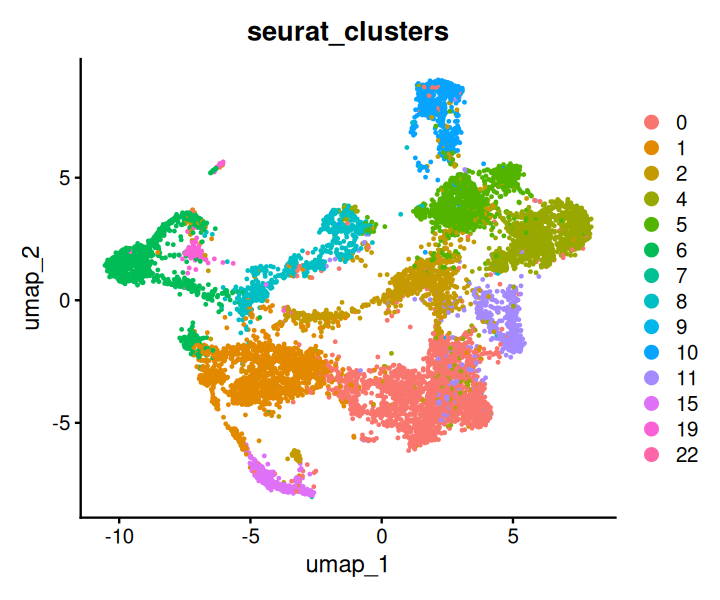

In [34]:
DimPlot(liyim_tcells, group.by = "seurat_clusters")

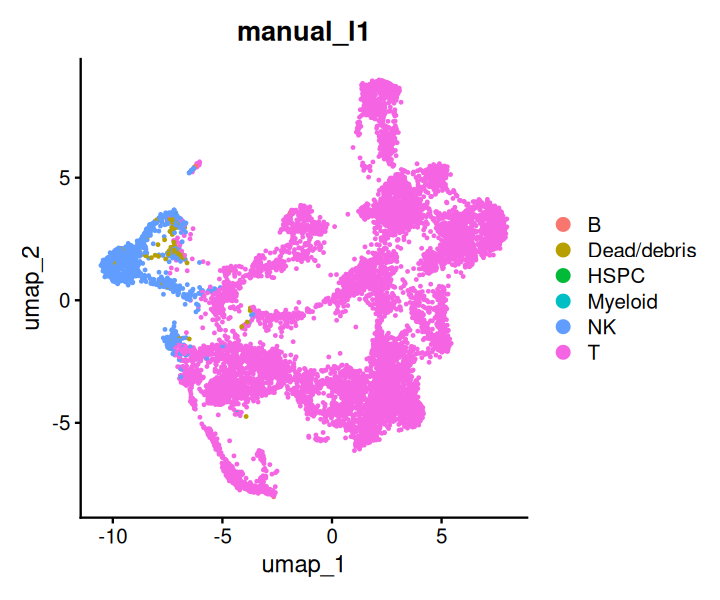

In [35]:
DimPlot(liyim_tcells, group.by = "manual_l1")

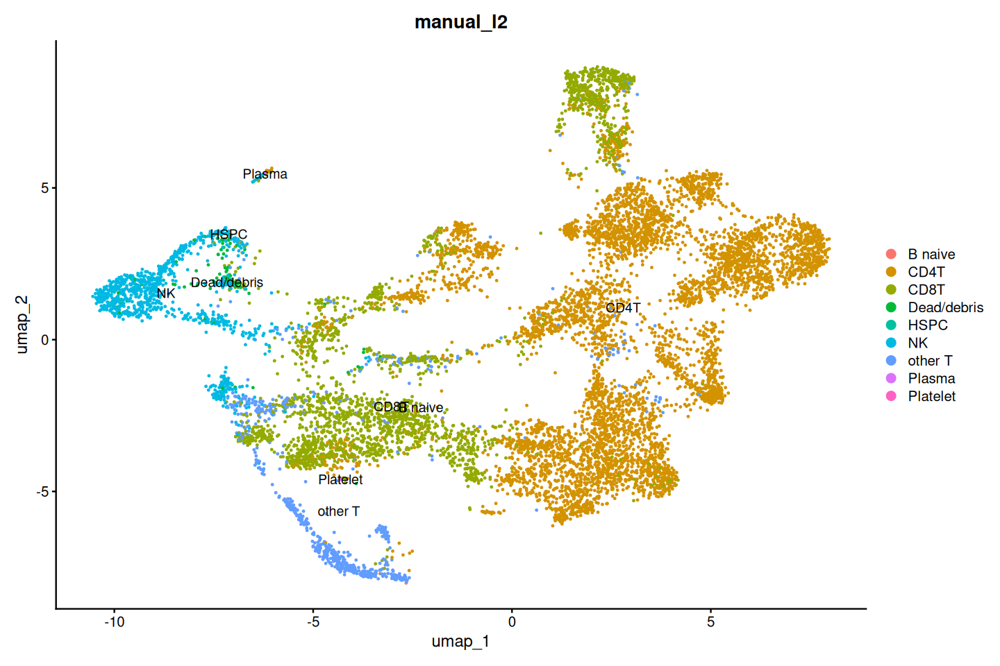

In [38]:
options(repr.plot.width = 12, repr.plot.height = 8)
DimPlot(liyim_tcells, group.by = "manual_l2", label = T)

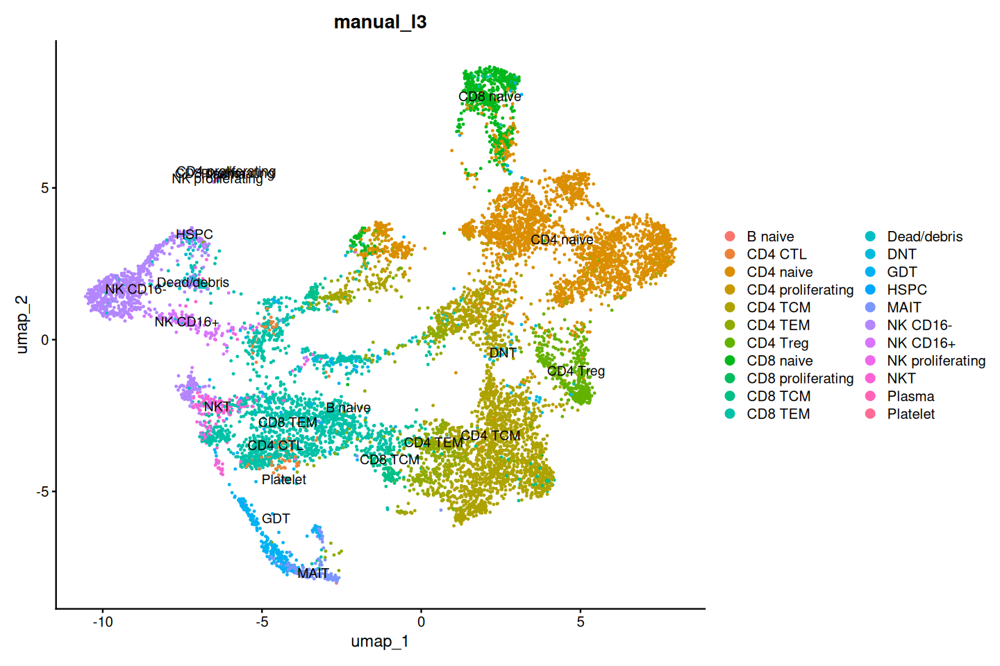

In [39]:
DimPlot(liyim_tcells, group.by = "manual_l3", label = T)

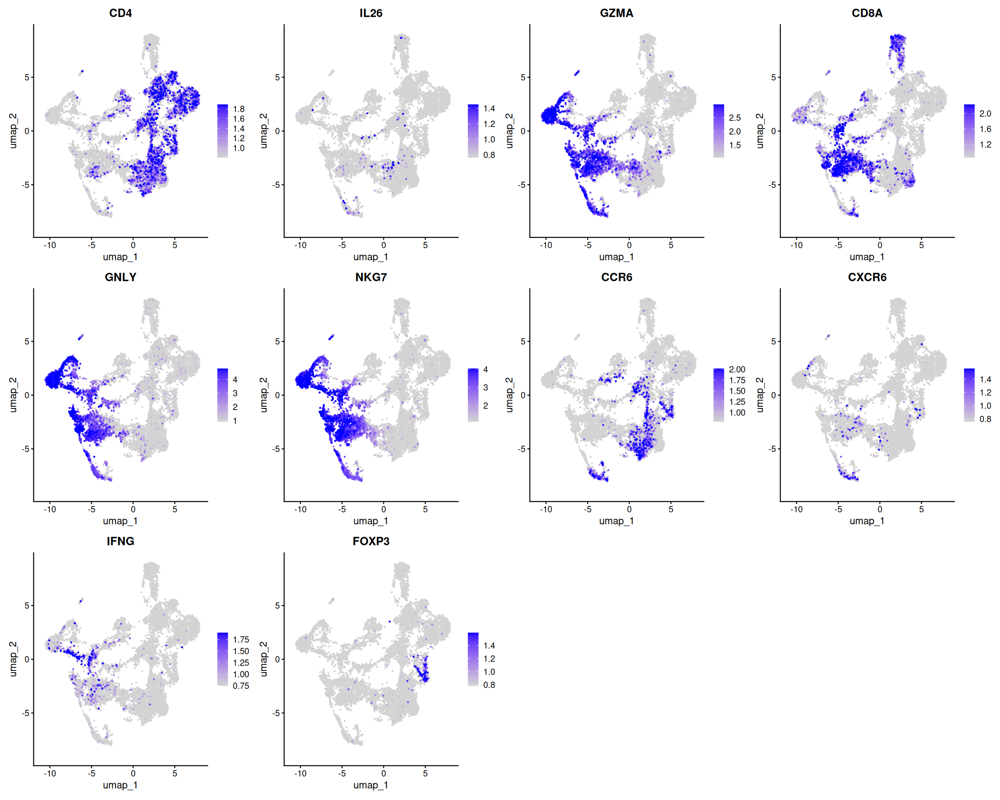

In [42]:
cd4_ctl_markers <- c(
  "CD4", "IL26", "GZMA",  
  "CD8A", "GNLY", "NKG7",  
  "CCR6", "CXCR6", "IFNG",    
  "FOXP3"
)

options(repr.plot.width = 20, repr.plot.height = 16)
FeaturePlot(
  liyim_tcells,
  features = cd4_ctl_markers,
  reduction = "umap",
  ncol = 4,
  order = TRUE,
  min.cutoff = "q10",
  max.cutoff = "q90")


In [44]:
colnames(liyim_tcells@meta.data)

[1] "orig.ident"      "nCount_RNA"      "nFeature_RNA"    "RNA_snn_res.0.5"
 [5] "RNA_snn_res.0.1" "RNA_snn_res.0.2" "CellID"          "RunID"          
 [9] "SampleID"        "Sex"             "Age"             "Smoker"         
[13] "Response"        "manual_l1"       "manual_l2"       "manual_l3"      
[17] "manual_l4"       "seurat_clusters"

In [45]:
liyim_tcells$Response  %>% table

.
Non-responder     Responder 
         5159          5141 

In [46]:
liyim_tcells$SampleID  %>% table

.
F140 F200 F213 F216 F223 F285 F291 F334 
1028  764 1238 1170 2179 1136 1164 1621 

## Subset CD4 T cells

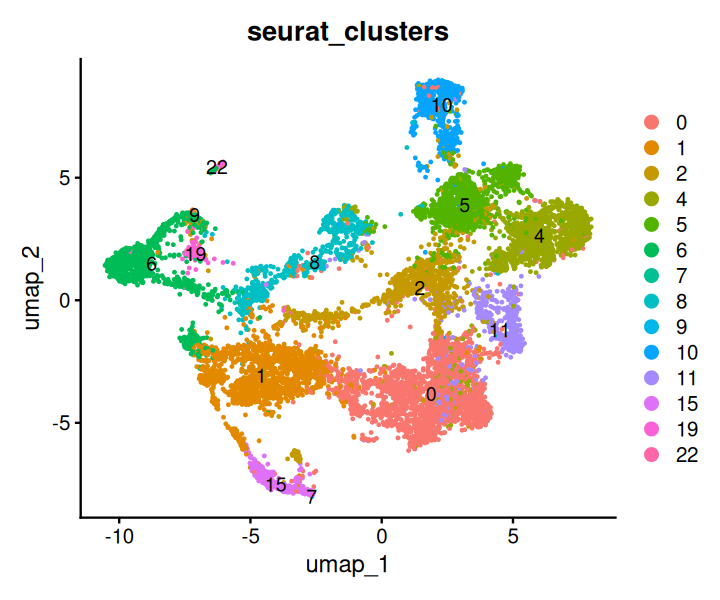

In [62]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(liyim_tcells, label = T, group.by = "seurat_clusters")

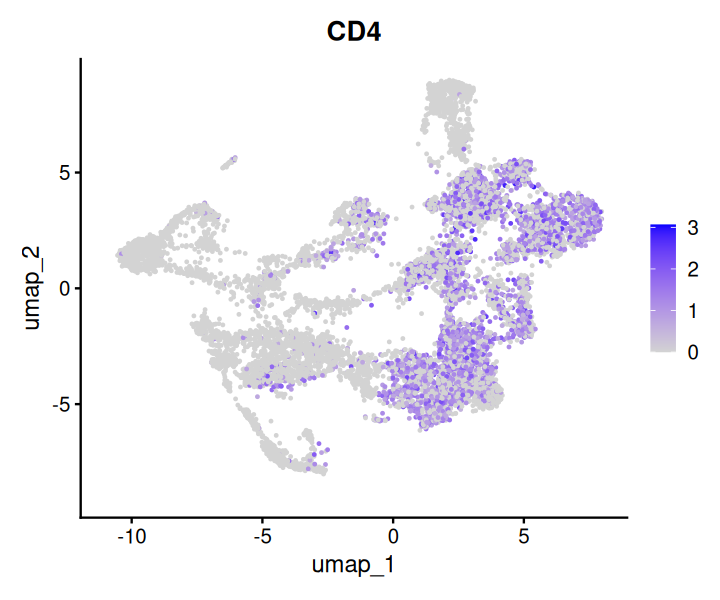

In [64]:
FeaturePlot(liyim_tcells, features = "CD4")

In [65]:
cd4_liyim  <- subset(liyim_tcells, seurat_clusters %in% c(0,2,4,5,11))

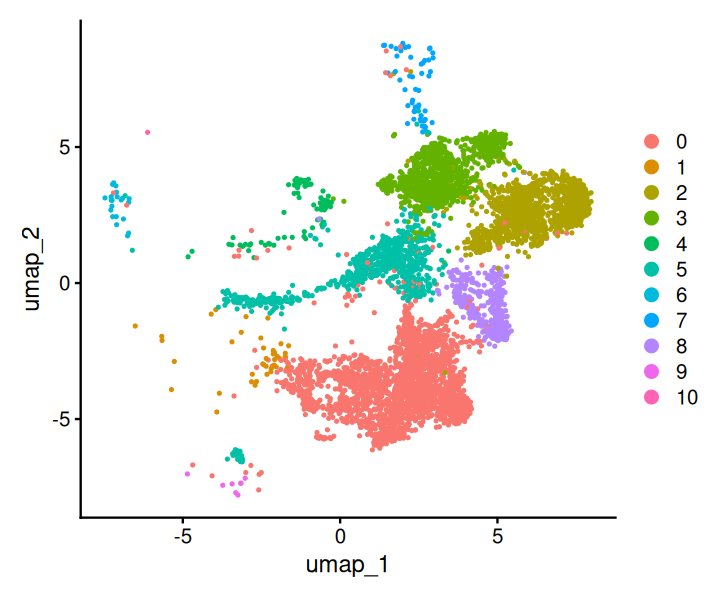

In [70]:
DimPlot(cd4_liyim)

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
PC_ 1 
Positive:  S100A4, SH3BGRL3, IL32, S100A10, CRIP1, S100A11, S100A6, NIBAN1, MYO1F, VIM 
	   CD52, B2M, TMSB4X, ITGB1, ANXA1, PFN1, GAPDH, ANXA2, LGALS1, ACTB 
	   AHNAK, ADAM19, FAU, ACTG1, TPT1, TMSB10, UBA52, SRGN, EEF1A1, ERN1 
Negative:  IGF1R, LEF1, BACH2, FHIT, CERS6, MAML2, TXK, PCSK5, APBA2, PLCL1 
	   MLLT3, AK5, TGFBR2, TSHZ2, MAN1C1, ITGA6, ATP10A, SFMBT2, FAM117B, RETREG1 
	   EDAR, CSGALNACT1, AFF3, ANKRD55, DENND5A, PITPNM2, ABLIM1, PDE3B, SLC16A10, NELL2 
PC_ 2 
Positive:  EEF1A1, NACA, EEF1B2, TPT1, FAU, UBA52, TMSB10, TMSB4X, LTB, B2M 
	   CD52, ACTG1, ACTB, VIM, PFN1, S100A6, GAPDH, SH3BGRL3, IL7R, SNHG5 
	   TRBC2, CRIP1, IL32, S100A10, JUNB, S100A4, S100A11, TRBC1, HIST1H1D, ANXA1 
Negative:  ZEB2, MYO1F, ATXN1, TGFBR3, PDGFD, NCALD, CHST11, AOAH, PPP2R2B, PARP8 
	 

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 6106
Number of edges: 239468

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9248
Number of communities: 6
Elapsed time: 0 seconds


13:13:46 UMAP embedding parameters a = 0.9922 b = 1.112

13:13:46 Read 6106 rows and found 30 numeric columns

13:13:46 Using Annoy for neighbor search, n_neighbors = 30

13:13:46 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

13:13:47 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpYlKnlC/file2da0d218c3f116

13:13:47 Searching Annoy index using 1 thread, search_k = 3000

13:13:49 Annoy recall = 100%

13:13:51 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

13:13:54 Initializing from normalized Laplacian + noise (using RSpectra)

13:13:54 Commencing optimization for 500 epochs, with 254968 positive edges

13:13:54 Using rng type: pcg

13:14:04 Optimization finished



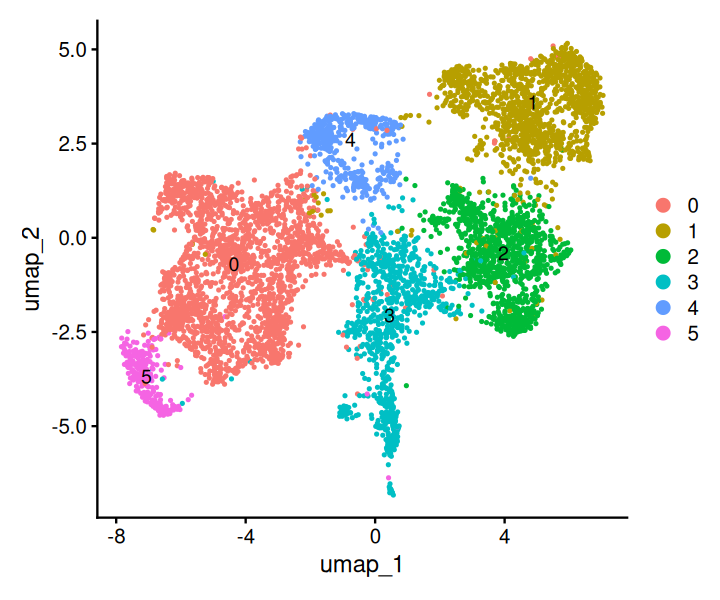

In [71]:

# Recompute normalization and variable genes
cd4_liyim <- NormalizeData(cd4_liyim)
cd4_liyim <- FindVariableFeatures(cd4_liyim, nfeatures = 2000)
cd4_liyim <- ScaleData(
  cd4_liyim,
  features = VariableFeatures(cd4_liyim)
)

# Recompute PCA, clustering, and UMAP
cd4_liyim <- RunPCA(cd4_liyim, npcs = 30)
cd4_liyim <- FindNeighbors(cd4_liyim, dims = 1:30)
cd4_liyim <- FindClusters(cd4_liyim, resolution = 0.2)
cd4_liyim <- RunUMAP(cd4_liyim, dims = 1:30, seed.use = 123)

DimPlot(cd4_liyim, reduction = "umap", label = TRUE)


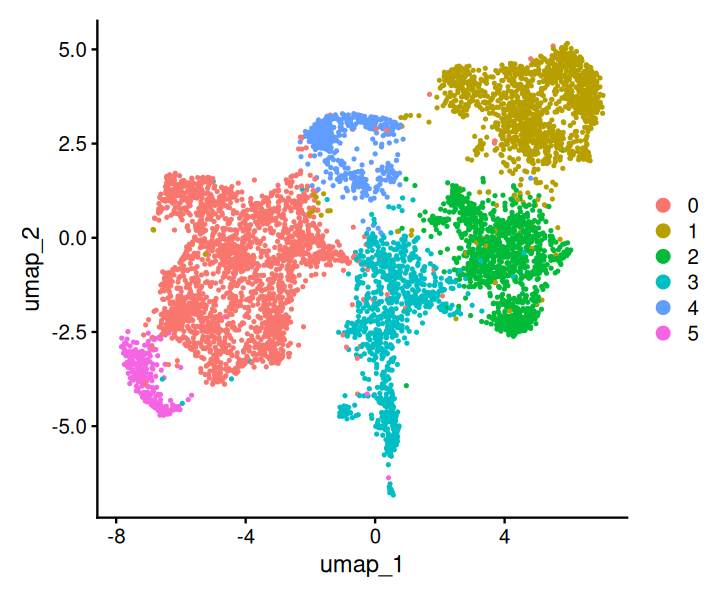

In [72]:
DimPlot(cd4_liyim)

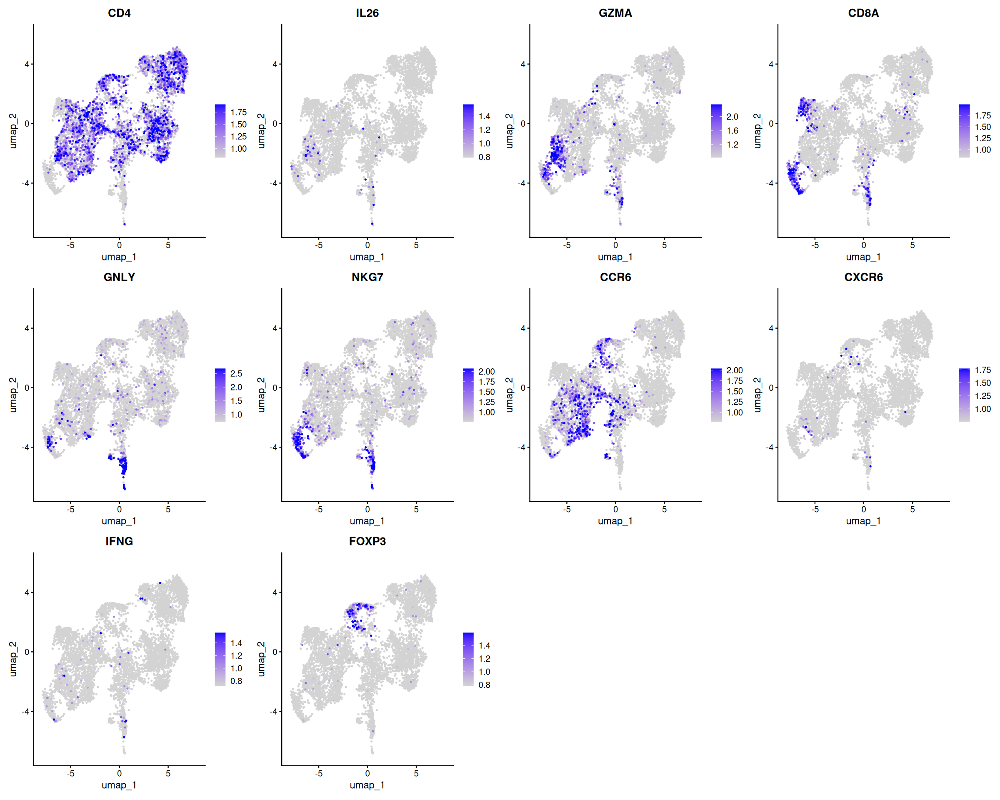

In [73]:
cd4_ctl_markers <- c(
  "CD4", "IL26", "GZMA",  
  "CD8A", "GNLY", "NKG7",  
  "CCR6", "CXCR6", "IFNG",    
  "FOXP3"
)

options(repr.plot.width = 20, repr.plot.height = 16)
FeaturePlot(
  cd4_liyim,
  features = cd4_ctl_markers,
  reduction = "umap",
  ncol = 4,
  order = TRUE,
  min.cutoff = "q10",
  max.cutoff = "q90")


In [ ]:
cd4_liyim <- FindClusters(cd4_liyim, resolution = c(0.3,0.4,0.5,0.6))


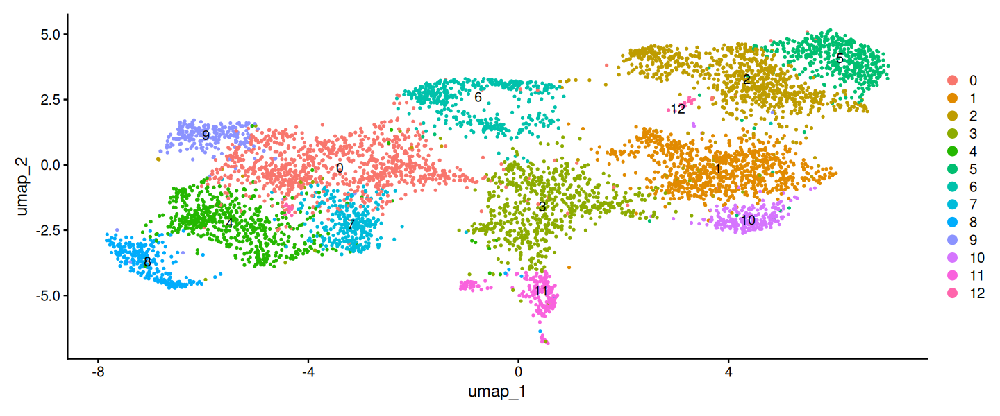

In [84]:
DimPlot(cd4_liyim, label = T)

In [85]:
cd4_liyim2  <- subset(cd4_liyim, seurat_clusters %in% c(0:7,10,12))

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Warning message:
“Different features in new layer data than already exists for scale.data”
PC_ 1 
Positive:  BACH2, IGF1R, LEF1, FHIT, MAML2, CERS6, TXK, APBA2, MLLT3, PCSK5 
	   TGFBR2, AK5, SFMBT2, ATP10A, PLCL1, ITGA6, TSHZ2, FAM117B, RETREG1, EDAR 
	   NELL2, AFF3, DENND5A, CSGALNACT1, PITPNM2, NR3C2, RBMS1, ANKRD55, ABLIM1, SLC16A10 
Negative:  S100A4, SH3BGRL3, S100A10, IL32, CRIP1, S100A6, S100A11, CD52, VIM, TMSB4X 
	   B2M, PFN1, GAPDH, MYL6, TMSB10, FAU, TPT1, ACTB, FTL, NIBAN1 
	   ANXA1, MYO1F, ACTG1, ITGB1, UBA52, ANXA2, EEF1A1, LTB, RACK1, NACA 
PC_ 2 
Positive:  ATXN1, CHST11, NIBAN1, MYO1F, PPP1R16B, TOX, RORA, MAP3K5, PHACTR2, ATP2B1 
	   SMAD3, MIAT, MGAT5, ADAM19, RAP1GAP2, MCF2L2, STAM, GPRIN3, CYTOR, PAM 
	   CDC14A, LRIG1, PTPRJ, IKZF2, RUNX2, KAT2B, CEP128, DLEU2, NCALD, AHNAK 
Negative:  EEF1B2, EEF1A1, EEF1G, NACA, FAU, UBA52, TPT1, RACK1, TMSB10, FTL 
	   

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5395
Number of edges: 217348

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9243
Number of communities: 5
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5395
Number of edges: 217348

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8824
Number of communities: 8
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5395
Number of edges: 217348

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8528
Number of communities: 10
Elapsed time: 0 seconds


13:37:10 UMAP embedding parameters a = 0.9922 b = 1.112

13:37:10 Read 5395 rows and found 30 numeric columns

13:37:10 Using Annoy for neighbor search, n_neighbors = 30

13:37:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

13:37:11 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpYlKnlC/file2da0d29cdf635

13:37:11 Searching Annoy index using 1 thread, search_k = 3000

13:37:13 Annoy recall = 100%

13:37:15 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

13:37:18 Initializing from normalized Laplacian + noise (using RSpectra)

13:37:18 Commencing optimization for 500 epochs, with 226458 positive edges

13:37:18 Using rng type: pcg

13:37:26 Optimization finished



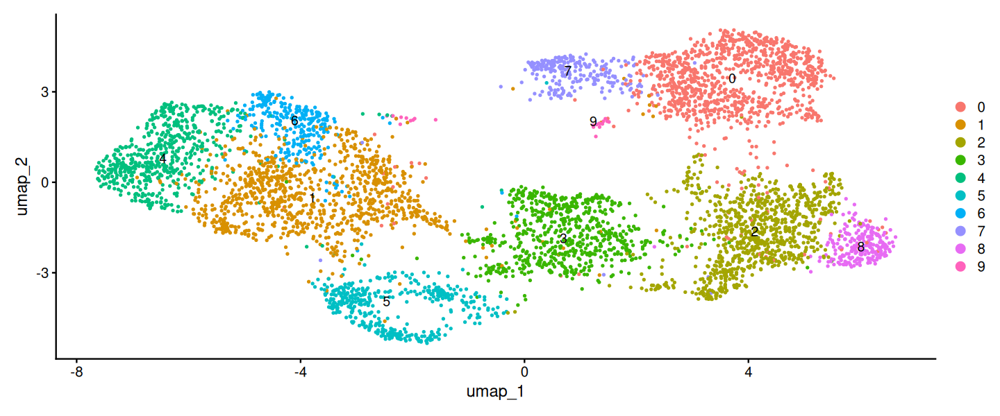

In [86]:

# Recompute normalization and variable genes
cd4_liyim2 <- NormalizeData(cd4_liyim2)
cd4_liyim2 <- FindVariableFeatures(cd4_liyim2, nfeatures = 2000)
cd4_liyim2 <- ScaleData(
  cd4_liyim2,
  features = VariableFeatures(cd4_liyim2)
)

# Recompute PCA, clustering, and UMAP
cd4_liyim2 <- RunPCA(cd4_liyim2, npcs = 30)
cd4_liyim2 <- FindNeighbors(cd4_liyim2, dims = 1:30)
cd4_liyim2 <- FindClusters(cd4_liyim2, resolution = c(0.2,0.4,0.6))
cd4_liyim2 <- RunUMAP(cd4_liyim2, dims = 1:30, seed.use = 123)

DimPlot(cd4_liyim2, reduction = "umap", label = TRUE)


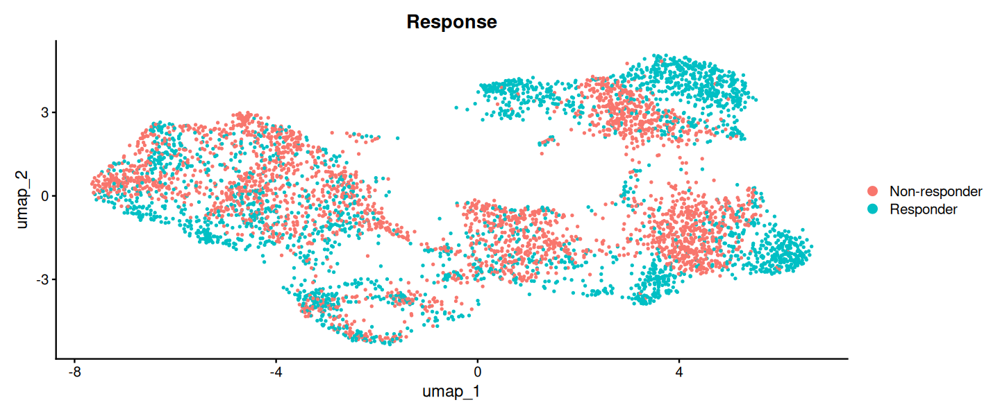

In [87]:
options(repr.plot.width = 12, repr.plot.height = 5)
DimPlot(cd4_liyim2, group.by = "Response")

In [ ]:
cd4_liyim2$`RNA_snn_res.0.3`

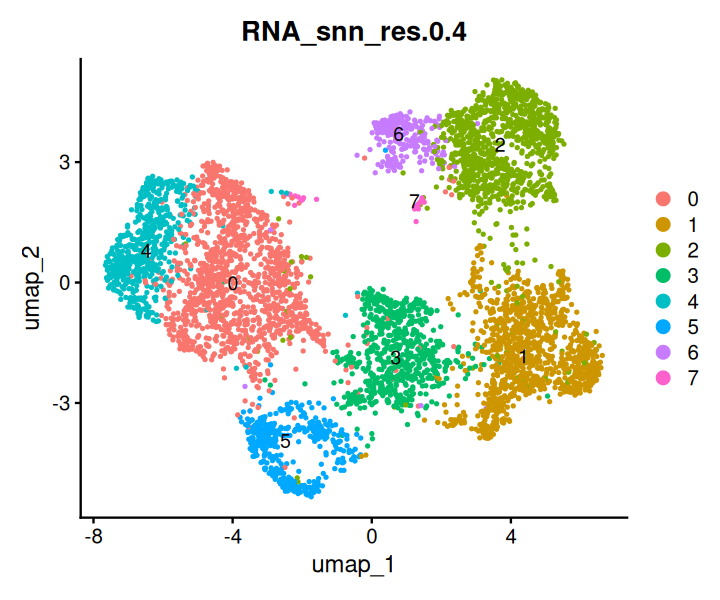

In [90]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(cd4_liyim2, reduction = "umap", label = TRUE, group.by = "RNA_snn_res.0.4")


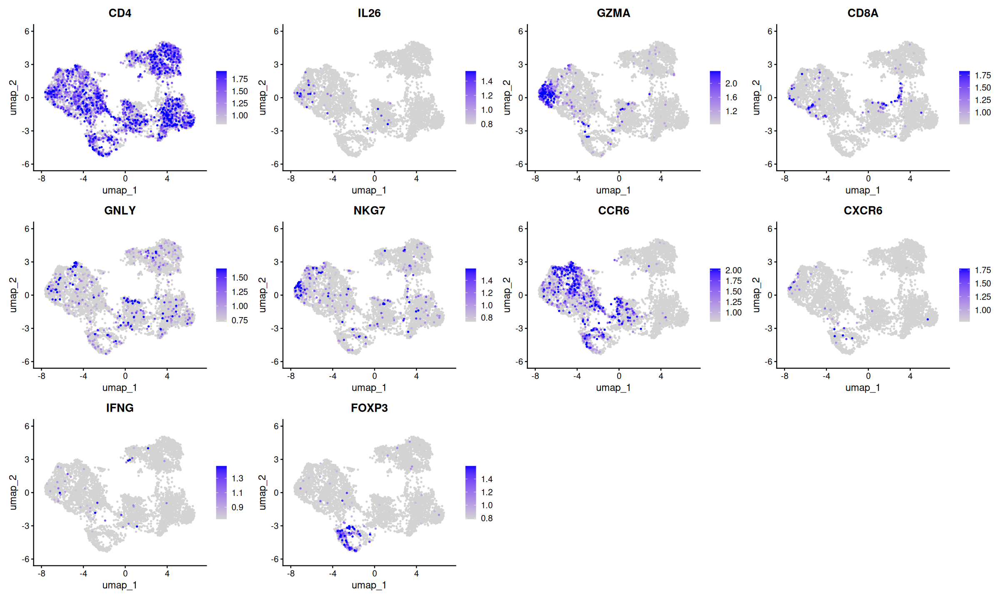

In [88]:
options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(
  cd4_liyim2,
  features = cd4_ctl_markers,
  reduction = "umap",
  ncol = 4,
  order = TRUE,
  min.cutoff = "q10",
  max.cutoff = "q90")


In [91]:
md <- cd4_liyim2@meta.data
df4 <- md %>% group_by(SampleID, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!SampleID, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(SampleID, Response) %>% unique()
df4  <- left_join(df4, md_to_join, by = "SampleID")


`summarise()` has grouped output by 'SampleID'. You can override using the
`.groups` argument.


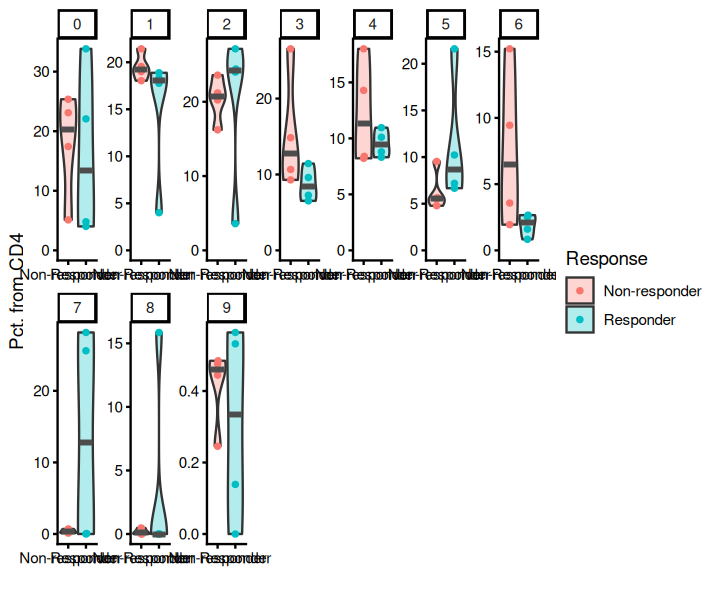

In [92]:
df4  %>% 
ggplot(aes(x = Response, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Response), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Response), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, scales = "free", ncol = 7) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + 
  theme_classic()